# FML 2026 Challenge — Analysis and Prediction over Bike Sharing Data

**Team Members:** AFFES Mohamed Amine, DIOUA Yasser, KPADENOU Soro, PETIT Gaëtan, SENGUPTA Soumik, WANG Mélina

## 0. Setup

In [148]:
import os

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import contextily as ctx
from getpass import getpass


from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.compose import ColumnTransformer
from sklearn.metrics import silhouette_score, adjusted_rand_score, mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from sklearn.utils import resample
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, RandomizedSearchCV, cross_validate
from sklearn.pipeline import Pipeline
import joblib


sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
DATA_DIR = os.environ.get("DATA_DIR", "../csv")

def rmse(y, p):
    return mean_squared_error(y, p) ** 0.5

## 1. Data Understanding and Exploration

### 1.1 Loading datasets

In [149]:
bike = pd.read_csv(f"{DATA_DIR}/bikes.csv")
types = pd.read_csv(f"{DATA_DIR}/bike_types.csv")
city = pd.read_csv(f"{DATA_DIR}/cities.csv")
station = pd.read_csv(f"{DATA_DIR}/stations.csv")
station_status = pd.read_csv(f"{DATA_DIR}/stations_status.csv")
trips = pd.read_csv(f"{DATA_DIR}/trips_small.csv")

The project contains six tables:
- bike: individual bicycles
- types: technical bike-type metadata
- city: bike-sharing schemes and their geographic metadata
- station: station metadata and capacity
- station_status: repeated station-state snapshots over time
- trips: individual journeys

### 1.2 Inventory of each table

In [150]:
def data_invent(data):
    """Shape, duplicates, dtypes, missing values, unique values, descriptive statistics."""

    inventory = pd.DataFrame({
        "Data type": data.dtypes,
        "Missing values": data.isna().sum(),
        "Missing value in %": data.isna().mean() * 100,
        "Unique values": data.nunique(),
    })

    print(f"Shape of the dataframe is : {data.shape}\n")
    print(f"The duplicate rows are : {data.duplicated().sum()}\n")
    display(inventory)

    print("\nThe descriptive statistics :")
    display(data.describe(include="all").T)

#### Bikes dataframe

In [151]:
data_invent(bike)

Shape of the dataframe is : (88436, 3)

The duplicate rows are : 0



,Data type,Missing values,Missing value in %,Unique values
id,int64,0,0.0,88436
bike_type_id,int64,0,0.0,121
computer_id,int64,0,0.0,72278



The descriptive statistics :


,count,mean,std,min,25%,50%,75%,max
id,88436.0,2.873477e+05,2.623808e+05,2204.0,4.503350e+04,2.240695e+05,4.852165e+05,9.984990e+05
bike_type_id,88436.0,1.306397e+02,6.863118e+01,0.0,7.100000e+01,1.500000e+02,1.960000e+02,2.540000e+02
computer_id,88436.0,6.533541e+09,8.500256e+09,0.0,7.551012e+09,7.551068e+09,7.551120e+09,7.551011e+11


* The dataset contains exactly 88,436 unique id values and zero duplicate rows.
* There are exactly 121 unique bike_type_id values. The dataframe has 0% missing values (NaNs) across all three columns.
* While there are 88,436 bikes, there are only 72,278 unique computer_ids. The descriptive statistics show the minimum computer_id is 0.0.

#### Bike types dataframe

In [152]:
data_invent(types)

Shape of the dataframe is : (121, 9)

The duplicate rows are : 0



,Data type,Missing values,Missing value in %,Unique values
id,int64,0,0.000000,121
vehicle_image,str,30,24.793388,91
name,str,30,24.793388,46
description,str,70,57.851240,40
form_factor,str,30,24.793388,3
rider_capacity,float64,30,24.793388,2
propulsion_type,str,30,24.793388,2
max_range,float64,106,87.603306,1
battery_capacity,float64,99,81.818182,4



The descriptive statistics :


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,121.0,NaN,NaN,NaN,134.454545,77.73845,0.0,72.0,149.0,201.0,254.0
vehicle_image,91,91,https://static.nextbike.net/app/biketypes/type...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
name,91,46,Rower z fotelikiem dziecięcym,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
description,51,40,"DOLLY BIKES ""e-Dolly"" MaxDrive\r\n\r\n - BAFAN...",6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
form_factor,91,3,bicycle,71,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rider_capacity,91.0,NaN,NaN,NaN,1.230769,0.423659,1.0,1.0,1.0,1.0,2.0
propulsion_type,91,2,human,64,NaN,NaN,NaN,NaN,NaN,NaN,NaN
max_range,15.0,NaN,NaN,NaN,60000.0,0.0,60000.0,60000.0,60000.0,60000.0,60000.0
battery_capacity,22.0,NaN,NaN,NaN,547.727273,61.638873,500.0,500.0,500.0,600.0,690.0


* The dataframe contains 121 records with exactly 121 unique id values and zero duplicate rows. We can use it as a primary key for joining with the bikes table.

* Exactly 30 rows (24.8%) are simultaneously missing fundamental attributes: vehicle_image, name, form_factor, rider_capacity, and propulsion_type. This can refer to unclassified or deleted bike configurations in the system. We will need to decide whether to impute these as "Unknown" or exclude them later.

* The high missing rates for battery_capacity (81.8%) and max_range (87.6%) are logical, as human-powered bikes do not possess these metrics. The descriptive statistics shows that the 15 non-null records for max_range all share the exact same value (60000.0).

* There is a strong many-to-one relationship in the types. While there are 121 technical ids, there are only 46 unique commercial names and 3 form_factors. This suggests that many technical IDs simply represent similar hardware of the same fundamental bike model.

* The descriptive statistics highlight that bikes are designed for either 1 or 2 riders, and the electric bikes utilize just four standard battery sizes ranging tightly between 500 Wh and 690 Wh.

In [153]:
for col in ["propulsion_type", "form_factor"]:
    print(col, "->", types[col].value_counts(dropna=False).to_dict())

propulsion_type -> {'human': 64, nan: 30, 'electric_assist': 27}
form_factor -> {'bicycle': 71, nan: 30, 'cargo_bicycle': 19, 'other': 1}


#### City dataframe

In [154]:
data_invent(city)

Shape of the dataframe is : (267, 7)

The duplicate rows are : 0



,Data type,Missing values,Missing value in %,Unique values
id,int64,0,0.0,267
name,str,0,0.0,267
lat,float64,0,0.0,264
lon,float64,0,0.0,266
timezone,str,0,0.0,9
country,str,0,0.0,15
return_to_official_only,bool,0,0.0,2



The descriptive statistics :


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,267.0,NaN,NaN,NaN,496.985019,232.77276,1.0,314.0,537.0,691.5,858.0
name,267,267,Zagreb,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lat,267.0,NaN,NaN,NaN,49.067596,4.155125,27.8154,47.82785,49.898,51.58975,57.6902
lon,267.0,NaN,NaN,NaN,12.154192,7.02984,-15.5182,8.30655,13.7446,16.8312,33.4535
timezone,267,9,Europe/Berlin,184,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,267,15,DE,91,NaN,NaN,NaN,NaN,NaN,NaN,NaN
return_to_official_only,267,2,True,200,NaN,NaN,NaN,NaN,NaN,NaN,NaN


* The dataframe contains 267 records with 0% missing values across all columns and no duplicate rows. Both id and name are primary identifiers for the bike-sharing schemes.

*  While there are 267 distinct scheme names, there are only 264 unique lat values and 266 unique lon values. This slight discrepancy confirms that some bike-sharing schemes share the exact same approximate city center coordinates.

* The return_to_official_only variable is a  boolean feature indicating whether bikes must be left at a station. This distinguishes between strictly station-based and free-floating setups.

* The network spans 15 distinct countries and 9 time zones. The bounding coordinates—from a latitude of 27.8° to 57.7° and a longitude of -15.5° to 33.4°—confirm a broad footprint encompassing diverse European urban environments.

#### Trips dataframe

In [155]:
data_invent(trips)

Shape of the dataframe is : (1161376, 13)

The duplicate rows are : 0



,Data type,Missing values,Missing value in %,Unique values
bike_id,int64,0,0.000000,26424
city_id,int64,0,0.000000,185
time_start,float64,0,0.000000,312677
lon_start,float64,0,0.000000,72638
lat_start,float64,0,0.000000,52706
lon_end,float64,0,0.000000,100802
lat_end,float64,0,0.000000,72880
station_id_start,float64,89215,7.681836,3675
station_id_end,float64,121904,10.496514,4432
battery_start,float64,992844,85.488593,101



The descriptive statistics :


,count,mean,std,min,25%,50%,75%,max
bike_id,1161376.0,2.265793e+05,1.996392e+05,3.346000e+03,5.962500e+04,8.881000e+04,4.001430e+05,8.400540e+05
city_id,1161376.0,5.179235e+02,2.374043e+02,7.000000e+00,3.310000e+02,5.480000e+02,7.170000e+02,8.580000e+02
time_start,1161376.0,1.676599e+09,9.407677e+06,1.661525e+09,1.666845e+09,1.678902e+09,1.685627e+09,1.689458e+09
lon_start,1161376.0,1.143184e+01,7.320269e+00,-1.560567e+01,7.165686e+00,1.019364e+01,1.745811e+01,3.398531e+01
lat_start,1161376.0,4.941432e+01,3.707710e+00,2.774058e+01,4.717771e+01,5.027373e+01,5.174006e+01,5.708158e+01
lon_end,1161376.0,1.143162e+01,7.320443e+00,-1.560567e+01,7.165686e+00,1.018726e+01,1.745811e+01,3.398632e+01
lat_end,1161376.0,4.941407e+01,3.708131e+00,2.774058e+01,4.717771e+01,5.026997e+01,5.173991e+01,5.708158e+01
station_id_start,1072161.0,4.223439e+07,4.759018e+07,9.400000e+01,5.669128e+06,2.072905e+07,7.251972e+07,2.192360e+08
station_id_end,1039472.0,4.236450e+07,4.793164e+07,9.400000e+01,5.445517e+06,1.982877e+07,7.279031e+07,2.146129e+08
battery_start,168532.0,8.098870e+01,2.138419e+01,0.000000e+00,6.600000e+01,8.900000e+01,1.000000e+02,1.000000e+02


* The dataset contains 1,161,376 total trip records. The core spatial coordinates (lon_start, lat_start, lon_end, lat_end), temporal data (time_start), and routing metrics (duration, distance) contain zero missing values, providing a highly reliable foundation for geospatial mapping and time-series aggregation.

* station_id_start is missing for 89,215 records and station_id_end is missing for 121,904 records. A NULL station ID indicates a free-floating start or end. They tell us whether a user utilized an official dock or left the bicycle in an ad-hoc location.

* The battery_start and battery_end variables are missing roughly 85% of the dataset (over 992,000 records). This high sparsity is due to the electric bicycles. For the electric subset, the median battery drain per trip is approximately 6%.

* The descriptive statistics reveal a median trip duration of 720 seconds (12 minutes) and a median distance of roughly 1,346 meters (1.35 km). However, the maximum duration extends to 28,740 seconds (nearly 8 hours) and the maximum distance to roughly 20 kilometers.

#### Station dataframe

In [156]:
data_invent(station)

Shape of the dataframe is : (2932, 11)

The duplicate rows are : 0



,Data type,Missing values,Missing value in %,Unique values
id,int64,0,0.000000,2932
city_id,int64,0,0.000000,185
name,str,0,0.000000,2855
app_number,int64,0,0.000000,2914
terminal_type,str,587,20.020464,10
place_type,int64,0,0.000000,16
bike_racks,int64,0,0.000000,33
special_racks,int64,0,0.000000,11
rack_locks,float64,2932,100.000000,0
lon,float64,0,0.000000,2912



The descriptive statistics :


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,2932.0,NaN,NaN,NaN,41160199.68588,47737638.319212,94.0,3604443.25,25317899.5,56610782.5,219235987.0
city_id,2932.0,NaN,NaN,NaN,480.171555,242.781001,7.0,251.0,527.0,702.0,858.0
name,2932,2855,Dworzec PKP,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN
app_number,2932.0,NaN,NaN,NaN,29985.9294,61868.290176,0.0,4918.75,7907.5,48798.25,999574.0
terminal_type,2345,10,sign,881,NaN,NaN,NaN,NaN,NaN,NaN,NaN
place_type,2932.0,NaN,NaN,NaN,3.760914,6.894175,0.0,0.0,0.0,0.0,27.0
bike_racks,2932.0,NaN,NaN,NaN,6.033424,6.495116,0.0,0.0,6.0,10.0,70.0
special_racks,2932.0,NaN,NaN,NaN,-0.011255,0.48682,-10.0,0.0,0.0,0.0,12.0
rack_locks,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lon,2932.0,NaN,NaN,NaN,13.172182,6.91427,-15.758277,8.156823,14.314387,17.488668,33.413632


* The id column contains exactly 2,932 unique values for the 2,932 rows, functioning as a perfect primary key. However, there are only 2,855 unique station names, indicating that approximately 77 stations share names.

* The rack_locks column is entirely empty (NaN), meaning it provides zero predictive value and should be dropped during preprocessing. Furthermore, the terminal_type (indicating hardware generation) is missing for 587 stations (~20%).

* The descriptive statistics reveal a large portion of stations (1,220 out of 2,932) have exactly 0 bike_racks. This implies that these are not physical docks, but rather virtual stations or designated geofenced parking zones for free-floating setups.

* The presence of special_racks (charging docks) shows a heavy positive skew, with the vast majority of stations having 0 (up through the 75th percentile), but a maximum of 12.

#### Station status dataframe

In [157]:
data_invent(station_status)

Shape of the dataframe is : (2925967, 8)

The duplicate rows are : 0



,Data type,Missing values,Missing value in %,Unique values
station_id,int64,0,0.0,2899
time,float64,0,0.0,392858
bikes,int64,0,0.0,185
booked_bikes,int64,0,0.0,40
bikes_available_to_rent,int64,0,0.0,185
free_racks,int64,0,0.0,68
free_special_racks,int64,0,0.0,38
maintenance,bool,0,0.0,2



The descriptive statistics :


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
station_id,2925967.0,NaN,NaN,NaN,40847532.8712,46421829.121576,94.0,6215911.0,19489795.0,59198047.0,219235987.0
time,2925967.0,NaN,NaN,NaN,1676530748.342377,9488314.781911,1661525281.0,1666616341.0,1678896961.0,1685642522.0,1689458341.0
bikes,2925967.0,NaN,NaN,NaN,6.186521,6.091899,0.0,3.0,5.0,8.0,189.0
booked_bikes,2925967.0,NaN,NaN,NaN,0.045999,0.402517,-4.0,0.0,0.0,0.0,38.0
bikes_available_to_rent,2925967.0,NaN,NaN,NaN,6.141577,6.099811,0.0,2.0,5.0,8.0,189.0
free_racks,2925967.0,NaN,NaN,NaN,5.0309,5.300172,0.0,0.0,4.0,8.0,70.0
free_special_racks,2925967.0,NaN,NaN,NaN,2.216036,4.342693,0.0,0.0,0.0,3.0,37.0
maintenance,2925967,2,False,2795425,NaN,NaN,NaN,NaN,NaN,NaN,NaN


* With nearly 2.93 million snapshot records and absolutely zero null values across all eight columns.

* The time column is currently stored as a float64 UNIX timestamp. To make this useful it must be converted into Pandas datetime objects to find cyclical features such as hour-of-day, day-of-week, and weekday-vs-weekend.

*  The descriptive statistics show massive variance in station scale. While the median station has 4 free racks and 5 bikes available, the maximums stretch to 70 free racks and 189 available bikes.

* The maintenance boolean flag indicates if a station is offline.

### 1.3 Relationships between tables

In [158]:
primary_key_checks = pd.DataFrame({
    "table": ["bike", "types", "city", "station"],
    "key": ["id", "id", "id", "id"],
    "rows": [len(bike), len(types), len(city), len(station)],
    "unique_key_values": [
        bike["id"].nunique(),
        types["id"].nunique(),
        city["id"].nunique(),
        station["id"].nunique()
    ],
})
primary_key_checks["unique_key"] = primary_key_checks["rows"] == primary_key_checks["unique_key_values"]
display(primary_key_checks)

,table,key,rows,unique_key_values,unique_key
0,bike,id,88436,88436,True
1,types,id,121,121,True
2,city,id,267,267,True
3,station,id,2932,2932,True


In [159]:
def fk_check(child, child_col, parent, parent_col, label, allow_null=False):
    values = child[child_col]
    if allow_null:
        values = values.dropna()
    matched = values.isin(parent[parent_col])
    return {
        "relationship": label,
        "checked_values": len(values),
        "matched": int(matched.sum()),
        "unmatched": int((~matched).sum()),
        "match_percent": round(matched.mean() * 100, 3) if len(values) else np.nan
    }

fk_results = pd.DataFrame([
    fk_check(bike, "bike_type_id", types, "id", "bikes.bike_type_id -> bike_types.id"),
    fk_check(station, "city_id", city, "id", "stations.city_id -> cities.id"),
    fk_check(station_status, "station_id", station, "id", "station_status.station_id -> stations.id"),
    fk_check(trips, "bike_id", bike, "id", "trips.bike_id -> bikes.id"),
    fk_check(trips, "city_id", city, "id", "trips.city_id -> cities.id"),
    fk_check(trips, "station_id_start", station, "id", "trips.station_id_start -> stations.id", allow_null=True),
    fk_check(trips, "station_id_end", station, "id", "trips.station_id_end -> stations.id", allow_null=True),
])
display(fk_results)

,relationship,checked_values,matched,unmatched,match_percent
0,bikes.bike_type_id -> bike_types.id,88436,88436,0,100.000
1,stations.city_id -> cities.id,2932,2932,0,100.000
2,station_status.station_id -> stations.id,2925967,2925967,0,100.000
3,trips.bike_id -> bikes.id,1161376,1161376,0,100.000
4,trips.city_id -> cities.id,1161376,1161376,0,100.000
5,trips.station_id_start -> stations.id,1072161,1055459,16702,98.442
6,trips.station_id_end -> stations.id,1039472,963433,76039,92.685


In [160]:
stations_without_status = set(station["id"]) - set(station_status["station_id"])
status_station_ids_not_in_metadata = set(station_status["station_id"]) - set(station["id"])

print("Stations in metadata:", station["id"].nunique())
print("Stations represented in status:", station_status["station_id"].nunique())
print("Stations with no status observations:", len(stations_without_status))
print("Status station IDs absent from station metadata:", len(status_station_ids_not_in_metadata))

Stations in metadata: 2932
Stations represented in status: 2899
Stations with no status observations: 33
Status station IDs absent from station metadata: 0


### 1.4 Bikes and bike types

In [161]:
print("Number of individual bikes:", bike["id"].nunique())
print("Number of unique bike types:", types["id"].nunique())

Number of individual bikes: 88436
Number of unique bike types: 121


##### Distribution of bikes per type

In [162]:
bike_profile = bike.merge(
    types[["id", "name", "propulsion_type", "form_factor", "rider_capacity", "battery_capacity", "max_range"]],
    left_on="bike_type_id",
    right_on="id",
    how="left",
    validate="many_to_one",
    indicator=True,
    suffixes=("_bike", "_type")
)
display(bike_profile["_merge"].value_counts())

_merge
both          88436
left_only         0
right_only        0
Name: count, dtype: int64

In [163]:
bike_distribution = (
    bike_profile.groupby(["name", "propulsion_type"], dropna=False)
    .agg(
        individual_bikes=("id_bike", "count"),
        technical_type_ids=("bike_type_id", "nunique")
    )
    .sort_values("individual_bikes", ascending=False)
)
display(bike_distribution.head(20))

,,individual_bikes,technical_type_ids
name,propulsion_type,,
with Framelock,human,41691,4
SMARTbike 2.0 (A) 2018,human,13375,1
with Fork lock,human,7227,1
CLASSICbike,human,5108,1
Comfort,human,4756,1
E-Bike,electric_assist,2729,4
3-rychlostní SMARTbike 2.0.,human,2547,3
Comfort 1 1/8 Zoll,human,1607,1
8-rychlostní SMARTbike,human,1558,2


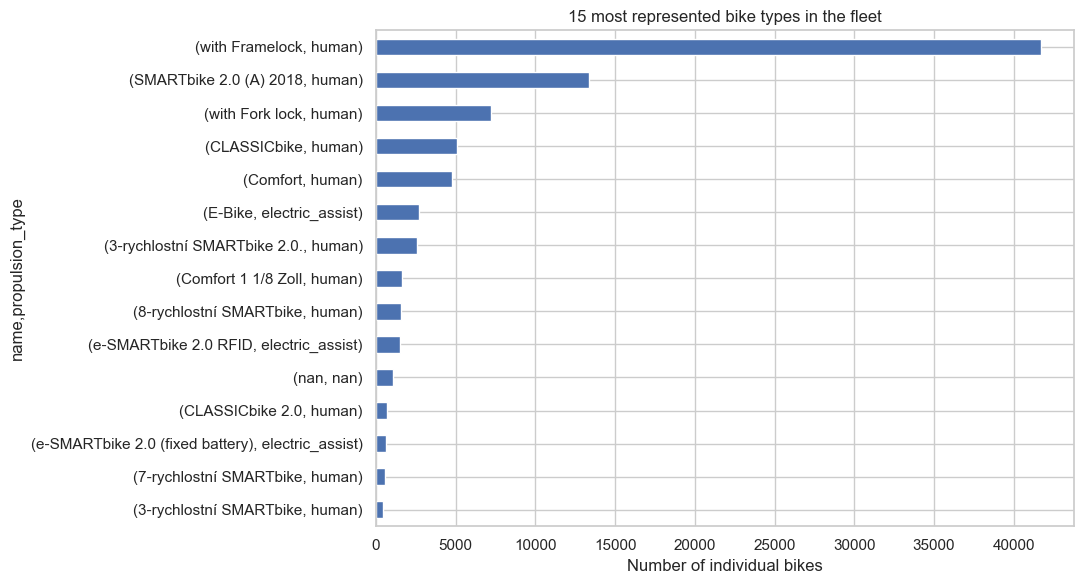

In [164]:
plt.figure(figsize=(11, 6))
bike_distribution.head(15)["individual_bikes"].sort_values().plot(kind="barh")
plt.title("15 most represented bike types in the fleet")
plt.xlabel("Number of individual bikes")
plt.tight_layout()
plt.show()

##### Bike type characteristics

In [165]:
display(types.groupby("propulsion_type", dropna=False).agg(
    type_records=("id", "count"),
    unique_names=("name", "nunique"),
    non_missing_battery=("battery_capacity", "count"),
    non_missing_range=("max_range", "count"),
    battery_values=("battery_capacity", lambda x: sorted(x.dropna().unique().tolist())),
    range_values=("max_range", lambda x: sorted(x.dropna().unique().tolist()))
))

,type_records,unique_names,non_missing_battery,non_missing_range,battery_values,range_values
propulsion_type,,,,,,
electric_assist,27,12,22,15,"[500.0, 600.0, 630.0, 690.0]",[60000.0]
human,64,34,0,0,[],[]
NaN,30,0,0,0,[],[]


In [166]:
types["form_factor"].value_counts(dropna=False).sort_index()

form_factor
bicycle          71
cargo_bicycle    19
other             1
NaN              30
Name: count, dtype: int64

In [167]:
types["rider_capacity"].value_counts(dropna=False).sort_index()

rider_capacity
1.0    70
2.0    21
NaN    30
Name: count, dtype: int64

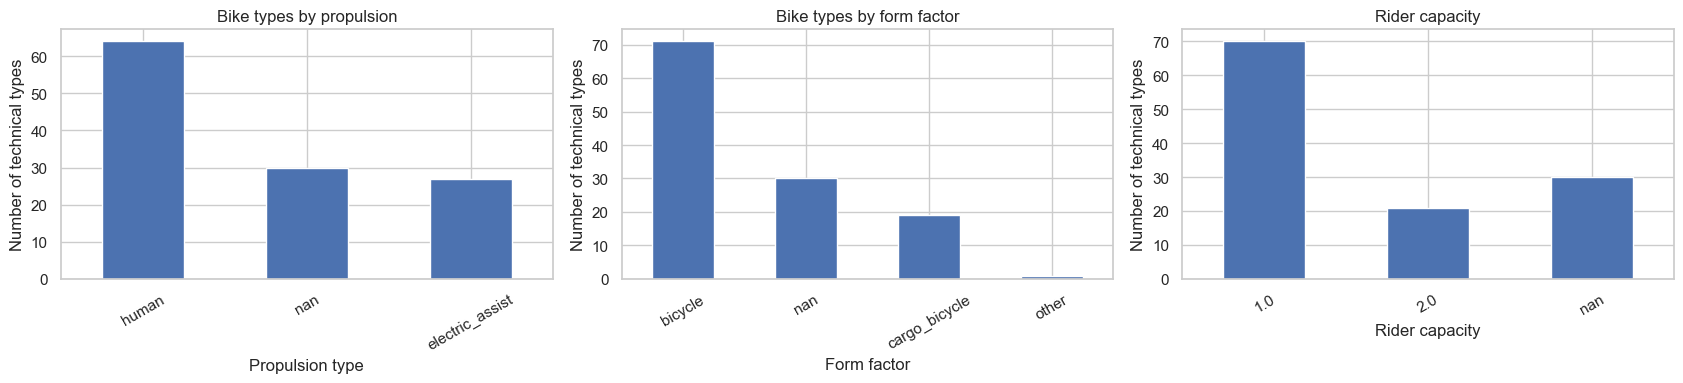

In [168]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
types["propulsion_type"].value_counts(dropna=False).plot(kind="bar", ax=axes[0], title="Bike types by propulsion")
types["form_factor"].value_counts(dropna=False).plot(kind="bar", ax=axes[1], title="Bike types by form factor")
types["rider_capacity"].value_counts(dropna=False).sort_index().plot(kind="bar", ax=axes[2], title="Rider capacity")

axes[0].set_xlabel("Propulsion type")
axes[1].set_xlabel("Form factor")
axes[2].set_xlabel("Rider capacity")

for ax in axes:
    ax.set_ylabel("Number of technical types")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

In [169]:
# Identifies the most reused names across different technical IDs.
name_reuse = (
    types.groupby("name", dropna=False)
    .agg(
        technical_ids=("id", "nunique"),
        propulsion_types=("propulsion_type", lambda x: x.nunique(dropna=False)),
        form_factors=("form_factor", lambda x: x.nunique(dropna=False))
    )
    .sort_values("technical_ids", ascending=False)
)
display(name_reuse.head(20))

,technical_ids,propulsion_types,form_factors
name,,,
NaN,30,1,1
Rower z fotelikiem dziecięcym,10,1,1
e-Cargobike,7,1,1
Tandem,7,1,1
Rowerek dziecięcy 6+,5,1,1
e-CARGObike,5,1,1
E-Bike,4,1,1
Cargo,4,1,1
with Framelock,4,1,1


* The 88,436 bikes span 121 types, but distribution is highly concentrated: 47% are simply named `with Framelock`. Many names describe hardware features rather than actual bike types

* 30 technical types (about 25%) lack specifications, covering 1,050 bikes (plus 253 named Unknown). We keep them as they are referenced in trip data

* Commercial names are often shared across multiple technical IDs (10 for `Rower z fotelikiem dziecięcym`), and identical bike types appear under various spellings and languages, so the raw name column requires cleaning before being used as a category

* As expected, battery capacity and range are only recorded for electric models

### 1.5 Cities

country
DE    91
PL    53
CZ    25
AT    24
HR    19
ES    16
CH    13
SI    10
GB     9
CY     2
MT     1
SK     1
SE     1
IT     1
LV     1
Name: count, dtype: int64

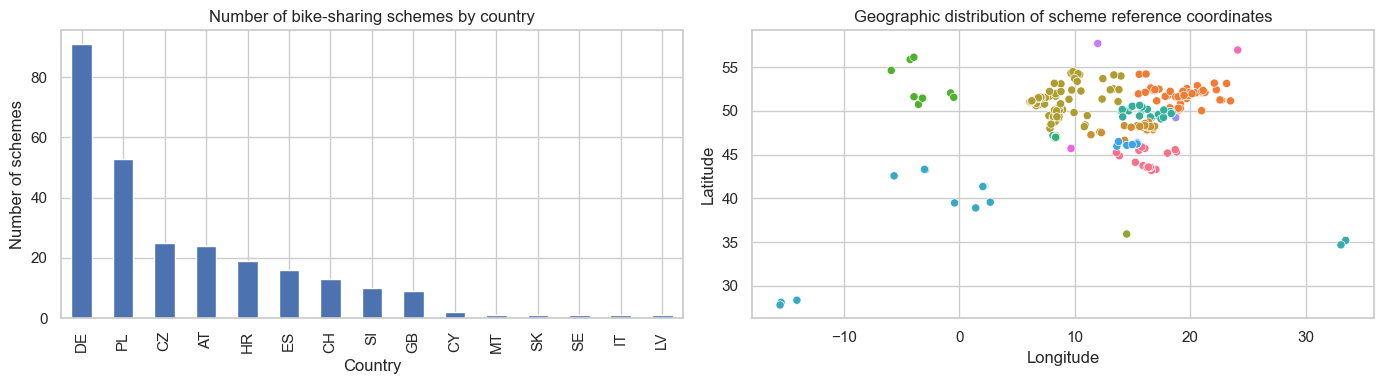

In [170]:
country_counts = city["country"].value_counts()
display(country_counts)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
country_counts.plot(kind="bar", ax=axes[0], title="Number of bike-sharing schemes by country", xlabel="Country", ylabel="Number of schemes")
sns.scatterplot(data=city, x="lon", y="lat", hue="country", legend=False, s=35, ax=axes[1])

axes[1].set_title("Geographic distribution of scheme reference coordinates")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")

plt.tight_layout()
plt.show()

country
DE    91
PL    53
CZ    25
AT    24
HR    19
ES    16
CH    13
SI    10
GB     9
CY     2
MT     1
SK     1
SE     1
IT     1
LV     1
Name: count, dtype: int64

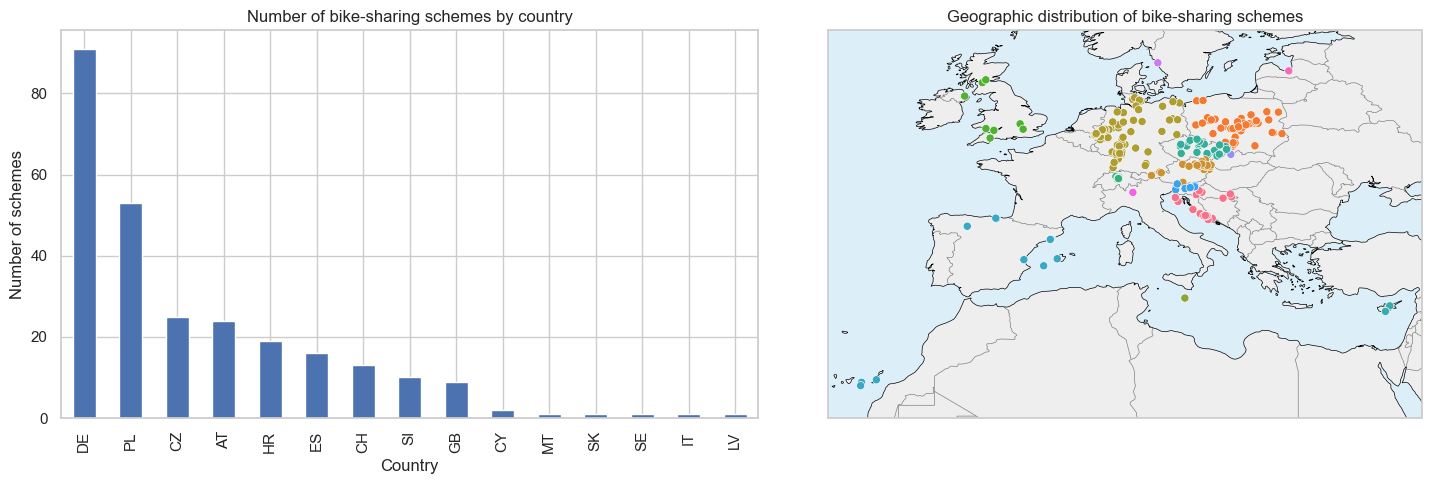

In [171]:
country_counts = city["country"].value_counts()
display(country_counts)

# Display the number of bike-sharing schemes by country and their geographic distribution on a map.
fig = plt.figure(figsize=(15, 5))

# First graph: number of bike-sharing schemes by country
ax1 = fig.add_subplot(1, 2, 1)

country_counts.plot(
    kind="bar",
    ax=ax1,
    title="Number of bike-sharing schemes by country",
    xlabel="Country",
    ylabel="Number of schemes"
)

# Second graph: geographic distribution map use of Cartopy for better visualization
ax2 = fig.add_subplot(
    1, 2, 2,
    projection=ccrs.PlateCarree()
)

# Add map features
ax2.add_feature(cfeature.LAND, facecolor="#eeeeee")
ax2.add_feature(cfeature.OCEAN, facecolor="#dceef7")
ax2.add_feature(cfeature.BORDERS, edgecolor="gray", linewidth=0.5)
ax2.add_feature(cfeature.COASTLINE, linewidth=0.5)

# Plot the geographic distribution of bike-sharing schemes
sns.scatterplot(data=city,x="lon",y="lat",hue="country",legend=False,s=35,ax=ax2,transform=ccrs.PlateCarree(),zorder=3)

# We set the extent of the map to see the distribution of bike-sharing schemes more clearly, here it will be a map of Europe
ax2.set_extent(
    [
        city["lon"].min() - 3,
        city["lon"].max() + 3,
        city["lat"].min() - 3,
        city["lat"].max() + 3
    ],
    crs=ccrs.PlateCarree()
)

ax2.set_title("Geographic distribution of bike-sharing schemes")

plt.tight_layout()
plt.show()

In [172]:
print("Unique schemes:", city["id"].nunique())
print("Unique countries:", city["country"].nunique())
print("Unique time zones:", city["timezone"].nunique())
print("Coordinate pairs shared by several schemes:", int((city.groupby(["lat", "lon"]).size() > 1).sum()))

Unique schemes: 267
Unique countries: 15
Unique time zones: 9
Coordinate pairs shared by several schemes: 1


In [173]:
display(city[(city["lat"] == 51.2469) & (city["lon"] == 22.56970)])

,id,name,lat,lon,timezone,country,return_to_official_only
35,251,Lublin,51.2469,22.5697,Europe/Warsaw,PL,True
241,729,Stacje Sponsorskie Nextbike LRM,51.2469,22.5697,Europe/Warsaw,PL,True


Both records have the same approximate city-centre coordinates, but they represent separate scheme records. This is not necessarily a duplicate or an error. It could be two schemes operating in the same geographical area

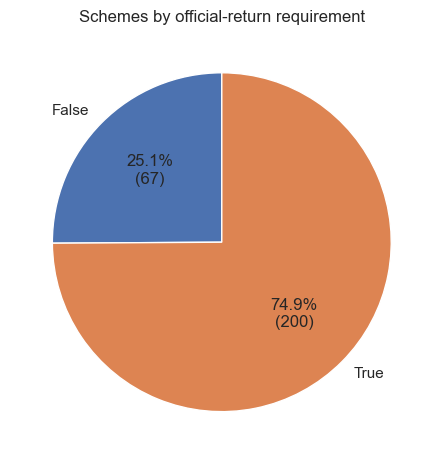

In [174]:
rto_counts = city["return_to_official_only"].value_counts().sort_index()
rto_counts.plot(
    kind="pie",
    autopct=lambda p: f"{p:.1f}%\n({int(round(p * rto_counts.sum() / 100))})",
    startangle=90,
    ylabel="",
)
plt.title("Schemes by official-return requirement")
plt.tight_layout()
plt.show()

* In total, there are 267 schemes in 15 different countries, and 9 different timezone. Germany is the country that has the more schemes (91).

* 200 out of 267 schemes (about 75%) require bikes to be returned to an official station, the other 67 allow free-floating returns.

### 1.6 Stations and their infrastructure

In [175]:
print("Number of stations:", station["id"].nunique())

Number of stations: 2932


In [176]:
display(pd.DataFrame(station["name"].value_counts()))
display(pd.DataFrame(station["terminal_type"].value_counts()))
display(pd.DataFrame(station["place_type"].value_counts()))

,count
name,
Dworzec PKP,11
Bahnhof,9
Rathaus,5
Rynek,5
Hauptbahnhof,4
...,...
Mežaparks,1
PKP Świder,1
Rheydt Hauptbahnhof,1


,count
terminal_type,
sign,881
7inch,386
stele,329
free,276
smart_sign,162
traffic_sign,156
character,113
mmt,25
pult,14


,count
place_type,
0,2229
14,269
17,182
19,87
16,64
21,39
6,24
7,12
18,9


In [177]:
display(pd.DataFrame(station.groupby('terminal_type')['bike_racks'].count()))
display(pd.DataFrame(station.groupby(['bike_racks','terminal_type']).size()))

,bike_racks
terminal_type,
7inch,386
character,113
free,276
mmt,25
pult,14
sign,881
smart_sign,162
stele,329
terminal_sleek,3


0
bike_racks terminal_type     
0          7inch           11
           character        1
           free           229
           sign           255
           smart_sign      96
...                       ...
30         sign             1
36         sign             1
40         stele            2
56         sign             1
70         stele            2

[136 rows x 1 columns]

In [178]:
repeated_station_names = (
    station[station["name"].duplicated(keep=False)]
    .sort_values(["name", "city_id", "id"])
)

display(repeated_station_names[["id", "city_id", "name", "lon", "lat"]].head(20))

,id,city_id,name,lon,lat
293,72519774,431,Aquapark,18.102240,51.756890
1905,42613441,702,Aquapark,17.472689,49.066874
2794,16732370,523,Armii Krajowej,20.628990,52.872230
1514,10195053,562,Armii Krajowej,19.806997,51.740299
1527,10279700,564,Armii Krajowej,19.949966,52.114787
2362,29079072,220,Autobusni kolodvor,15.993288,45.804404
1014,2687297,248,Autobusni kolodvor,15.893569,43.731453
1200,687108,327,Autobusni kolodvor,15.241245,44.106828
137,61868135,747,BASF Agrarzentrum Limburgerhof,8.394231,49.413186
1140,120938456,747,BASF Agrarzentrum Limburgerhof,8.394670,49.412847


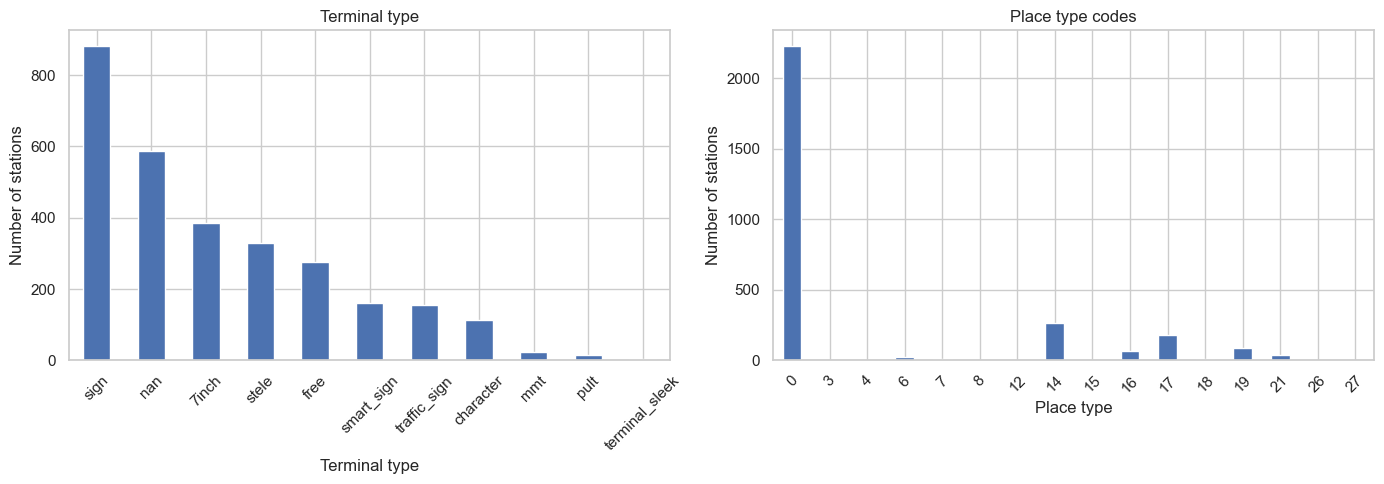

In [179]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

station["terminal_type"].value_counts(dropna=False).plot(
    kind="bar",
    ax=axes[0],
    title="Terminal type",
    xlabel="Terminal type"
)

station["place_type"].value_counts(dropna=False).sort_index().plot(
    kind="bar",
    ax=axes[1],
    title="Place type codes",
    xlabel="Place type"
)

for ax in axes:
    ax.set_ylabel("Number of stations")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [180]:
display(pd.crosstab(station["bike_racks"], station["terminal_type"]))

terminal_type,7inch,character,free,mmt,pult,sign,smart_sign,stele,terminal_sleek,traffic_sign
bike_racks,,,,,,,,,,
0,11,1,229,0,0,255,96,20,0,130
1,0,0,0,0,0,1,0,1,0,0
2,2,0,0,0,0,1,2,3,0,0
3,2,1,2,0,0,6,0,2,0,3
4,20,4,14,0,3,25,9,21,0,0
5,10,1,18,1,5,66,0,4,0,1
6,62,12,2,0,2,56,23,72,1,14
7,1,0,3,17,0,6,1,7,0,0
8,29,15,2,4,0,43,8,44,0,5


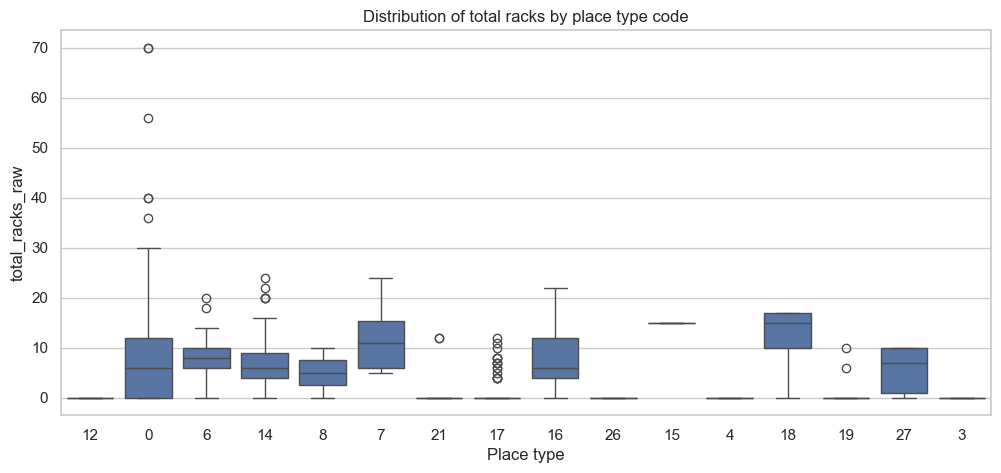

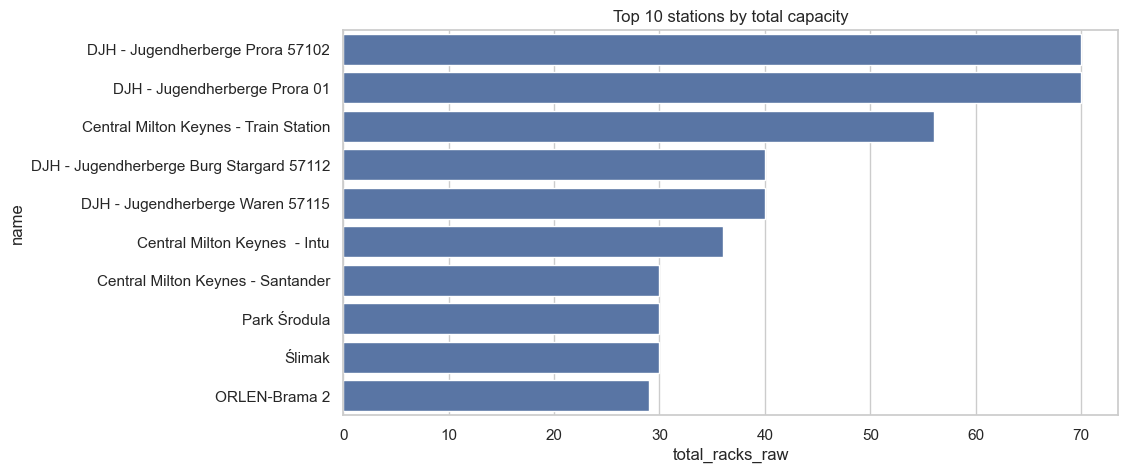

In [181]:
station["total_racks_raw"] = station["bike_racks"] + station["special_racks"]
plt.figure(figsize=(12, 5))
sns.boxplot(data=station, x=station["place_type"].astype(str), y="total_racks_raw")
plt.title("Distribution of total racks by place type code")
plt.xlabel("Place type")
plt.show()

top_stations = station.sort_values("total_racks_raw", ascending=False).head(10)
plt.figure(figsize=(10, 5))
sns.barplot(data=top_stations, x="total_racks_raw", y="name")
plt.title("Top 10 stations by total capacity")
plt.show()

##### Regular and Special Rack Capacity

In [182]:
station[['bike_racks','special_racks']]

,bike_racks,special_racks
0,0,0
1,6,0
2,15,0
3,20,0
4,6,0
...,...,...
2927,11,0
2928,10,0
2929,9,0
2930,4,0


In [183]:
station['bike_racks'].value_counts()

bike_racks
0     1220
6      276
15     263
10     257
12     249
8      162
5      115
4      102
7       47
20      37
14      37
16      28
9       19
22      18
3       17
24      14
18      14
11      12
13      10
2        8
17       5
19       5
30       3
70       2
40       2
1        2
21       2
29       1
25       1
36       1
56       1
26       1
27       1
Name: count, dtype: int64

In [184]:
print("Stations with 0 regular racks:", int((station["bike_racks"] == 0).sum()), "/", len(station))
print("Stations with negative special_racks:", int((station["special_racks"] < 0).sum()))
print("Missing coordinates:", int(station[["lon", "lat"]].isna().any(axis=1).sum()))

Stations with 0 regular racks: 1220 / 2932
Stations with negative special_racks: 32
Missing coordinates: 0


In [185]:
# Negative special_racks values
display(station[station["special_racks"] < 0])

,id,city_id,name,app_number,terminal_type,place_type,bike_racks,special_racks,rack_locks,lon,lat,total_racks_raw
455,19772006,643,Večgeneracijski center,3282,7inch,14,6,-2,NaN,15.382405,46.380096,4
974,21257660,220,Eurospin Branimirova,2319,7inch,14,6,-2,NaN,16.043296,45.818237,4
982,60833931,220,Matrix Office Park,2359,7inch,14,10,-4,NaN,16.012638,45.796928,6
1202,16852569,327,Kolovare,2390,7inch,14,2,-1,NaN,15.235639,44.104679,1
1311,40538270,415,Poštarska ulica - Pošta,2367,7inch,14,10,-4,NaN,16.048545,45.718726,6
1326,3561904,429,Brulo,2454,7inch,14,20,-10,NaN,13.595022,45.214403,10
1329,3562085,429,Špadići,2450,7inch,14,10,-5,NaN,13.599524,45.240682,5
1439,122952272,555,Levec,5958,7inch,14,6,-2,NaN,15.220656,46.241253,4
1440,19772105,644,Mizarska cesta,3284,7inch,14,6,-2,NaN,15.424421,46.334764,4
1441,19772115,644,Gimnazija Slovenske Konjice,3285,7inch,14,6,-2,NaN,15.417756,46.337155,4


In [186]:
# Zero Rack Stations
display(station[station['bike_racks'] == 0])
print("Terminal types for stations with 0 regular racks:", station[station['bike_racks'] == 0]['terminal_type'].value_counts())

,id,city_id,name,app_number,terminal_type,place_type,bike_racks,special_racks,rack_locks,lon,lat,total_racks_raw
0,142186362,135,BIKE 500100,0,NaN,12,0,0,NaN,7.821669,51.677449,0
10,110473405,629,FORMENTERA,3865,NaN,0,0,0,NaN,1.434906,38.912460,0
12,130175397,184,Gmünd / WK,355300,NaN,0,0,0,NaN,14.979298,48.768507,0
14,81369035,134,Wissenschaftspark Gelsenkirchen,7580,free,0,0,0,NaN,7.107439,51.497658,0
15,75832440,767,Lipůvka,48537,sign,0,0,0,NaN,16.552767,49.339050,0
...,...,...,...,...,...,...,...,...,...,...,...,...
2917,149878288,794,Borsteler Weg,2180,free,0,0,0,NaN,10.214882,53.348598,0
2920,4775113,7,Herderstraße,5187,free,0,0,0,NaN,8.233523,50.074514,0
2925,78685267,768,ZOO,49039,NaN,0,0,0,NaN,15.799026,50.435022,0
2926,104996679,768,Sylvárov,49054,NaN,0,0,0,NaN,15.814112,50.418406,0


Terminal types for stations with 0 regular racks: terminal_type
sign            255
free            229
traffic_sign    130
smart_sign       96
stele            20
7inch            11
character         1
Name: count, dtype: int64


In [187]:
# Comparing zero rack and non zero rack stations
station_status_with_capacity = station_status.merge(
    station[["id", "bike_racks", "special_racks", "terminal_type", "place_type"]],
    left_on="station_id",
    right_on="id",
    how="left",
    validate="many_to_one"
)

# New column to indicate stations with zero regular racks
station_status_with_capacity["zero_regular_racks"] = (
    station_status_with_capacity["bike_racks"] == 0
)

zero_rack_status_comparison = station_status_with_capacity.groupby("zero_regular_racks").agg(
    total_observations=("station_id", "size"),
    unique_stations_count=("station_id", "nunique"),
    avg_total_bikes_present=("bikes", "mean"),
    avg_rentable_bikes=("bikes_available_to_rent", "mean"),
    percent_time_completely_empty=("bikes_available_to_rent", lambda x: (x == 0).mean() * 100),
    avg_free_regular_racks=("free_racks", "mean"),
    avg_free_special_racks=("free_special_racks", "mean")
)

In [188]:
display(zero_rack_status_comparison)

,total_observations,unique_stations_count,avg_total_bikes_present,avg_rentable_bikes,percent_time_completely_empty,avg_free_regular_racks,avg_free_special_racks
zero_regular_racks,,,,,,,
False,2188761,1694,6.470897,6.439287,4.736150,6.69839,2.938783
True,737206,1205,5.342208,5.257677,8.567754,0.08013,0.070202


#### Station infrastructure by scheme (merge with cities)

In [189]:
station_city = station.merge(
    city,
    left_on="city_id",
    right_on="id",
    how="left",
    suffixes=("_station", "_city"),
    validate="many_to_one",
    indicator=True
)

print(station_city["_merge"].value_counts())

_merge
both          2932
left_only        0
right_only       0
Name: count, dtype: int64


In [190]:
# Identifying stations with unmatched city IDs
unmatched_station_city = station_city.loc[
    station_city["_merge"] != "both",
    ["id_station", "city_id", "name_station"]
]
display(unmatched_station_city)

,id_station,city_id,name_station


,,number_of_stations
city_id,name_city,
251,Lublin,121
817,Mobic,121
176,Usedom,89
680,Pardubice,61
206,Nicosia,60
...,...,...
647,Graben,2
831,Wolsztyn,2
741,Općina Klis,2


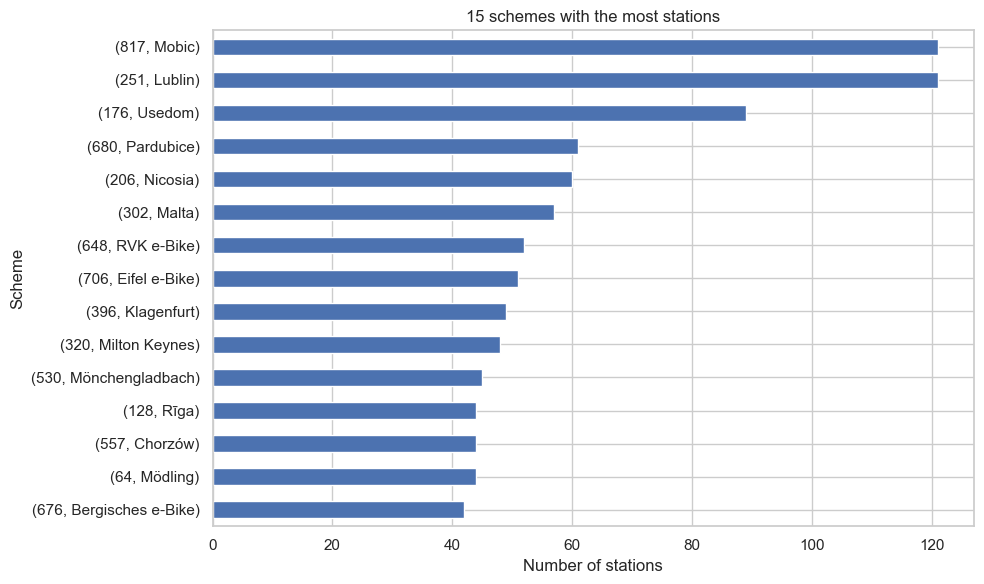

In [191]:
# Number of stations per scheme
stations_per_city = (
    station_city.groupby(['city_id', 'name_city'])
    .agg(number_of_stations=('id_station', 'count'))
    .sort_values('number_of_stations', ascending=False)
)

display(stations_per_city)

plt.figure(figsize=(10, 6))
stations_per_city.head(15)["number_of_stations"].sort_values().plot(kind="barh")
plt.title("15 schemes with the most stations")
plt.xlabel("Number of stations")
plt.ylabel("Scheme")
plt.tight_layout()
plt.show()

In [192]:
# Capacity per scheme
capacity_per_city = (
    station_city.groupby(["city_id", "name_city"])
    .agg(
        number_of_stations=("id_station", "nunique"),
        total_regular_racks=("bike_racks", "sum"),
        total_special_racks_raw=("special_racks", "sum"),
        mean_regular_racks=("bike_racks", "mean"),
        median_regular_racks=("bike_racks", "median"),
        stations_with_negative_special_racks=("special_racks", lambda x: (x < 0).sum())
    )
    .sort_values("total_regular_racks", ascending=False)
)
display(capacity_per_city.head(20))

,,number_of_stations,total_regular_racks,total_special_racks_raw,mean_regular_racks,median_regular_racks,stations_with_negative_special_racks
city_id,name_city,,,,,,
251,Lublin,121,1256,0,10.380165,15.0,0
176,Usedom,89,818,0,9.191011,8.0,0
557,Chorzów,44,655,0,14.886364,15.0,0
775,MV-Rad,38,567,0,14.921053,10.0,0
320,Milton Keynes,48,545,0,11.354167,8.0,0
302,Malta,57,437,0,7.666667,6.0,0
497,Sosnowiec,25,412,0,16.480000,12.0,0
396,Klagenfurt,49,382,0,7.795918,8.0,0
639,Orlen Płock,25,375,0,15.000000,15.0,0


In [193]:
# Average station capacity per scheme
station_city.groupby(['city_id', 'name_city']).agg(
    average_regular_racks=('bike_racks', 'mean'),
    median_regular_racks=('bike_racks', 'median'),
    average_special_racks=('special_racks', 'mean')
).sort_values('average_regular_racks', ascending=False)

,,average_regular_racks,median_regular_racks,average_special_racks
city_id,name_city,,,
550,Marki,22.000000,22.0,0.0
853,Sant Just Desvern,20.000000,21.0,0.0
856,Sant Boi de Llobregat,20.000000,20.0,0.0
848,Esplugues de Llobregat,19.636364,20.0,0.0
446,Szamotuły,17.714286,18.0,0.0
...,...,...,...,...
767,Kuřim,0.000000,0.0,0.0
752,Hlučín,0.000000,0.0,0.0
747,Limburgerhof,0.000000,0.0,0.0


In [194]:
# Groups stations by city to compute the proportion of zero-rack stations
# Sorted by highest percentage

zero_rack_analysis = (
    station_city.assign(
        zero_rack=station_city['bike_racks'].eq(0)
    )
    .groupby(['city_id', 'name_city'])
    .agg(
        total_stations=('id_station', 'count'),
        zero_rack_stations=('zero_rack', 'sum')
    )
)

zero_rack_analysis['zero_rack_percentage'] = (
    100 * zero_rack_analysis['zero_rack_stations']
    / zero_rack_analysis['total_stations']
)

zero_rack_analysis.sort_values('zero_rack_percentage', ascending=False)

,,total_stations,zero_rack_stations,zero_rack_percentage
city_id,name_city,,,
23,Neusiedler See,29,29,100.0
88,Sursee Plus,41,41,100.0
64,Mödling,44,44,100.0
165,Herzogenburg,2,2,100.0
170,Marchfeld,3,3,100.0
...,...,...,...,...
808,Geilenkirchen,4,0,0.0
831,Wolsztyn,2,0,0.0
848,Esplugues de Llobregat,11,0,0.0


* 1,220 of 2,932 stations (41.6%) have zero regular racks. They are probably virtual free-floating zones (as confirmed by their terminal types which are mostly `free` or `sign`)

* The proportion of these stations varies significantly across cities: some networks have zero physical racks, while others are entirely dock-based.

* 32 stations have a negative `special_racks`, all of which feature a 7-inch terminal type

### 1.7 Station status: consistency

In [195]:
maintenance_analysis = station_status.groupby('maintenance').agg(
    observations=('station_id', 'size'),
    mean_bikes=('bikes', 'mean'),
    mean_booked=('booked_bikes', 'mean'),
    mean_available=('bikes_available_to_rent', 'mean'),
    zero_available=(
        'bikes_available_to_rent',
        lambda x: (x == 0).mean() * 100
    )
)

maintenance_analysis

,observations,mean_bikes,mean_booked,mean_available,zero_available
maintenance,,,,,
False,2795425,6.188272,0.047497,6.141872,5.772074
True,130542,6.149025,0.013919,6.135251,4.190988


In [196]:
raw_difference = station_status["bikes"] - station_status["booked_bikes"]
clamped_expected = raw_difference.clip(lower=0)

raw_match = station_status["bikes_available_to_rent"].eq(raw_difference)
clamped_match = station_status["bikes_available_to_rent"].eq(clamped_expected)

formula_comparison = pd.DataFrame({
    "comparison": ["bikes - booked_bikes", "max(bikes - booked_bikes, 0)"],
    "matching_rows": [int(raw_match.sum()), int(clamped_match.sum())],
    "non_matching_rows": [int((~raw_match).sum()), int((~clamped_match).sum())],
    "match_percent": [raw_match.mean() * 100, clamped_match.mean() * 100]
})
display(formula_comparison)

,comparison,matching_rows,non_matching_rows,match_percent
0,bikes - booked_bikes,2923631,2336,99.920163
1,"max(bikes - booked_bikes, 0)",2925902,65,99.997779


In [197]:
remaining_formula_cases = station_status.loc[
    ~clamped_match,
    ["station_id", "time", "bikes", "booked_bikes",
     "bikes_available_to_rent", "maintenance",
     "free_racks", "free_special_racks"]
]
display(remaining_formula_cases)

,station_id,time,bikes,booked_bikes,bikes_available_to_rent,maintenance,free_racks,free_special_racks
1419140,2591849,1.678257e+09,5,1,5,False,0,0
1419141,50458,1.678257e+09,5,3,4,False,5,0
1419146,54635,1.678257e+09,5,2,5,False,0,0
1419153,54635,1.678257e+09,5,3,5,False,0,0
1419174,54635,1.678257e+09,5,4,4,False,0,0
...,...,...,...,...,...,...,...,...
1422937,142154767,1.678302e+09,5,1,5,False,6,0
1423447,142154767,1.678314e+09,5,1,5,False,17,0
1423684,51003977,1.678336e+09,5,1,5,False,4,3
1423687,51003977,1.678336e+09,5,1,5,False,4,4


In [198]:
negative_bookings = station_status[
    station_status['booked_bikes'] < 0
]

print("Rows with negative booked_bikes:", len(negative_bookings))
negative_bookings.groupby('maintenance').size()

Rows with negative booked_bikes: 160


maintenance
False    154
True       6
dtype: int64

In [199]:
display(negative_bookings["booked_bikes"].value_counts().sort_index())

booked_bikes
-4      5
-3      2
-2     33
-1    120
Name: count, dtype: int64

In [200]:
status_capacity = station_status.merge(
    station[['id', 'bike_racks', 'special_racks']],
    left_on='station_id',
    right_on='id',
    how='left',
    validate='many_to_one'
)

status_capacity['declared_capacity_raw'] = (
    status_capacity['bike_racks']
    + status_capacity['special_racks']
)

status_capacity['observed_occupied_and_free'] = (
    status_capacity['bikes']
    + status_capacity['free_racks']
    + status_capacity['free_special_racks']
)

status_capacity["capacity_difference_raw"] = (
    status_capacity["declared_capacity_raw"] -
    status_capacity["observed_occupied_and_free"]
)

status_capacity['capacity_difference_raw'].describe()

count    2.925967e+06
mean    -3.780645e+00
std      6.810545e+00
min     -1.890000e+02
25%     -6.000000e+00
50%     -2.000000e+00
75%      0.000000e+00
max      2.900000e+01
Name: capacity_difference_raw, dtype: float64

In [201]:
print("Unmatched station metadata rows:", int(status_capacity["id"].isna().sum()))
print("Stations with negative special_racks:", int((station["special_racks"] < 0).sum()))
print("Status rows with negative special-rack metadata:",
      int((status_capacity["special_racks"] < 0).sum()))
display(status_capacity["capacity_difference_raw"].describe())
display(status_capacity["capacity_difference_raw"].value_counts().head(20))
del status_capacity

Unmatched station metadata rows: 0
Stations with negative special_racks: 32
Status rows with negative special-rack metadata: 22194


count    2.925967e+06
mean    -3.780645e+00
std      6.810545e+00
min     -1.890000e+02
25%     -6.000000e+00
50%     -2.000000e+00
75%      0.000000e+00
max      2.900000e+01
Name: capacity_difference_raw, dtype: float64

capacity_difference_raw
 0     886042
-2     194536
-3     179426
-1     175245
-4     172475
-5     157170
-6     126727
-7     113082
-8     101856
 1      92644
-9      85651
-10     74567
-11     63820
 2      62241
-12     54362
-13     44853
-14     35032
 4      34852
 3      33810
-15     27613
Name: count, dtype: int64

##### Correlation between station status measurements

In [202]:
status_numeric_columns = [
    "bikes", "booked_bikes", "bikes_available_to_rent",
    "free_racks", "free_special_racks"
]
status_correlations = station_status[status_numeric_columns].corr()
display(status_correlations)

,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks
bikes,1.000000,0.010393,0.997925,-0.104465,0.057923
booked_bikes,0.010393,1.000000,-0.053644,-0.018085,-0.044238
bikes_available_to_rent,0.997925,-0.053644,1.000000,-0.103170,0.060706
free_racks,-0.104465,-0.018085,-0.103170,1.000000,0.587193
free_special_racks,0.057923,-0.044238,0.060706,0.587193,1.000000


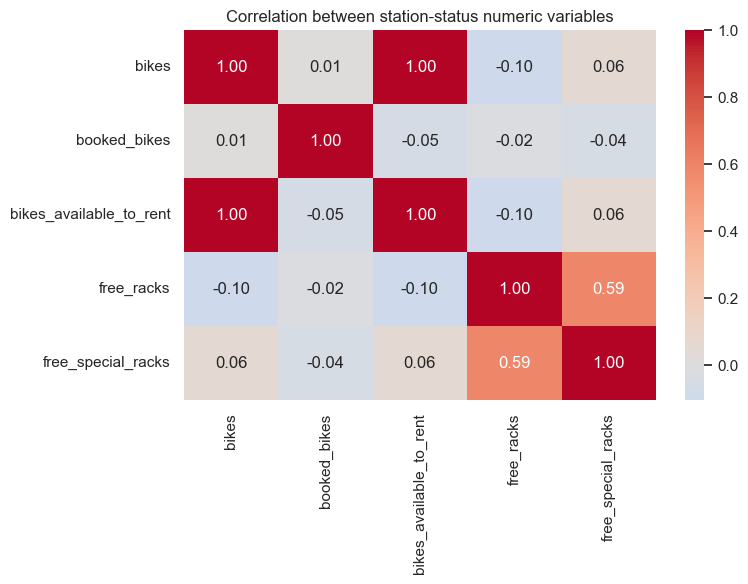

In [203]:
plt.figure(figsize=(8, 6))
sns.heatmap(status_correlations, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between station-status numeric variables")
plt.tight_layout()
plt.show()

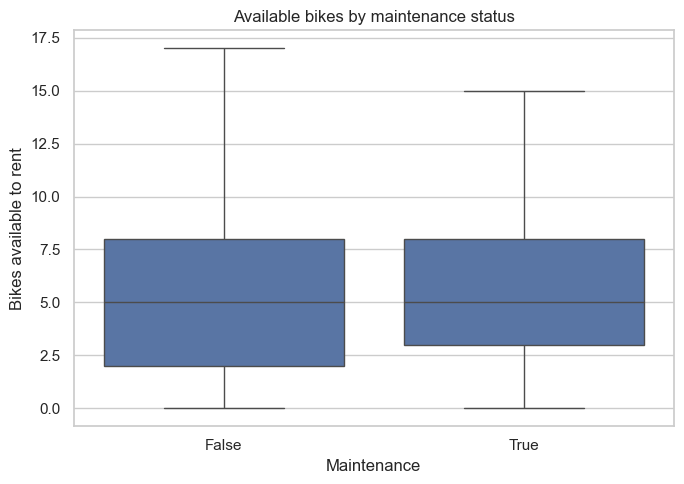

In [204]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=station_status, x="maintenance",
            y="bikes_available_to_rent", showfliers=False)
plt.title("Available bikes by maintenance status")
plt.xlabel("Maintenance")
plt.ylabel("Bikes available to rent")
plt.tight_layout()
plt.show()

#### Summary of the consistency problems in the status table

In [205]:
count_columns = ["bikes", "booked_bikes", "bikes_available_to_rent", "free_racks", "free_special_racks"]
expected_clamped = (station_status["bikes"] - station_status["booked_bikes"]).clip(lower=0)

impossible_rows = (station_status[count_columns] < 0).any(axis=1) | (
    station_status["bikes_available_to_rent"] > station_status["bikes"]
)

consistency_report = pd.Series({
    "rows": len(station_status),
    "duplicated (station_id, time)": station_status.duplicated(["station_id", "time"]).sum(),
    "booked_bikes < 0": (station_status["booked_bikes"] < 0).sum(),
    "booked_bikes > bikes": (station_status["booked_bikes"] > station_status["bikes"]).sum(),
    "available > bikes": (station_status["bikes_available_to_rent"] > station_status["bikes"]).sum(),
    "any negative count": (station_status[count_columns] < 0).any(axis=1).sum(),
    "available != max(bikes - booked, 0)": (station_status["bikes_available_to_rent"] != expected_clamped).sum(),
    "impossible rows (negative count or available > bikes)": impossible_rows.sum(),
    "maintenance rows": station_status["maintenance"].sum(),
}).to_frame("count")
consistency_report["percent"] = (consistency_report["count"] / len(station_status) * 100).round(4)
display(consistency_report)

,count,percent
rows,2925967,100.0000
"duplicated (station_id, time)",0,0.0000
booked_bikes < 0,160,0.0055
booked_bikes > bikes,2271,0.0776
available > bikes,160,0.0055
any negative count,160,0.0055
"available != max(bikes - booked, 0)",65,0.0022
impossible rows (negative count or available > bikes),160,0.0055
maintenance rows,130542,4.4615


- Tiny inconsistencies: Minor discrepancies can be seen where bikes_available_to_rent is off by 1 or 2 from bikes - booked_bikes. These are likely due to latency or concurrent transactions.
- The Rule: The vast majority of discrepancies are explained by the rule available = max(bikes - booked, 0). When booked_bikes > bikes, the system assigns the available bikes to 0. These rows were kept.
- Structural/Impossible: Rows where available > bikes or where counts are strictly negative. These violate physical reality as we cannot have more bikes available than physically exist at the station.

### 1.8 Station status: temporal structure

In [206]:
station_status['datetime'] = pd.to_datetime(
    station_status['time'],
    unit='s',
    utc=True
)

print("Period:", station_status['datetime'].min(), "to", station_status['datetime'].max())
print("Time span:", station_status['datetime'].max() - station_status['datetime'].min())
print("Unique stations in status:", station_status['station_id'].nunique())
print("Duplicate station-time rows:", station_status.duplicated(["station_id", "time"]).sum())

Period: 2022-08-26 14:48:01+00:00 to 2023-07-15 21:59:01+00:00
Time span: 323 days 07:11:00
Unique stations in status: 2899
Duplicate station-time rows: 0


In [207]:
status = station_status.sort_values(['station_id', 'time']).copy()
status['gap_min'] = status.groupby('station_id')['time'].diff()/60
status['gap_min'].describe()

count    2.923068e+06
mean     3.665869e+02
std      3.416895e+03
min      8.000000e-01
25%      4.000000e+00
50%      2.800000e+01
75%      1.580000e+02
max      4.147360e+05
Name: gap_min, dtype: float64

In [208]:
station_frequency = status.groupby('station_id').agg(
    observations=('time', 'count'),
    median_interval=('gap_min', 'median'),
    mean_interval=('gap_min', 'mean')
)

station_frequency.describe().T

,count,mean,std,min,25%,50%,75%,max
observations,2899.0,1009.302173,1678.189339,1.0,159.000000,427.000000,1099.500000,16643.0
median_interval,2892.0,543.201922,2511.697487,1.0,57.500000,155.750000,398.750000,80120.0
mean_interval,2892.0,2029.832845,4496.716904,1.0,330.237663,793.208309,2024.189945,80120.0


In [209]:
print("Number of duplicates:",status.duplicated(subset=['station_id', 'time']).sum())

Number of duplicates: 0


C:\Users\dgtrh\AppData\Local\Temp\ipykernel_29808\1848486113.py:3: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  station_status["month"] = station_status["datetime"].dt.to_period("M").astype(str)


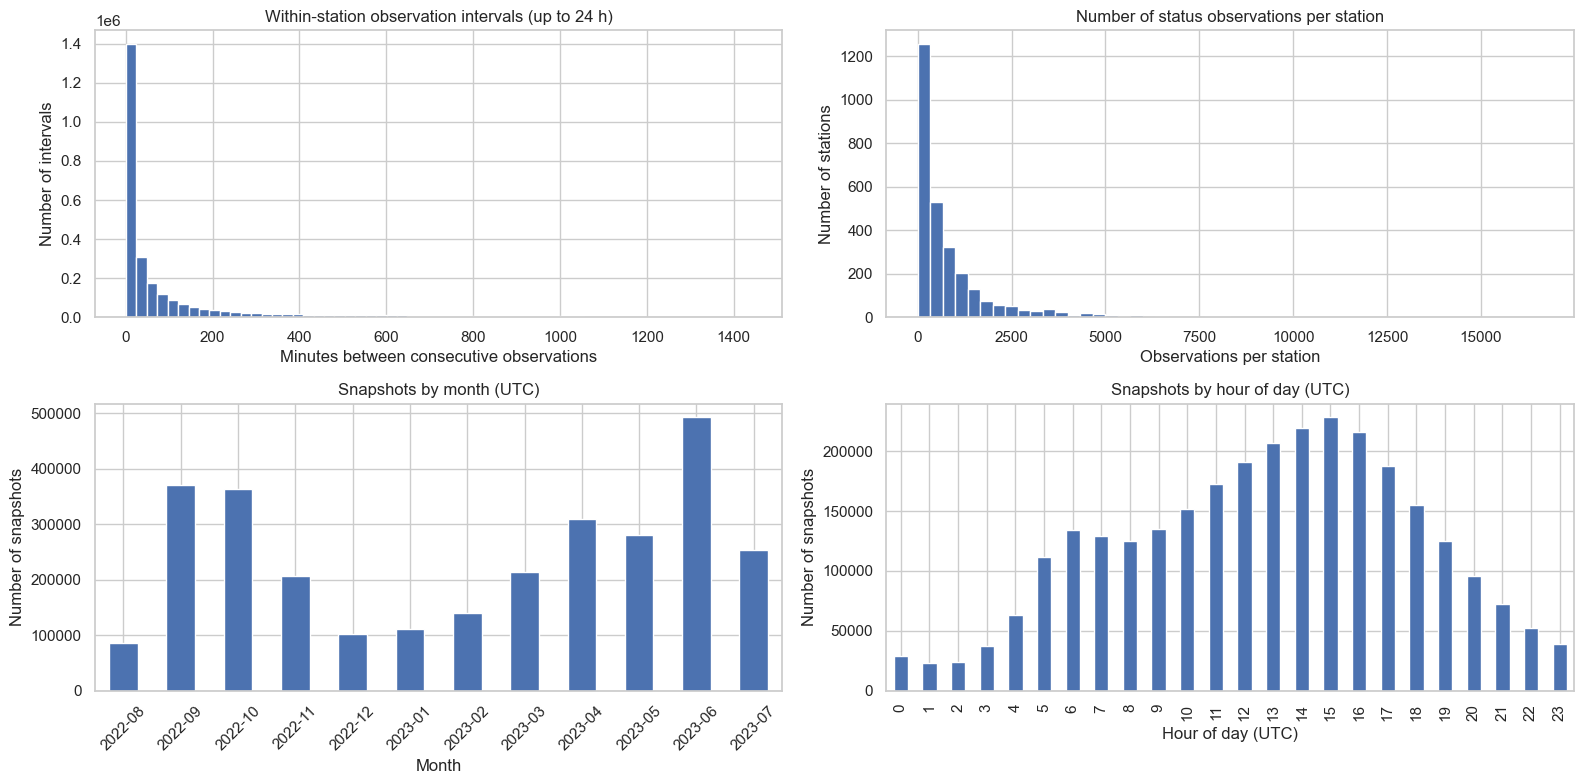

In [210]:
intervals = status["gap_min"].dropna()

station_status["month"] = station_status["datetime"].dt.to_period("M").astype(str)
station_status["hour_utc"] = station_status["datetime"].dt.hour
station_status["weekday_utc"] = station_status["datetime"].dt.day_name()

fig, axes = plt.subplots(2, 2, figsize=(16, 8))
axes = axes.flatten()

axes[0].hist(intervals[intervals <= 24 * 60], bins=60)
axes[0].set_title("Within-station observation intervals (up to 24 h)")
axes[0].set_xlabel("Minutes between consecutive observations")
axes[0].set_ylabel("Number of intervals")

axes[1].hist(station_frequency["observations"], bins=50)
axes[1].set_title("Number of status observations per station")
axes[1].set_xlabel("Observations per station")
axes[1].set_ylabel("Number of stations")

station_status.groupby("month").size().plot(
    kind="bar", ax=axes[2], title="Snapshots by month (UTC)"
)
axes[2].set_xlabel("Month")
axes[2].set_ylabel("Number of snapshots")
axes[2].tick_params(axis="x", rotation=45)

station_status.groupby("hour_utc").size().plot(
    kind="bar", ax=axes[3], title="Snapshots by hour of day (UTC)"
)
axes[3].set_xlabel("Hour of day (UTC)")
axes[3].set_ylabel("Number of snapshots")

plt.tight_layout()
plt.show()

#### 1.8.1 Is the status table a regular time series?

In [211]:
# Light working copy of the status table, sorted by station and time (used in 1.8.1 - 1.8.5)
eda_status = station_status[["station_id", "time", "bikes", "booked_bikes", "bikes_available_to_rent",
                             "free_racks", "free_special_racks", "maintenance"]].copy()
eda_status["time"] = eda_status["time"].astype("int64")
eda_status["maintenance"] = eda_status["maintenance"].astype(int)
for col in ["station_id", "bikes", "booked_bikes", "bikes_available_to_rent", "free_racks", "free_special_racks"]:
    eda_status[col] = pd.to_numeric(eda_status[col], downcast="integer")
eda_status = eda_status.sort_values(["station_id", "time"]).reset_index(drop=True)

# Minutes between two consecutive rows of the same station
eda_status["gap_min"] = eda_status.groupby("station_id")["time"].diff() / 60
display(eda_status["gap_min"].describe(percentiles=[.05, .25, .5, .75, .9, .99]).round(1))

gaps = eda_status["gap_min"].dropna()
print("Gaps of at most 1 minute: ", round((gaps <= 1).mean() * 100, 1), "%")
print("Gaps longer than 1 hour:  ", round((gaps > 60).mean() * 100, 1), "%")
print("Gaps longer than 24 hours:", round((gaps > 24 * 60).mean() * 100, 2), "%")

count    2923068.0
mean         366.6
std         3416.9
min            0.8
5%             1.0
25%            4.0
50%           28.0
75%          158.0
90%          722.0
99%         4704.0
max       414736.0
Name: gap_min, dtype: float64

Gaps of at most 1 minute:  11.8 %
Gaps longer than 1 hour:   38.3 %
Gaps longer than 24 hours: 4.23 %


In [212]:
# Are two consecutive rows of a station ever identical?
state_columns = ["bikes", "booked_bikes", "bikes_available_to_rent",
                 "free_racks", "free_special_racks", "maintenance"]
same_as_previous = (eda_status.groupby("station_id")[state_columns].shift() == eda_status[state_columns]).all(axis=1)
print("Rows identical to the previous row of the same station:", round(same_as_previous.mean() * 100, 3), "%")

Rows identical to the previous row of the same station: 0.013 %


Stations compared: 2837
Spearman correlation: 0.956


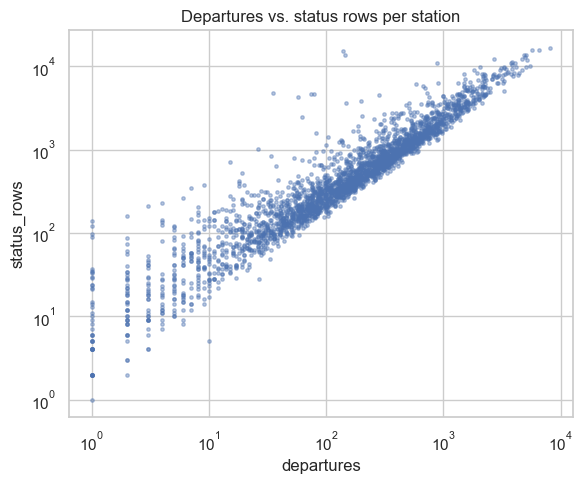

In [213]:
# Is the number of status rows of a station related to the number of trips starting there?
departures = trips.dropna(subset=["station_id_start"]).groupby("station_id_start").size().rename("departures")
rows_per_station = eda_status.groupby("station_id").size().rename("status_rows")
trip_status = pd.concat([departures, rows_per_station], axis=1).dropna()

print("Stations compared:", len(trip_status))
print("Spearman correlation:", round(trip_status.corr(method="spearman").iloc[0, 1], 3))

trip_status.plot.scatter("departures", "status_rows", s=6, alpha=0.4, loglog=True, figsize=(6, 5))
plt.title("Departures vs. status rows per station")
plt.tight_layout()
plt.show()

- The share of consecutive rows that are identical is extremely low.
- The gap_min percentiles show massive variance
- The scatter plot of departures vs status_rows shows a strong positive correlation. More trips = more state changes = more rows written.

#### 1.8.2 Coverage over time and outages

Hours in the period: 7760 | hours without any row: 373


,start_utc,hours_missing
3,2023-05-05 10:00:00,286
0,2022-09-17 15:00:00,45
1,2022-10-17 13:00:00,23
4,2023-06-26 19:00:00,12
2,2023-03-09 06:00:00,7


Days without any row: ['2022-09-18', '2023-05-06', '2023-05-07', '2023-05-08', '2023-05-09', '2023-05-10', '2023-05-11', '2023-05-12', '2023-05-13', '2023-05-14', '2023-05-15', '2023-05-16']


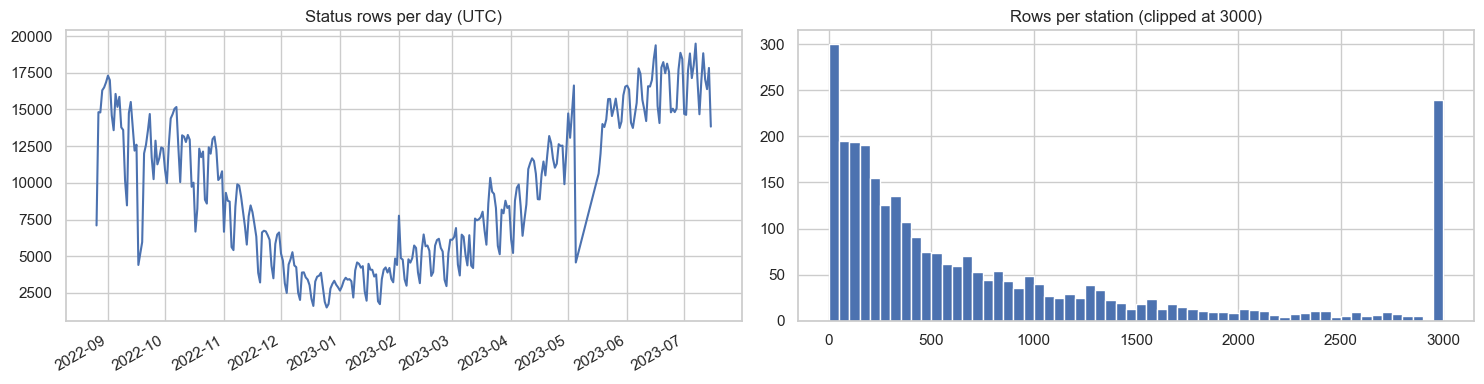

Stations with fewer than 50 rows: 296 of 2899


count     2899.0
mean      1009.3
std       1678.2
min          1.0
10%         47.8
25%        159.0
50%        427.0
75%       1099.5
90%       2523.4
max      16643.0
dtype: float64

In [214]:
# Hours (UTC) that contain no row at all, between the first and the last observation
hours_present = np.unique(eda_status["time"].to_numpy() // 3600)
all_hours = np.arange(hours_present.min(), hours_present.max() + 1)
missing_hours = np.setdiff1d(all_hours, hours_present)
print("Hours in the period:", len(all_hours), "| hours without any row:", len(missing_hours))

# Group consecutive missing hours into outage windows
windows = np.split(missing_hours, np.where(np.diff(missing_hours) > 1)[0] + 1)
outages = pd.DataFrame({
    "start_utc": [pd.to_datetime(w[0] * 3600, unit="s") for w in windows],
    "hours_missing": [len(w) for w in windows],
}).sort_values("hours_missing", ascending=False)
display(outages.head(10))

# Rows per day
rows_per_day = pd.Series(eda_status["time"].to_numpy() // 86400).value_counts().sort_index()
rows_per_day.index = pd.to_datetime(rows_per_day.index * 86400, unit="s")
days = pd.date_range(rows_per_day.index.min(), rows_per_day.index.max())
print("Days without any row:", [d.date().isoformat() for d in days.difference(rows_per_day.index)])

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
rows_per_day.plot(ax=axes[0], title="Status rows per day (UTC)")
rows_per_station_count = eda_status.groupby("station_id").size()
rows_per_station_count.clip(upper=3000).hist(bins=60, ax=axes[1])
axes[1].set_title("Rows per station (clipped at 3000)")
plt.tight_layout()
plt.show()

print("Stations with fewer than 50 rows:", int((rows_per_station_count < 50).sum()), "of", len(rows_per_station_count))
display(rows_per_station_count.describe(percentiles=[.1, .25, .5, .75, .9]).round(1))

- There are specific hours where the entire network has zero rows.
- Stations with very few rows are not useful as we cannot compute lags, or understand their temporal patterns with so little data. They must be dropped or flagged to prevent noise into the training set.

#### 1.8.3 Target variable: bikes_available_to_rent

count    2925967.00
mean           6.14
std            6.10
min            0.00
50%            5.00
90%           12.00
99%           24.00
99.9%         65.00
max          189.00
Name: bikes_available_to_rent, dtype: float64

Share of zeros: 5.7 %
Skewness: 6.4


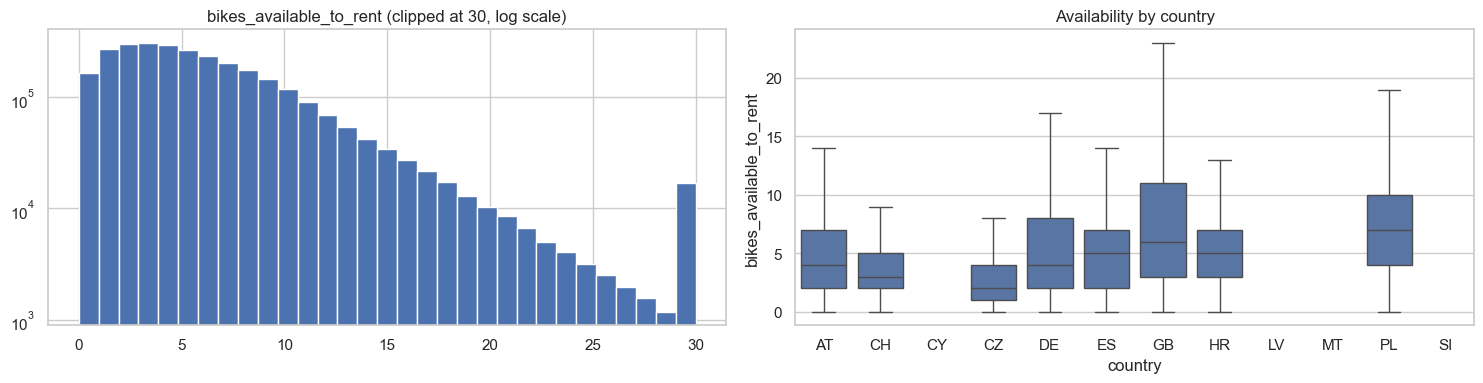

In [215]:
target = eda_status["bikes_available_to_rent"]
display(target.describe(percentiles=[.5, .9, .99, .999]).round(2))
print("Share of zeros:", round((target == 0).mean() * 100, 2), "%")
print("Skewness:", round(target.skew(), 2))

# Country of every row (through station -> scheme)
station_country = station.set_index("id")["city_id"].map(city.set_index("id")["country"])
eda_status["country"] = eda_status["station_id"].map(station_country).astype("category")

plot_sample = eda_status.sample(300000, random_state=RANDOM_STATE)
top_countries = eda_status["country"].value_counts().head(8).index

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
target.clip(upper=30).hist(bins=31, ax=axes[0])
axes[0].set_yscale("log")
axes[0].set_title("bikes_available_to_rent (clipped at 30, log scale)")
sns.boxplot(data=plot_sample[plot_sample["country"].isin(top_countries)],
            x="country", y="bikes_available_to_rent", showfliers=False, ax=axes[1])
axes[1].set_title("Availability by country")
plt.tight_layout()
plt.show()

In [216]:
# Very large values: isolated errors or a station that is always large?
large_rows = eda_status[eda_status["bikes"] > 60]
hub_stations = large_rows.groupby("station_id").size().sort_values(ascending=False).head(5)
hub_table = hub_stations.to_frame("rows_with_more_than_60_bikes").join(
    station.set_index("id")[["name", "city_id"]])
hub_table["max_bikes"] = hub_table.index.map(eda_status.groupby("station_id")["bikes"].max())
display(hub_table)
print("Rows with more than 60 bikes:", len(large_rows),
      "| share coming from the top station:", round(hub_stations.iloc[0] / len(large_rows) * 100, 1), "%")

,rows_with_more_than_60_bikes,name,city_id,max_bikes
station_id,,,,
132562406,2200,"Taller - Bicicletas Cargando ""CHARGING BIKES""",833,189
66397,635,Zweirad - Awe Strandpromenade Ückeritz 5516,176,176
66400,286,Usedom Rad GmbH Zentrale 5555,176,97
87796472,72,Hauptbahnhof,7,67
746642,21,Central Milton Keynes - Train Station,320,64


Rows with more than 60 bikes: 3214 | share coming from the top station: 68.5 %


- Nature of the Target: The target variable is a discrete count rather than a continuous variable.
- Distribution: The target distribution is highly right-skewed, with a large number of zero values, particularly at night, during maintenance periods, or at small/free-floating stations.
- Large Values: Extremely large values are not errors or anomalies; they represent genuine high-capacity city centers.
- Metric Implication: Since the target is a count variable with extreme outliers, Mean Absolute Error (MAE) is more appropriate than Root Mean Squared Error (RMSE), as MAE is less sensitive to extreme values.

#### 1.8.4 Differences between stations

,count,mean,std,min,25%,50%,75%,max
mean,2899.0,4.63,4.11,0.0,2.54,3.88,5.96,102.82
std,2892.0,2.33,1.35,0.5,1.53,2.10,2.85,36.25
max,2899.0,12.14,8.24,0.0,7.00,11.00,15.00,189.00
size,2899.0,1009.30,1678.19,1.0,159.00,427.00,1099.50,16643.00


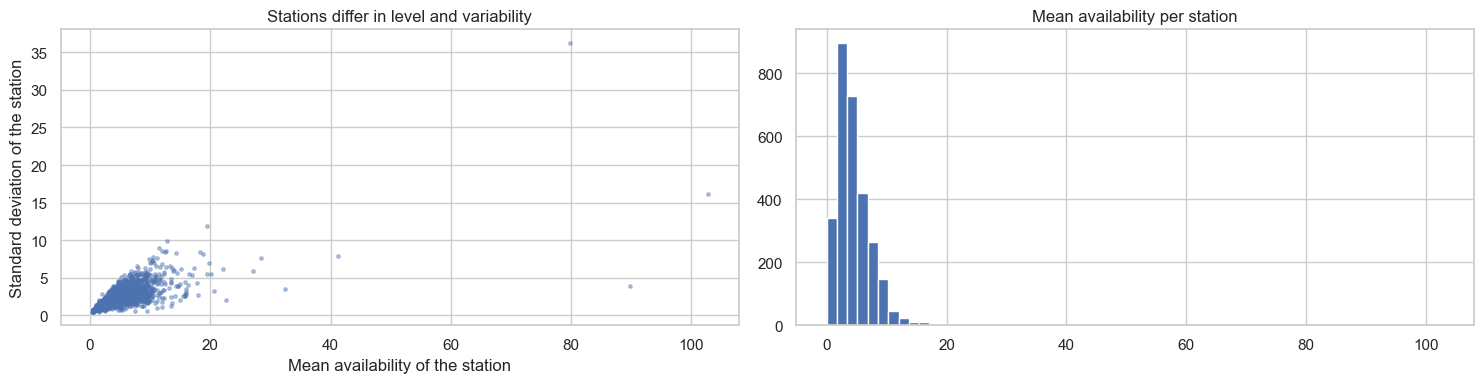

,mean,std,max,size,name,city_id
station_id,,,,,,
66397,102.82,16.10,176,635,Zweirad - Awe Strandpromenade Ückeritz 5516,176
66400,89.85,3.91,97,286,Usedom Rad GmbH Zentrale 5555,176
132562406,79.89,36.25,189,3579,"Taller - Bicicletas Cargando ""CHARGING BIKES""",833
746642,41.21,7.87,64,8354,Central Milton Keynes - Train Station,320
82170,32.43,3.54,38,181,Bike Hotel Vaske Karlshagen 5553,176
76245743,28.39,7.64,40,92,DJH - Jugendherberge Prora 01,775
66388,27.18,5.87,33,61,Naturcamping Lütow 5508,176
153213,22.55,2.12,27,89,Kurverwaltung Seebad Lubmin 57139,775
159893772,22.18,6.20,40,1013,virtuell - S-Bahnhof Erkner,819


In [217]:
per_station = eda_status.groupby("station_id")["bikes_available_to_rent"].agg(["mean", "std", "max", "size"])
display(per_station.describe().T.round(2))

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].scatter(per_station["mean"], per_station["std"], s=6, alpha=0.4)
axes[0].set_xlabel("Mean availability of the station")
axes[0].set_ylabel("Standard deviation of the station")
axes[0].set_title("Stations differ in level and variability")
per_station["mean"].hist(bins=60, ax=axes[1])
axes[1].set_title("Mean availability per station")
plt.tight_layout()
plt.show()

display(per_station.sort_values("mean", ascending=False).head(10).join(
    station.set_index("id")[["name", "city_id"]]).round(2))

- Stations are wildly different. Some have 70+ physical racks, some have 0 (virtual/free-floating), and they vary by terminal type and city.
- We must include station-specific metadata during model creation as features. Furthermore, all the stations have unique local dynamics, so we can evaluate the model by city or station to ensure the model generalizes to unseen station behaviors.

#### 1.8.5 Temporal patterns in local time

In [218]:
# Local hour and weekday of every status row (every scheme has its own timezone)
station_timezone = station.set_index("id")["city_id"].map(city.set_index("id")["timezone"])
row_timezone = eda_status["station_id"].map(station_timezone)

hour_local = np.zeros(len(eda_status), dtype="int8")
weekday_local = np.zeros(len(eda_status), dtype="int8")
for tz_name in row_timezone.dropna().unique():
    in_tz = (row_timezone == tz_name).to_numpy()
    local_time = pd.to_datetime(eda_status.loc[in_tz, "time"], unit="s", utc=True).dt.tz_convert(tz_name)
    hour_local[in_tz] = local_time.dt.hour.to_numpy()
    weekday_local[in_tz] = local_time.dt.dayofweek.to_numpy()
eda_status["hour_local"] = hour_local
eda_status["weekday_local"] = weekday_local

hour_utc = (eda_status["time"] // 3600) % 24
print("Busiest hour (rows) in UTC:  ", hour_utc.value_counts().idxmax())
print("Busiest hour (rows) in local:", eda_status["hour_local"].value_counts().idxmax())

Busiest hour (rows) in UTC:   15
Busiest hour (rows) in local: 16


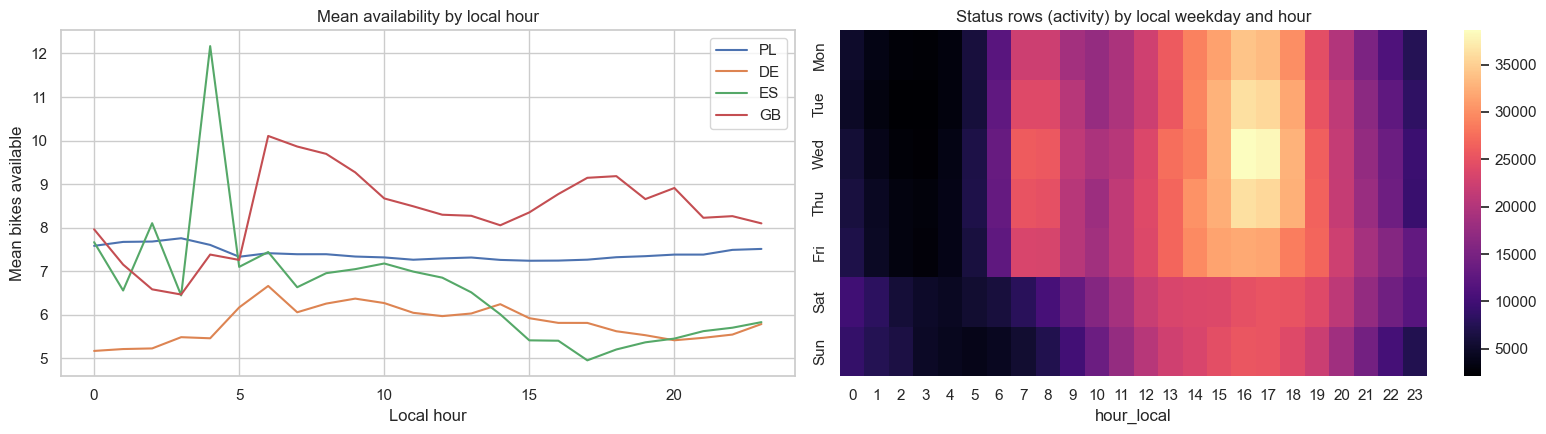

,mean,median,size
is_weekend,,,
False,6.10,5.0,2225416
True,6.27,5.0,700551


In [219]:
# Number of rows = number of state changes, so the heatmap shows ACTIVITY, not availability
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for country in eda_status["country"].value_counts().head(4).index:
    (eda_status[eda_status["country"] == country]
     .groupby("hour_local")["bikes_available_to_rent"].mean().plot(ax=axes[0], label=country))
axes[0].legend()
axes[0].set_xlabel("Local hour")
axes[0].set_ylabel("Mean bikes available")
axes[0].set_title("Mean availability by local hour")

activity = eda_status.pivot_table(index="weekday_local", columns="hour_local",
                                  values="station_id", aggfunc="size")
activity.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
sns.heatmap(activity, cmap="magma", ax=axes[1])
axes[1].set_title("Status rows (activity) by local weekday and hour")
plt.tight_layout()
plt.show()

weekday_vs_weekend = (eda_status.assign(is_weekend=eda_status["weekday_local"] >= 5)
                      .groupby("is_weekend")["bikes_available_to_rent"].agg(["mean", "median", "size"]))
display(weekday_vs_weekend.round(2))

In [220]:
# Free memory: the light working copy is not needed any more
del eda_status, same_as_previous, large_rows, plot_sample, row_timezone, hour_local, weekday_local

- The number of rows in station_status measures activity, not just how many bikes are there.
- The system is most active during weekday rush hours (commuter times). Weekends show a flatter, leisure-oriented distribution. Availability is lowest during the middle of the day on weekdays and highest early in the morning.
- The station_status table is event-driven.

### 1.9 Trips

In [221]:
trip_validity = pd.Series({
    "duration_nonpositive": (trips["duration"] <= 0).sum(),
    "distance_nonpositive": (trips["distance"] <= 0).sum(),
    "invalid_start_longitude": (~trips["lon_start"].between(-180, 180)).sum(),
    "invalid_end_longitude": (~trips["lon_end"].between(-180, 180)).sum(),
    "invalid_start_latitude": (~trips["lat_start"].between(-90, 90)).sum(),
    "invalid_end_latitude": (~trips["lat_end"].between(-90, 90)).sum()
}, name="count")
display(trip_validity)

duration_nonpositive       0
distance_nonpositive       0
invalid_start_longitude    0
invalid_end_longitude      0
invalid_start_latitude     0
invalid_end_latitude       0
Name: count, dtype: int64

In [222]:
display(trips[["duration", "distance"]].corr())

,duration,distance
duration,1.000000,0.391023
distance,0.391023,1.000000


In [223]:
trip_summary = trips[["duration", "distance"]].describe(
    percentiles=[.5, .75, .9, .95, .99]
).T
display(trip_summary)

,count,mean,std,min,50%,75%,90%,95%,99%,max
duration,1161376.0,1256.241229,1980.837946,121.000000,720.000000,1200.000000,2340.000000,3960.000000,10200.00000,28740.000000
distance,1161376.0,1791.773844,1495.190508,50.013649,1346.710991,2238.540454,3415.328448,4344.718527,7418.18874,19999.457592


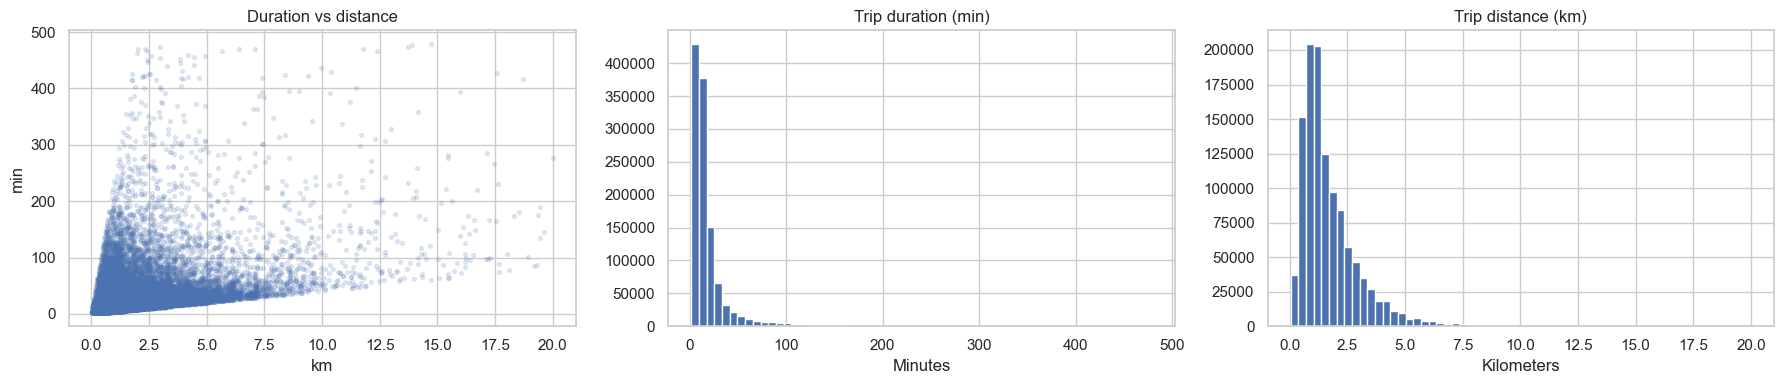

In [224]:
sample = trips.sample(n=min(50000, len(trips)), random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].scatter(sample["distance"] / 1000, sample["duration"] / 60, alpha=0.15, s=8)
axes[0].set_title("Duration vs distance")
axes[0].set_xlabel("km")
axes[0].set_ylabel("min")

axes[1].hist(trips["duration"] / 60, bins=60)
axes[1].set_title("Trip duration (min)")
axes[1].set_xlabel("Minutes")

axes[2].hist(trips["distance"] / 1000, bins=60)
axes[2].set_title("Trip distance (km)")
axes[2].set_xlabel("Kilometers")

plt.tight_layout()
plt.show()

In [225]:
trip_profile = (
    trips.merge(
        bike[["id", "bike_type_id"]].rename(columns={"id": "bike_id"}),
        on="bike_id",
        how="left",
        validate="many_to_one"
    ).merge(
        types[["id", "propulsion_type"]].rename(columns={"id": "bike_type_id"}),
        on="bike_type_id",
        how="left",
        validate="many_to_one"
    )
)

battery_missing_by_propulsion = trip_profile.groupby("propulsion_type", dropna=False).agg(
    trips=("bike_id", "size"),
    missing_battery_start=("battery_start", lambda x: x.isna().mean() * 100),
    missing_battery_end=("battery_end", lambda x: x.isna().mean() * 100),
    median_battery_start=("battery_start", "median"),
    median_battery_end=("battery_end", "median")
)
display(battery_missing_by_propulsion)

,trips,missing_battery_start,missing_battery_end,median_battery_start,median_battery_end
propulsion_type,,,,,
electric_assist,180091,6.586115,6.52559,89.0,83.0
human,978939,99.969150,99.96915,0.0,0.0
NaN,2346,100.000000,100.00000,NaN,NaN


In [226]:
trip_profile["start_station_missing"] = trip_profile["station_id_start"].isna()
trip_profile["end_station_missing"] = trip_profile["station_id_end"].isna()

In [227]:
free_floating_by_propulsion = trip_profile.groupby(
    "propulsion_type", dropna=False
).agg(
    trips=("bike_id", "size"),
    missing_start_station_percent=("start_station_missing", "mean"),
    missing_end_station_percent=("end_station_missing", "mean")
) * 1
free_floating_by_propulsion[[
    "missing_start_station_percent", "missing_end_station_percent"
]] *= 100
display(free_floating_by_propulsion)

,trips,missing_start_station_percent,missing_end_station_percent
propulsion_type,,,
electric_assist,180091,4.906408,5.995858
human,978939,8.208070,11.346468
NaN,2346,1.150895,1.321398


In [228]:
trip_city = trips.merge(
    city[["id", "name", "country"]],
    left_on="city_id",
    right_on="id",
    how="left",
    validate="many_to_one",
    suffixes=("_trip", "_scheme")
)

trip_city["start_station_missing"] = trip_city["station_id_start"].isna()
trip_city["end_station_missing"] = trip_city["station_id_end"].isna()

free_floating_by_scheme = trip_city.groupby(
    ["city_id", "name", "country"], dropna=False
).agg(
    trips=("time_start", "size"),
    missing_start_station_percent=("start_station_missing", "mean"),
    missing_end_station_percent=("end_station_missing", "mean")
)

free_floating_by_scheme[[
    "missing_start_station_percent", "missing_end_station_percent"
]] *= 100
display(free_floating_by_scheme.sort_values("trips", ascending=False).head(20))

,,,trips,missing_start_station_percent,missing_end_station_percent
city_id,name,country,,,
848,Esplugues de Llobregat,ES,29661,0.000000,0.003371
592,Walldorf,DE,28458,62.896198,67.288636
88,Sursee Plus,CH,28230,9.029401,14.243712
530,Mönchengladbach,DE,27232,4.615893,11.262485
817,Mobic,DE,27073,21.161305,23.647176
856,Sant Boi de Llobregat,ES,26840,0.003726,0.029806
749,Getxo,ES,25874,3.416557,4.804050
496,Koszalin,PL,25160,1.693164,2.062798
251,Lublin,PL,24785,1.468630,2.453097


#### Trips over time (local time)

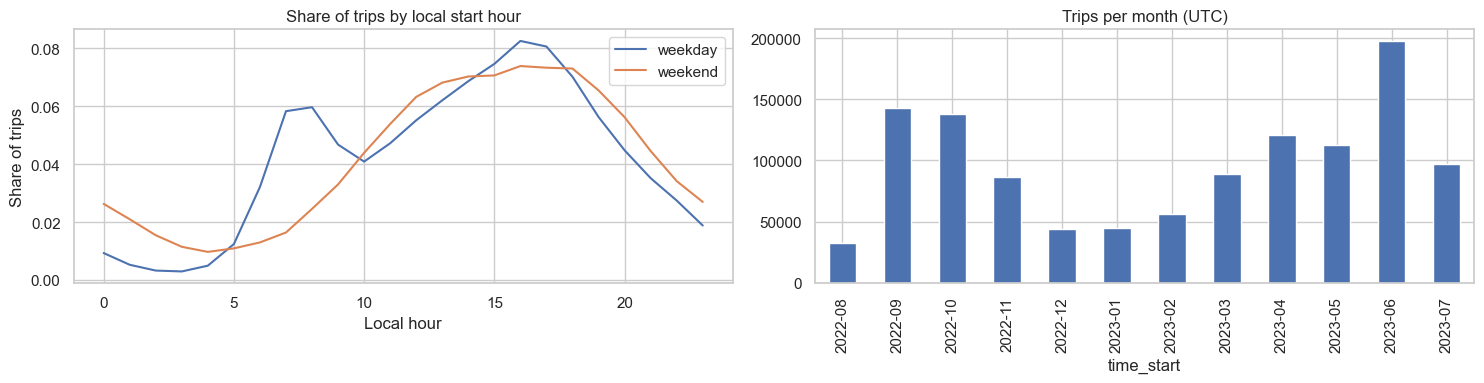

In [229]:
# Local hour and weekday of every trip start (timezone of the scheme of the trip)
eda_trips = trips[["time_start", "city_id", "duration", "distance"]].copy()
eda_trips["time_start"] = eda_trips["time_start"].astype("int64")
trip_timezone = eda_trips["city_id"].map(city.set_index("id")["timezone"])

trip_hour_local = np.zeros(len(eda_trips), dtype="int8")
trip_weekday_local = np.zeros(len(eda_trips), dtype="int8")
for tz_name in trip_timezone.dropna().unique():
    in_tz = (trip_timezone == tz_name).to_numpy()
    local_time = pd.to_datetime(eda_trips.loc[in_tz, "time_start"], unit="s", utc=True).dt.tz_convert(tz_name)
    trip_hour_local[in_tz] = local_time.dt.hour.to_numpy()
    trip_weekday_local[in_tz] = local_time.dt.dayofweek.to_numpy()
eda_trips["hour_local"] = trip_hour_local
eda_trips["weekend"] = trip_weekday_local >= 5

# Share of the trips of each day type that start in each local hour
hourly_share = (eda_trips.groupby(["weekend", "hour_local"]).size()
                .groupby(level=0).transform(lambda s: s / s.sum()).unstack(0))
hourly_share.columns = ["weekday", "weekend"]

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
hourly_share.plot(ax=axes[0], title="Share of trips by local start hour")
axes[0].set_xlabel("Local hour")
axes[0].set_ylabel("Share of trips")
pd.to_datetime(eda_trips["time_start"], unit="s").dt.to_period("M").value_counts().sort_index().plot(
    kind="bar", ax=axes[1], title="Trips per month (UTC)")
plt.tight_layout()
plt.show()

del eda_trips, trip_timezone, trip_hour_local, trip_weekday_local

- Weekday vs Weekend: Weekdays show a "double peak" pattern, with spikes during the morning rush (8-9 AM) and evening rush (5-6 PM). Weekends show a peak in the mid-afternoon (1-4 PM).
- Trip volume is highly seasonal. It peaks during the summer and early autumn months and drops significantly during the winter.

### 1.10 Summary of the data exploration

- Station_status is an event-driven change log, not a regular time series. Rows are generated by user activity (trips)
- We identified impossible physical states (negative counts, available > total bikes) which were dropped. We also found global temporal outages (hours with zero data) and stations with insufficient history.
- The target is bikes_available_to_rent one hour in the future. It is a highly skewed count variable with many zeros, making MAE a more robust evaluation metric than RMSE.
- Stations vary wildly in capacity (0 to 189 bikes), terminal type, and geographic location.
- The activity follows strong patterns (weekday rush hours) and seasonal trends (summer peaks). Weekends show mid-afternoon peaks.

## 2. Data Preparation

### 2.1 Bike types

In [230]:
types_c = types.copy()
types_c["propulsion_type"] = types_c["propulsion_type"].replace({"electric_assist": "electric"})
types_c["form_factor"] = types_c["form_factor"].replace({"bicycle": "regular", "cargo_bicycle": "cargo"})

# electric types with missing battery/range: mean of electric types with the same form factor
battery_cols = ["max_range", "battery_capacity"]
is_electric = types_c["propulsion_type"] == "electric"
for form in ["regular", "cargo"]:
    m = is_electric & (types_c["form_factor"] == form)
    types_c.loc[m, battery_cols] = types_c.loc[m, battery_cols].fillna(types_c.loc[m, battery_cols].mean())

# remaining gaps: unknown types (kept: referenced by bikes) and human-powered bikes
string_cols = ["vehicle_image", "name", "description", "form_factor", "propulsion_type"]
numeric_cols = ["rider_capacity", "max_range", "battery_capacity"]
types_c[string_cols] = types_c[string_cols].fillna("Unknown")
types_c[numeric_cols] = types_c[numeric_cols].fillna(0)

print("Missing values left:", int(types_c.isna().sum().sum()))
print(types_c["propulsion_type"].value_counts().to_dict(), types_c["form_factor"].value_counts().to_dict())

Missing values left: 0
{'human': 64, 'Unknown': 30, 'electric': 27} {'regular': 71, 'Unknown': 30, 'cargo': 19, 'other': 1}


#### Cleaning the bike-type names

The 46 commercial names represent bike types under various spellings and languages. They are normalized using prioritized keyword rules (most specific first). Names describing only locks or hardware generations (for example `with Framelock`) are classified as standard city bikes.

In [231]:
def clean_bike_type_name(name):

    if pd.isna(name) or str(name).strip().lower() in {"", "unknown", "nan"}:
        return "Unknown"

    n = re.sub(r"\s+", " ", str(name)).strip().lower()
    rules = [
        ("E-cargo bike",         r"^e-?cargo"),
        ("Cargo bike",           r"cargo"),
        ("Tandem",               r"tandem"),
        ("Handbike",             r"handbike"),
        ("Tricycle",             r"tr[oó]jko[lł]owy|tricycle"),
        ("Bike with child seat", r"fotelik|child|sjedalica"),
        ("Kids bike",            r"kinder|rowerek"),
        ("E-bike",               r"^e-?bike|^e-?smartbike|^e-?classicbike|elektri"),
        ("City bike",            r"smartbike|classic|comfort|tourenfahrrad|usedomrad|wa[łl]em|kardan|framelock|fork lock"),
    ]

    for label, pattern in rules:
        if re.search(pattern, n):
            return label
    return "Other"

In [232]:
types_c["bike_type_group"] = types_c["name"].map(clean_bike_type_name)
print("Names mapped to 'Other' (to be reviewed):", sorted(types_c.loc[types_c["bike_type_group"] == "Other", "name"].unique()))
types_c["bike_type_group"].value_counts(dropna=False).sort_index()

Names mapped to 'Other' (to be reviewed): []


bike_type_group
Bike with child seat    13
Cargo bike               7
City bike               27
E-bike                  15
E-cargo bike            12
Handbike                 1
Kids bike                7
Tandem                   7
Tricycle                 1
Unknown                 31
Name: count, dtype: int64

In [233]:
# Name with bike_type_group mapping
mapping = (types_c.groupby(["bike_type_group", "name"])
           .agg(technical_ids=("id", "count"), bikes=("id", lambda s: int(bike["bike_type_id"].isin(s).sum())))
           .sort_values(["bike_type_group", "bikes"], ascending=[True, False]))
display(mapping)

technical_ids  bikes
bike_type_group      name                                                 
Bike with child seat + Children's seat                            1    200
                     Rower z fotelikiem dziecięcym               10    168
                     Bike with child seat                         1     65
                     Dječja sjedalica                             1     26
Cargo bike           CARGObike                                    2     94
                     Cargo                                        4     53
                     CARGObike (3 wheels)                         1     16
City bike            with Framelock                               4  41691
                     SMARTbike 2.0 (A) 2018                       1  13375
                     with Fork lock                               1   7227
                     CLASSICbike                                  1   5108
                     Comfort                                      1   4756
                     3-rychlostní SMARTbike 2.0.                  3   2547
                     Comfort 1 1/8 Zoll                           1   1607
                     8-rychlostní SMARTbike                       2   1558
                     CLASSICbike 2.0                              1    725
                     7-rychlostní SMARTbike                       2    600
                     3-rychlostní SMARTbike                       1    451
                     8-rychlostní SMARTbike 2.0.                  1    297
                     28 Zoll - Tourenfahrrad                      1    197
                     UsedomRad                                    1    184
                     Classic                                      1     75
                     UsedomRad Classic                            1     43
                     7-rychlostní SMARTbike 2.0.                  1     42
                     Z wałem kardana                              1     30
                     26 Zoll - Tourenfahrrad                      1      8
                     Smartbike 2.0 (B) 2019                       1      1
E-bike               E-Bike                                       4   2729
                     e-SMARTbike 2.0 RFID                         1   1487
                     e-SMARTbike 2.0 (fixed battery)              1    661
                     e-SMARTbike 2.0.                             3    334
                     E-CLASSICbike SWAP                           1    229
                     e-SMARTbike 2.0 with RFID                    1    126
                     e-SMARTbike 1.0                              1     79
                     Elektricno kolo                              1     60
                     ebike [električni bicikl]                    1     44
                     e-Bike "LaBigi"                              1     11
E-cargo bike         e-CARGObike                                  5     75
                     e-Cargobike                                  7     21
Handbike             Handbike                                     1      1
Kids bike            Rowerek dziecięcy 6+                         5     83
                     24 Zoll - Kinderfahrrad                      1      6
                     20 Zoll - Kinderfahrrad                      1      1
Tandem               Tandem                                       7     38
Tricycle             Rower Trójkołowy                             1      4
Unknown              Unknown                                     31   1303

In [234]:
# Summary with bike_type_group
display(types_c.groupby("bike_type_group").agg(
    raw_names=("name", "nunique"), technical_ids=("id", "count"),
    bikes=("id", lambda s: int(bike["bike_type_id"].isin(s).sum()))).sort_values("bikes", ascending=False))

,raw_names,technical_ids,bikes
bike_type_group,,,
City bike,20,27,80522
E-bike,10,15,5760
Unknown,1,31,1303
Bike with child seat,4,13,459
Cargo bike,3,7,163
E-cargo bike,2,12,96
Kids bike,3,7,90
Tandem,1,7,38
Tricycle,1,1,4


In [235]:
# Checking the relationship between bike_type_group and propulsion_type
display(pd.crosstab(types_c["bike_type_group"], types_c["propulsion_type"]))

propulsion_type,Unknown,electric,human
bike_type_group,,,
Bike with child seat,0,0,13
Cargo bike,0,0,7
City bike,0,0,27
E-bike,0,15,0
E-cargo bike,0,12,0
Handbike,0,0,1
Kids bike,0,0,7
Tandem,0,0,7
Tricycle,0,0,1


* The raw names collapse into 10 groups: *City bike*, *E-bike*, *Cargo bike*, *E-cargo bike*, *Bike with child seat*, *Kids bike*, *Tandem*, *Tricycle*, *Handbike* and *Unknown*. No name falls into *Other*, so the rules cover every name present in the data

* The cross-table with `propulsion_type` is a consistency check: the *E-bike* and *E-cargo bike* groups should be electric and the *City bike* group human-powered.

### 2.2 Stations

In [236]:
def prepare_station(station_raw):
    station_c = station_raw.drop(columns=["rack_locks", "total_racks_raw"], errors="ignore").copy()

    station_c["negative_special_racks_flag"] = (station_c["special_racks"] < 0).astype(int)
    station_c["zero_regular_racks_flag"] = (station_c["bike_racks"] == 0).astype(int)

    station_c["terminal_type"] = station_c["terminal_type"].fillna("Unknown")

    return station_c

In [237]:
station_c = prepare_station(station)

station_c = station_c.merge(
    city[["id", "name", "country", "timezone", "return_to_official_only"]].rename(
        columns={"id": "city_id", "name": "scheme"}),
    on="city_id",
    how="left",
    validate="many_to_one"
)

station_c["return_to_official_only"] = station_c["return_to_official_only"].astype(int)

print("Shape:", station_c.shape)
print("Missing values:", int(station_c[["terminal_type", "country", "timezone"]].isna().sum().sum()))

Shape: (2932, 16)
Missing values: 0


#### Station coordinates: sanity check

In [238]:
def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371.0 * 2 * np.arcsin(np.sqrt(a))


def add_station_geography(station_df, city_df):
    """Distance to the scheme centre and to the scheme's median station + a flag for suspicious coordinates."""
    out = station_df.copy()

    centre = city_df.set_index("id")[["lat", "lon"]]
    out["distance_to_city_center_km"] = haversine_km(
        out["lat"], out["lon"], out["city_id"].map(centre["lat"]), out["city_id"].map(centre["lon"]))

    # a station very far from the other stations of its own scheme is suspicious
    median_location = out.groupby("city_id")[["lat", "lon"]].transform("median")
    out["distance_to_scheme_median_km"] = haversine_km(
        out["lat"], out["lon"], median_location["lat"], median_location["lon"])

    # coordinates such as (50.0, 6.0) look like placeholders
    round_coordinates = (out["lat"] % 1 == 0) & (out["lon"] % 1 == 0)
    out["coord_suspect_flag"] = ((out["distance_to_scheme_median_km"] > 200) | round_coordinates).astype(int)
    return out


station_c = add_station_geography(station_c, city)

print("Stations flagged as suspicious:", int(station_c["coord_suspect_flag"].sum()))
display(station_c.sort_values("distance_to_scheme_median_km", ascending=False)[
    ["id", "scheme", "country", "lat", "lon", "distance_to_city_center_km",
     "distance_to_scheme_median_km", "coord_suspect_flag"]].head(10).round(2))

Stations flagged as suspicious: 4


,id,scheme,country,lat,lon,distance_to_city_center_km,distance_to_scheme_median_km,coord_suspect_flag
2486,205113328,Tecklenburg,DE,7.75,7.80,4945.22,4940.79,1
388,131216337,Tarnów,PL,52.27,21.06,251.37,250.90,1
201,76289676,MV-Rad,DE,53.89,11.44,69.25,146.92,0
181,77080269,MV-Rad,DE,53.89,11.44,69.24,146.91,0
2865,199883778,Mobic,DE,50.00,6.00,105.65,117.57,1
2216,199878829,Mobic,DE,50.00,6.00,105.65,117.57,1
217,76289539,MV-Rad,DE,54.18,12.06,61.08,105.83,0
180,77080188,MV-Rad,DE,54.18,12.06,61.08,105.83,0
210,199129,MV-Rad,DE,53.27,12.82,51.61,103.22,0
12,130175397,Laa an der Thaya,AT,48.77,14.98,103.42,103.18,0


- Stations located far outside their city's geographic center have suspicious coordinates
- We cannot safely correct them as we don't have the ground truth. It could be a GPS glitch, or it could be a legitimate station.
- Some bike-sharing schemes are regional (covering multiple towns or a whole province), not just city-center. The 200 km threshold captures genuine GPS anomalies while respecting legitimate regional networks.

### 2.3 Station status

In [239]:
STATION_INFO = station_c.set_index("id")

COUNT_COLUMNS = ["bikes", "booked_bikes", "bikes_available_to_rent", "free_racks", "free_special_racks"]

# Cleans raw station status data, removes impossible rows and adds UTC and local time features.
def prepare_status(raw, station_info, drop_invalid=True):

    s = raw.drop_duplicates(["station_id", "time"]).copy()

    s = s[s["station_id"].isin(station_info.index)].reset_index(drop=True)

    # Impossible rows: a negative count or more bikes available than docked bikes
    if drop_invalid:
        invalid = (s[COUNT_COLUMNS] < 0).any(axis=1) | (s["bikes_available_to_rent"] > s["bikes"])
        s = s[~invalid].reset_index(drop=True)

    s["datetime"] = pd.to_datetime(s["time"], unit="s", utc=True).astype("datetime64[ns, UTC]")
    s["hour_utc"] = s["datetime"].dt.hour
    s["day_of_week_utc"] = s["datetime"].dt.dayofweek

    s["maintenance"] = s["maintenance"].astype(int)

    # Local time (timezone of the scheme). Only possible when the station table contains the timezone
    if "timezone" in station_info.columns:
        row_timezone = s["station_id"].map(station_info["timezone"])
        hour_local = np.zeros(len(s), dtype="int8")
        weekday_local = np.zeros(len(s), dtype="int8")
        for tz_name in row_timezone.dropna().unique():
            in_tz = (row_timezone == tz_name).to_numpy()
            local_time = s.loc[in_tz, "datetime"].dt.tz_convert(tz_name)
            hour_local[in_tz] = local_time.dt.hour.to_numpy()
            weekday_local[in_tz] = local_time.dt.dayofweek.to_numpy()
        s["hour_local"] = hour_local
        s["day_of_week_local"] = weekday_local

    return s

status = prepare_status(station_status, STATION_INFO)
print(status.shape)
print("Period (UTC):", status["datetime"].min(), "->", status["datetime"].max())
status.head()

(2925807, 15)
Period (UTC): 2022-08-26 14:48:01+00:00 -> 2023-07-15 21:59:01+00:00


,station_id,time,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks,maintenance,datetime,month,hour_utc,weekday_utc,day_of_week_utc,hour_local,day_of_week_local
0,101896428,1.661530e+09,2,0,2,0,0,0,2022-08-26 16:14:01+00:00,2022-08,16,Friday,4,18,4
1,54643,1.661531e+09,1,0,1,0,0,0,2022-08-26 16:15:01+00:00,2022-08,16,Friday,4,18,4
2,6201611,1.661531e+09,3,0,3,0,0,0,2022-08-26 16:15:01+00:00,2022-08,16,Friday,4,18,4
3,294346,1.661531e+09,8,0,8,0,0,0,2022-08-26 16:15:01+00:00,2022-08,16,Friday,4,19,4
4,781866,1.661531e+09,1,1,0,5,0,0,2022-08-26 16:15:01+00:00,2022-08,16,Friday,4,19,4


### 2.4 Trips

In [240]:
def clean_trips(trips, bike, types_c, city):
    t = trips.copy()

    # Types
    t["station_id_start"] = t["station_id_start"].astype("Int64")
    t["station_id_end"] = t["station_id_end"].astype("Int64")

    t["time_start_dt"] = pd.to_datetime(t["time_start"], unit="s", utc=True)
    t["duration_min"] = t["duration"] / 60
    t["distance_km"] = t["distance"] / 1000

    t["free_start"] = t["station_id_start"].isna().astype(int)
    t["free_end"] = t["station_id_end"].isna().astype(int)

    t["hour_utc"] = t["time_start_dt"].dt.hour
    t["day_of_week_utc"] = t["time_start_dt"].dt.dayofweek
    t["time_end_dt"] = t["time_start_dt"] + pd.to_timedelta(t["duration_min"], unit="min")

    # Merges trips with bike, types, and city
    t = (
        t.merge(
            bike[["id", "bike_type_id"]].rename(columns={"id": "bike_id"}),
            on="bike_id", how="left", validate="many_to_one",
        )
        .merge(
            types_c[["id", "name", "bike_type_group", "propulsion_type",
                     "form_factor", "rider_capacity", "max_range", "battery_capacity"]]
            .rename(columns={"id": "bike_type_id", "name": "bike_type_name"}),
            on="bike_type_id", how="left", validate="many_to_one",
        )
        .merge(
            city[["id", "name", "country", "timezone"]]
            .rename(columns={"id": "city_id", "name": "bike_sharing_system"}),
            on="city_id", how="left", validate="many_to_one",
        )
    )

    # Local time (timezone of the scheme of the trip)
    t["hour_local"] = 0
    t["day_of_week_local"] = 0
    for tz_name in t["timezone"].dropna().unique():
        in_tz = t["timezone"] == tz_name
        local_time = t.loc[in_tz, "time_start_dt"].dt.tz_convert(tz_name)
        t.loc[in_tz, "hour_local"] = local_time.dt.hour.to_numpy()
        t.loc[in_tz, "day_of_week_local"] = local_time.dt.dayofweek.to_numpy()
    t["is_weekend_local"] = (t["day_of_week_local"] >= 5).astype(int)

    mask = t["propulsion_type"].isin(["electric", "human"]) & t["form_factor"].isin(["regular", "cargo"])
    t = t[mask].reset_index(drop=True)
    trips_c = t.drop(columns=["time_start", "duration", "distance"])

    return trips_c

trips_c = clean_trips(trips, bike, types_c, city)
trips_c.head()

,bike_id,city_id,lon_start,lat_start,lon_end,lat_end,station_id_start,station_id_end,battery_start,battery_end,...,form_factor,rider_capacity,max_range,battery_capacity,bike_sharing_system,country,timezone,hour_local,day_of_week_local,is_weekend_local
0,11462,7,8.253932,50.069332,8.253393,50.070504,126084480,<NA>,NaN,NaN,...,regular,1.0,0.0,0.0,Wiesbaden,DE,Europe/Berlin,12,4,0
1,11462,7,8.242628,50.071337,8.216180,50.095700,87796472,4775153,NaN,NaN,...,regular,1.0,0.0,0.0,Wiesbaden,DE,Europe/Berlin,13,3,0
2,11462,7,8.216180,50.095700,8.217791,50.095744,4775153,<NA>,NaN,NaN,...,regular,1.0,0.0,0.0,Wiesbaden,DE,Europe/Berlin,15,0,0
3,11462,7,8.226448,50.076546,8.249343,50.078160,4775087,87796883,NaN,NaN,...,regular,1.0,0.0,0.0,Wiesbaden,DE,Europe/Berlin,18,1,0
4,11462,7,8.249343,50.078160,8.242628,50.071337,87796883,87796472,NaN,NaN,...,regular,1.0,0.0,0.0,Wiesbaden,DE,Europe/Berlin,6,1,0


### 2.5 Exploration of the prepared data

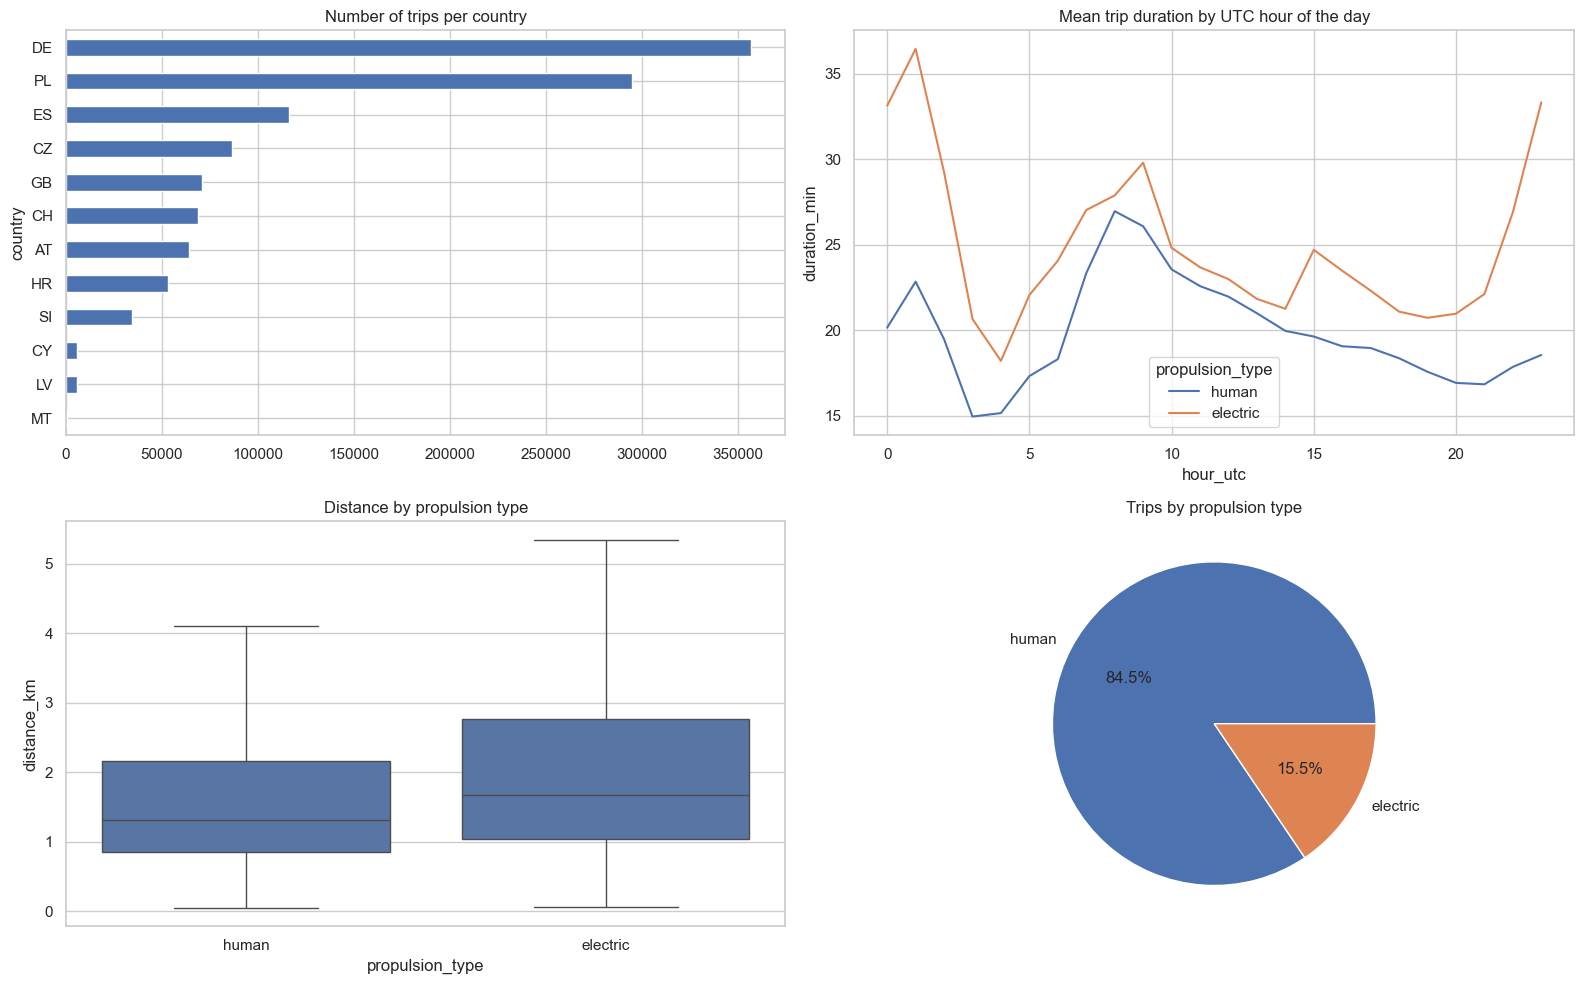

In [241]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
trips_c.groupby("country").size().sort_values().plot(kind="barh", ax=axes[0, 0], title="Number of trips per country")
sns.lineplot(data=trips_c, x="hour_utc", y="duration_min", hue="propulsion_type", estimator="mean", errorbar=None, ax=axes[0, 1])
axes[0, 1].set_title("Mean trip duration by UTC hour of the day")
sns.boxplot(data=trips_c, x="propulsion_type", y="distance_km", showfliers=False, ax=axes[1, 0])
axes[1, 0].set_title("Distance by propulsion type")
trips_c["propulsion_type"].value_counts().plot(kind="pie", autopct="%1.1f%%", ax=axes[1, 1], title="Trips by propulsion type")
axes[1, 1].set_ylabel("")
plt.tight_layout()
plt.show()

In [242]:
rto = (trips_c.merge(city[["id", "return_to_official_only"]], left_on="city_id", right_on="id", how="left")
       .groupby("return_to_official_only")
       .agg(trips=("bike_id", "size"), free_start_pct=("free_start", lambda x: x.mean() * 100),
            free_end_pct=("free_end", lambda x: x.mean() * 100)))
display(rto)

,trips,free_start_pct,free_end_pct
return_to_official_only,,,
False,200830,10.633869,15.280586
True,958200,7.079107,9.516281


In [243]:
type_summary = (trips_c.groupby("bike_type_group")
                .agg(trips=("bike_id", "size"), bikes=("bike_id", "nunique"),
                     median_duration_min=("duration_min", "median"), median_distance_km=("distance_km", "median"),
                     electric_share=("propulsion_type", lambda s: (s == "electric").mean()))
                .sort_values("trips", ascending=False))
display(type_summary.round(2))

,trips,bikes,median_duration_min,median_distance_km,electric_share
bike_type_group,,,,,
City bike,971977,22258,12.0,1.31,0.0
E-bike,179996,3202,13.0,1.67,1.0
Bike with child seat,3504,108,18.0,1.40,0.0
Unknown,1298,110,16.0,1.75,0.0
Cargo bike,830,49,16.0,1.01,0.0
Tandem,638,25,18.0,1.32,0.0
Kids bike,622,67,21.0,1.11,0.0
E-cargo bike,95,10,26.0,2.86,1.0
Tricycle,70,4,19.5,1.20,0.0


**Insights**

* Germany and Poland together account for more than half of the trips, and 85% of the trips are on human-powered bikes (15% electric)

* Electric trips are longer in distance and in time.

* In schemes that allow free returns, 10.6% of the trips start and 15.3% end outside a station. Even in schemes that require official returns, 7.1% start and 9.5% end outside a station.

#### 2.5.1 Audit of the preparation: before and after

In [244]:
audit = pd.DataFrame({
    "table": ["bike types", "stations", "station status", "trips"],
    "rows_raw": [len(types), len(station), len(station_status), len(trips)],
    "rows_prepared": [len(types_c), len(station_c), len(status), len(trips_c)],
    "columns_raw": [types.shape[1], station.shape[1], station_status.shape[1], trips.shape[1]],
    "columns_prepared": [types_c.shape[1], station_c.shape[1], status.shape[1], trips_c.shape[1]],
})
audit["rows_removed"] = audit["rows_raw"] - audit["rows_prepared"]
audit["removed_percent"] = (audit["rows_removed"] / audit["rows_raw"] * 100).round(3)
display(audit)

,table,rows_raw,rows_prepared,columns_raw,columns_prepared,rows_removed,removed_percent
0,bike types,121,121,9,10,0,0.000
1,stations,2932,2932,12,19,0,0.000
2,station status,2925967,2925807,12,15,160,0.005
3,trips,1161376,1159030,13,32,2346,0.202


In [245]:
# Why were status rows affected? (the reasons can overlap)
n_not_in_stations = int((~station_status["station_id"].isin(station_c["id"])).sum())
n_duplicates = int(station_status.duplicated(["station_id", "time"]).sum())
n_impossible = int(((station_status[COUNT_COLUMNS] < 0).any(axis=1)
                    | (station_status["bikes_available_to_rent"] > station_status["bikes"])).sum())
n_booked_above_bikes = int((station_status["booked_bikes"] > station_status["bikes"]).sum())
n_trips_dropped = len(trips) - len(trips_c)

print("Status rows of stations missing in stations.csv:", n_not_in_stations)
print("Duplicated (station_id, time) rows:             ", n_duplicates)
print("Impossible rows (dropped):                      ", n_impossible)
print("Rows with booked_bikes > bikes (kept):          ", n_booked_above_bikes)
print("Trips dropped (unknown propulsion or form):     ", n_trips_dropped)

Status rows of stations missing in stations.csv: 0
Duplicated (station_id, time) rows:              0
Impossible rows (dropped):                       160
Rows with booked_bikes > bikes (kept):           2271
Trips dropped (unknown propulsion or form):      2346


In [246]:
# Missing values left in the prepared tables
for name, frame in {"bike types": types_c, "stations": station_c, "station status": status, "trips": trips_c}.items():
    left = frame.isna().sum()
    left = left[left > 0]
    print(name, "->", left.to_dict() if len(left) else "no missing values")

bike types -> no missing values
stations -> no missing values
station status -> no missing values
trips -> {'station_id_start': 89188, 'station_id_end': 121873, 'battery_start': 990498, 'battery_end': 990389}


### 2.6 Summary of the cleaning decisions

In [247]:
cleaning_log = pd.DataFrame([
    ["Impossible status rows (negative count or available > bikes)", n_impossible,
     "Dropped in prepare_status", "They violate physical laws"],
    ["booked_bikes > bikes (available forced to 0)", n_booked_above_bikes,
     "Kept", "Likely a data entry error or a specific system code, but we lack context to change it safely."],
    ["Status rows of stations missing in stations.csv", n_not_in_stations,
     "Dropped in prepare_status", "We cannot model a station if we don't have its physical metadata"],
    ["Duplicated (station_id, time)", n_duplicates,
     "Dropped in prepare_status", "Exact duplicates at the same timestamp provide no new information and would artificially bias the model."],
    ["Stations with zero regular racks", int(station_c["zero_regular_racks_flag"].sum()),
     "Flag zero_regular_racks_flag, value kept", "These represent virtual, free-floating, or special-only zones, not physical docking errors."],
    ["Stations with negative special_racks", int(station_c["negative_special_racks_flag"].sum()),
     "Flag negative_special_racks_flag, value kept", "Likely a data entry error or a specific system code, but we lack context to change it safely."],
    ["Stations with suspicious coordinates", int(station_c["coord_suspect_flag"].sum()),
     "Flag coord_suspect_flag, coordinates kept", " Coordinates >200km from median. Kept because regional schemes exist, but flagged in case of GPS drift."],
    ["Missing terminal_type", int(station["terminal_type"].isna().sum()),
     "Filled with 'Unknown'", "Filled with 'unknown'"],
    ["rack_locks entirely empty", int(station["rack_locks"].isna().sum()),
     "Column dropped", "A column with 100% missing values. It won't provide any significant information during model creation"],
    ["Bike types with unknown propulsion / form factor", int((types["propulsion_type"].isna()).sum()),
     "Kept as 'Unknown'; trips on them dropped", "We know the bike exists, but we cannot safely guess if it's electric or human"],
    ["Trips dropped (unknown propulsion or form factor)", n_trips_dropped,
     "Dropped in clean_trips", "We cannot safely guess the bike type from the trip alone."],
], columns=["problem", "rows_or_items_affected", "action_in_code", "reason (write it yourself)"])
display(cleaning_log)

,problem,rows_or_items_affected,action_in_code,reason (write it yourself)
0,Impossible status rows (negative count or avai...,160,Dropped in prepare_status,They violate physical laws
1,booked_bikes > bikes (available forced to 0),2271,Kept,Likely a data entry error or a specific system...
2,Status rows of stations missing in stations.csv,0,Dropped in prepare_status,We cannot model a station if we don't have its...
3,"Duplicated (station_id, time)",0,Dropped in prepare_status,Exact duplicates at the same timestamp provide...
4,Stations with zero regular racks,1220,"Flag zero_regular_racks_flag, value kept","These represent virtual, free-floating, or spe..."
5,Stations with negative special_racks,32,"Flag negative_special_racks_flag, value kept",Likely a data entry error or a specific system...
6,Stations with suspicious coordinates,4,"Flag coord_suspect_flag, coordinates kept",Coordinates >200km from median. Kept because ...
7,Missing terminal_type,587,Filled with 'Unknown',Filled with 'unknown'
8,rack_locks entirely empty,2932,Column dropped,A column with 100% missing values. It won't pr...
9,Bike types with unknown propulsion / form factor,30,Kept as 'Unknown'; trips on them dropped,"We know the bike exists, but we cannot safely ..."


## 3. Unsupervised tasks: Bike Trip and Station Profiles

### 3.1 Part A - Clustering Bike Trips

Each **trip** is an observation. To keep KMeans and the silhouette fast, we reduce the number of trips: we use a random sample of 200,000 trips from `trips_c` and describe each trip with 5 **active** features, used for the clustering:

- `log_duration`, `log_distance`: duration and distance are very right-skewed, so we take the log
- `speed_kmh`: distance / duration, clipped at the 99th percentile to remove impossible speeds
- `hour_sin`, `hour_cos`: local start hour on a circle, so that 23h and 0h are close

We also tried a `round_trip` flag (trip ending at its start station), but no trip in the data ends at its start station, so this feature is constant and was dropped.

5 **supplementary** features (`is_weekend_local`, `electric`, `cargo`, `free_start`, `free_end`) are not used by KMeans, only to describe the clusters afterwards. The active features are standardised and reduced with PCA (90% of the variance) before KMeans.

#### Trip features

In [248]:
trips_a = trips_c.sample(n=min(200_000, len(trips_c)), random_state=RANDOM_STATE).copy()

trips_a['log_duration'] = np.log(trips_a['duration_min'])
trips_a['log_distance'] = np.log(trips_a['distance_km'])
trips_a['speed_kmh'] = trips_a['distance_km'] / (trips_a['duration_min'] / 60)
trips_a['speed_kmh'] = trips_a['speed_kmh'].clip(upper=trips_a['speed_kmh'].quantile(0.99))
trips_a['hour_sin'] = np.sin(2 * np.pi * trips_a['hour_local'] / 24)
trips_a['hour_cos'] = np.cos(2 * np.pi * trips_a['hour_local'] / 24)
trips_a['electric'] = (trips_a['propulsion_type'] == 'electric').astype(int)
trips_a['cargo'] = (trips_a['form_factor'] == 'cargo').astype(int)

TRIP_ACTIVE = ['log_duration', 'log_distance', 'speed_kmh', 'hour_sin', 'hour_cos']
TRIP_SUPPL = ['is_weekend_local', 'electric', 'cargo', 'free_start', 'free_end']

trips_a[TRIP_ACTIVE + TRIP_SUPPL].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
log_duration,200000.0,2.607,0.805,0.701,2.079,2.485,2.996,6.170
log_distance,200000.0,0.330,0.712,-2.985,-0.121,0.297,0.808,2.996
speed_kmh,200000.0,7.315,3.301,0.250,5.160,7.534,9.614,14.275
hour_sin,200000.0,-0.255,0.695,-1.000,-0.866,-0.500,0.259,1.000
hour_cos,200000.0,-0.297,0.602,-1.000,-0.866,-0.500,0.000,1.000
is_weekend_local,200000.0,0.230,0.421,0.000,0.000,0.000,0.000,1.000
electric,200000.0,0.156,0.363,0.000,0.000,0.000,0.000,1.000
cargo,200000.0,0.001,0.026,0.000,0.000,0.000,0.000,1.000
free_start,200000.0,0.077,0.266,0.000,0.000,0.000,0.000,1.000
free_end,200000.0,0.104,0.305,0.000,0.000,0.000,0.000,1.000


#### PCA on the active features

We keep the number of components needed for 90% of the variance.

Components for 90% of the variance: 4 (out of 5)


,explained_variance_ratio,cumulative
PC1,0.314,0.314
PC2,0.278,0.592
PC3,0.240,0.832
PC4,0.158,0.990
PC5,0.010,1.000


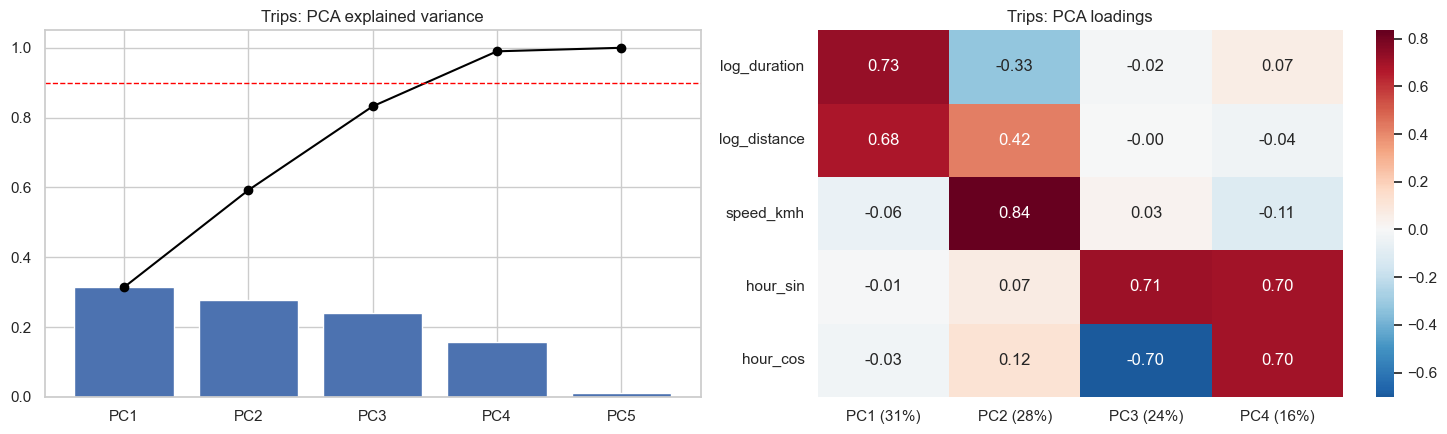

In [249]:
trip_scaler = StandardScaler().fit(trips_a[TRIP_ACTIVE])
X_trips = trip_scaler.transform(trips_a[TRIP_ACTIVE])
trip_pca = PCA(random_state=RANDOM_STATE).fit(X_trips)

trip_explained = pd.DataFrame({
    'explained_variance_ratio': trip_pca.explained_variance_ratio_,
    'cumulative': np.cumsum(trip_pca.explained_variance_ratio_),
}, index=[f'PC{i + 1}' for i in range(trip_pca.n_components_)])
trip_n_90 = int(np.argmax(trip_explained['cumulative'].values >= 0.90) + 1)
print(f"Components for 90% of the variance: {trip_n_90} (out of {trip_pca.n_components_})")
display(trip_explained.round(3))

trip_loadings = pd.DataFrame(
    trip_pca.components_[:trip_n_90].T, index=TRIP_ACTIVE,
    columns=[f'PC{i + 1} ({r:.0%})' for i, r in enumerate(trip_pca.explained_variance_ratio_[:trip_n_90])])

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].bar(trip_explained.index, trip_explained['explained_variance_ratio'])
axes[0].plot(trip_explained.index, trip_explained['cumulative'], color='black', marker='o')
axes[0].axhline(0.90, color='red', linestyle='--', linewidth=1)
axes[0].set_title('Trips: PCA explained variance')
sns.heatmap(trip_loadings, annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=axes[1])
axes[1].set_title('Trips: PCA loadings')
plt.tight_layout()
plt.show()

X_trips_pca = trip_pca.transform(X_trips)[:, :trip_n_90]

#### Choice of k

We compare k = 2 to 8 with the inertia (elbow) and the silhouette (computed on 20,000 trips).

,inertia,silhouette
k,,
2,791386.792,0.193
3,633611.272,0.240
4,529165.610,0.235
5,455686.956,0.250
6,415562.196,0.236
7,381802.017,0.232
8,354222.523,0.235


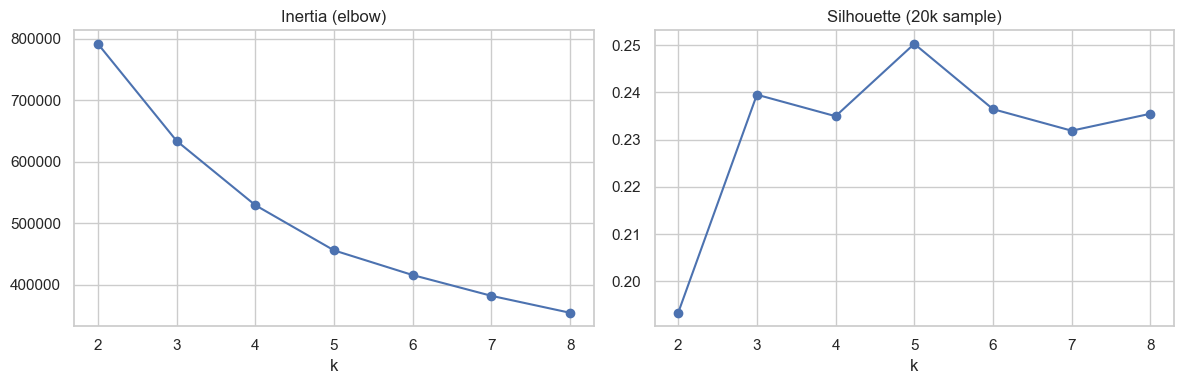

In [250]:
trip_k_scores = []
for k in range(2, 9):
    km_k = KMeans(k, n_init=10, random_state=RANDOM_STATE).fit(X_trips_pca)
    sil = silhouette_score(X_trips_pca, km_k.labels_, sample_size=20_000, random_state=RANDOM_STATE)
    trip_k_scores.append({'k': k, 'inertia': km_k.inertia_, 'silhouette': sil})
trip_k_scores = pd.DataFrame(trip_k_scores).set_index('k')
display(trip_k_scores.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
trip_k_scores['inertia'].plot(marker='o', ax=axes[0], title='Inertia (elbow)')
trip_k_scores['silhouette'].plot(marker='o', ax=axes[1], title='Silhouette (20k sample)')
plt.tight_layout()
plt.show()

*Choice of k = 5.* The two criteria point to the same value:

- *Silhouette*: it is highest for k = 5 (0.250), against 0.240 for k = 3, 0.235 for k = 4 and 0.236 for k = 6.
- *Inertia *: each extra cluster removes 20%, 16% and 14% of the inertia up to k = 5, then only 9%, 8% and 7% after. The curve bends at k = 5.

We keep *k = 5*

#### Final clustering

In [251]:
TRIP_K = 5

km_trips = KMeans(TRIP_K, n_init=10, random_state=RANDOM_STATE).fit(X_trips_pca)
trips_a['trip_cluster'] = km_trips.labels_
trips_a['trip_cluster'].value_counts(normalize=True).sort_index().round(3)

trip_cluster
0    0.236
1    0.202
2    0.213
3    0.210
4    0.139
Name: proportion, dtype: float64

#### Cluster profiles

Profiles in real units, then as z-scores against the whole sample (the last 5 rows of the heatmap are the supplementary features, not used for the clustering).

,share,median_duration_min,median_distance_km,median_speed_kmh,median_hour_local,pct_weekend,pct_electric,pct_cargo,pct_free_start,pct_free_end
trip_cluster,,,,,,,,,,
0,0.236,7.0,0.782,6.448,15.0,0.189,0.111,0.001,0.111,0.147
1,0.202,10.0,1.314,8.594,8.0,0.160,0.145,0.000,0.058,0.091
2,0.213,11.0,1.348,7.794,20.0,0.292,0.170,0.000,0.071,0.101
3,0.210,16.0,2.498,9.835,15.0,0.242,0.207,0.000,0.057,0.084
4,0.139,50.0,1.621,2.052,14.0,0.287,0.148,0.002,0.083,0.084


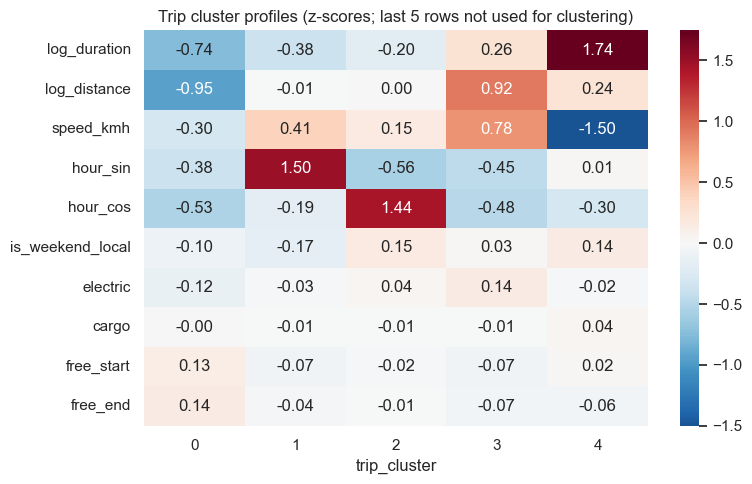

In [252]:
trip_profile_a = trips_a.groupby('trip_cluster').agg(
    share=('trip_cluster', lambda s: len(s) / len(trips_a)),
    median_duration_min=('duration_min', 'median'),
    median_distance_km=('distance_km', 'median'),
    median_speed_kmh=('speed_kmh', 'median'),
    median_hour_local=('hour_local', 'median'),
    pct_weekend=('is_weekend_local', 'mean'),
    pct_electric=('electric', 'mean'),
    pct_cargo=('cargo', 'mean'),
    pct_free_start=('free_start', 'mean'),
    pct_free_end=('free_end', 'mean'),
)
display(trip_profile_a.round(3))

cols_z = TRIP_ACTIVE + TRIP_SUPPL
z = (trips_a[cols_z] - trips_a[cols_z].mean()) / trips_a[cols_z].std()
plt.figure(figsize=(8, 5))
sns.heatmap(z.groupby(trips_a['trip_cluster']).mean().T, annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title('Trip cluster profiles (z-scores; last 5 rows not used for clustering)')
plt.tight_layout()
plt.show()

#### Start hour of the trips of each cluster (weekday vs weekend)

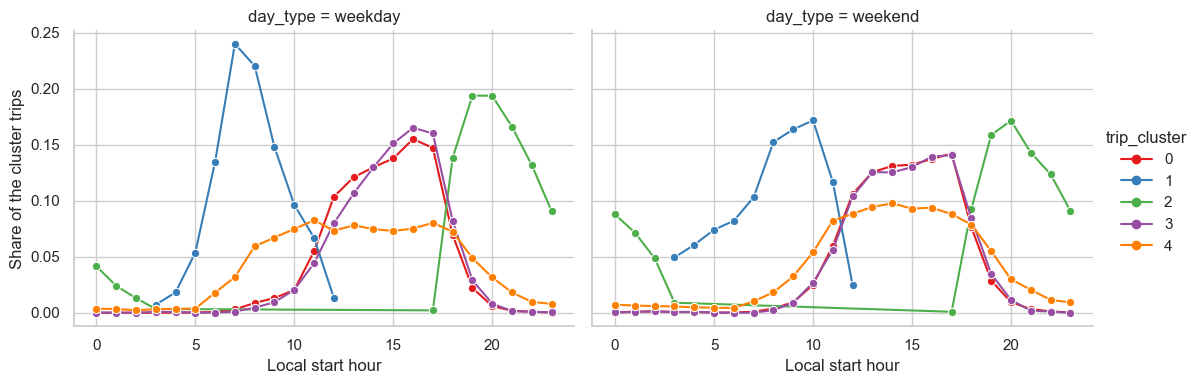

In [253]:
hour_share = (trips_a.groupby(['trip_cluster', 'is_weekend_local', 'hour_local']).size()
              .groupby(level=[0, 1]).transform(lambda s: s / s.sum())
              .rename('share').reset_index())
hour_share['day_type'] = hour_share['is_weekend_local'].map({0: 'weekday', 1: 'weekend'})

g = sns.relplot(data=hour_share, x='hour_local', y='share', hue='trip_cluster', col='day_type',
                kind='line', marker='o', palette='Set1', height=4, aspect=1.4)
g.set_axis_labels('Local start hour', 'Share of the cluster trips')
plt.show()

#### Stability check

KMeans is refitted on a second independent sample of 200,000 trips. An ARI close to 1 means the clusters do not depend on the sample.

In [254]:
other = trips_c.drop(trips_a.index, errors='ignore').sample(
    n=min(200_000, max(len(trips_c) - len(trips_a), 1)), random_state=RANDOM_STATE + 1)
other = other.assign(
    log_duration=np.log(other['duration_min']),
    log_distance=np.log(other['distance_km']),
    speed_kmh=(other['distance_km'] / (other['duration_min'] / 60)).clip(upper=trips_a['speed_kmh'].max()),
    hour_sin=np.sin(2 * np.pi * other['hour_local'] / 24),
    hour_cos=np.cos(2 * np.pi * other['hour_local'] / 24),
)
X_other = trip_pca.transform(trip_scaler.transform(other[TRIP_ACTIVE]))[:, :trip_n_90]
km_other = KMeans(TRIP_K, n_init=10, random_state=RANDOM_STATE + 1).fit(X_other)
print(f"ARI KMeans sample 1 vs sample 2 (on sample 1): "
      f"{adjusted_rand_score(km_trips.labels_, km_other.predict(X_trips_pca)):.3f}")

ARI KMeans sample 1 vs sample 2 (on sample 1): 0.944


#### Are the clusters just countries?

If each cluster came mostly from one country, it would describe a place rather than a type of trip.

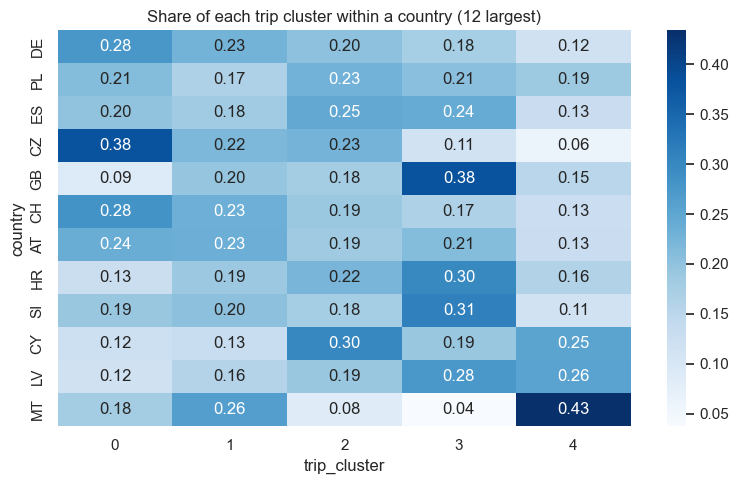

In [255]:
by_country = pd.crosstab(trips_a['country'], trips_a['trip_cluster'], normalize='index')
by_country = by_country.loc[trips_a['country'].value_counts().index[:12]]
plt.figure(figsize=(8, 5))
sns.heatmap(by_country, annot=True, fmt='.2f', cmap='Blues')
plt.title('Share of each trip cluster within a country (12 largest)')
plt.tight_layout()
plt.show()

#### Conclusion of Part A

**Choice of k.** We keep **k = 5**: it has the highest silhouette (0.250) and it is where the inertia curve bends. The silhouette stays low for every k (0.19 to 0.25).

**PCA.** 4 components keep 99% of the variance of the 5 features. PC1 (31%) is the trip length (`log_duration`, `log_distance`), PC2 (28%) the speed, PC3 and PC4 (24% and 16%) the start hour.

**Trip profiles (k = 5)**

- **Cluster 1 - morning trips** (20.2% of the trips): median 10 min, 1.3 km, 8.6 km/h. They start between 3h and 12h, with a strong peak at 7-8h on weekdays: commuting to work or school. It is the cluster with the fewest weekend trips (16%, vs 23% overall).
- **Cluster 0 - short afternoon trips** (23.6%): the shortest trips, median 7 min, 0.8 km, 6.4 km/h. They start between 11h and 18h, with a peak around 16h: short errands.
- **Cluster 3 - long and fast afternoon trips** (21.0%): median 16 min, 2.5 km, 9.8 km/h, with the same hours as cluster 0 (11h-18h). It has the highest share of electric bikes (21%, vs 16% overall).
- **Cluster 2 - evening and night trips** (21.3%): median 11 min, 1.3 km, 7.8 km/h. They start between 18h and 2h, with a peak at 19-20h: trips back home and evening outings. 29% of them are on weekends.
- **Cluster 4 - long and slow trips** (13.9%): median 50 min for only 1.6 km (2.1 km/h). The bike is kept for a long time with stops, which looks like leisure or tourism. They are spread over the whole day and 29% of them are on weekends.

The clusters are built on two axes: the trip type (short, long and fast, long and slow) and the time of day (morning, afternoon, evening). Clusters 0 and 3 start at the same hours and differ only by length and speed.

**Supplementary features.** Cargo bikes (less than 0.2%) are the same in all clusters. Free-floating trips are slightly more frequent in the short afternoon trips (cluster 0), electric bikes in the long and fast trips (cluster 3), and weekend trips in the evening (cluster 2) and long and slow (cluster 4) trips.

**Robustness.** The ARI between two independent samples is 0.94: KMeans finds the same clusters on other trips.

**Also,** The five clusters are present in every country. The mix still changes between countries: Czech Republic has 38% of short afternoon trips (cluster 0), Great Britain 38% of long and fast trips (cluster 3), and Malta 43% of long and slow trips (cluster 4).

Overall, the same five types of trips are found in all the countries, and they are mainly defined by the trip length, the speed and the time of day.

### 3.2 Part B - Clustering Bike-Sharing Stations

The goal is to detect whether there are residential stations, office stations, employment hubs, highly active stations, etc.

#### Feature engineering on station status

Firstly, we think that it could have a difference of use during the week between the days of work and the week-end.

In [256]:
status_fe = status.copy()

# Weekend flag (Monday=0, Sunday=6), from the UTC day of week computed in section 2.3
status_fe['weekend'] = status_fe['day_of_week_utc'] >= 5

We want insights on how the stations is used.

In [257]:
# 'capacity' = total number of places in a station
status_fe['capacity'] = status_fe['bikes'] + status_fe['free_racks']
n_before = len(status_fe)
status_fe = status_fe[status_fe['capacity'] > 0]
print("Snapshots removed because the station has no capacity:", n_before - len(status_fe))

Snapshots removed because the station has no capacity: 51560


In [258]:
# fill = rate of bikes in a station
status_fe['fill'] = status_fe['bikes'] / status_fe['capacity']

In [259]:
# empty = 1 if no bike is available to rent, 0 else
status_fe['empty'] = (status_fe['bikes_available_to_rent'] == 0).astype(int)
# full = 1 if the station is full, 0 else
status_fe['full'] = (status_fe['free_racks'] == 0).astype(int)

We are now able to describe each station in a data frame with one row per station.

In [260]:
by_station = status_fe.groupby('station_id')

station_feat = pd.DataFrame({
    'fill_mean': by_station['fill'].mean(),
    'fill_std': by_station['fill'].std(),
    'pct_empty': by_station['empty'].mean(),
    'pct_full': by_station['full'].mean(),
    'pct_maint': by_station['maintenance'].mean(),
})
# fill_std: a high value indicates a station whose stock changes a lot, a low value a stable one

We want to distinguish the use of station according the period of the day

In [261]:
# time slots of the day (UTC hours)
status_fe['slot'] = pd.cut(status_fe['hour_utc'], [-3, 7, 12, 19, 21],
                           labels=['night', 'morning', 'afternoon', 'evening'])
status_fe

,station_id,time,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks,maintenance,datetime,month,...,weekday_utc,day_of_week_utc,hour_local,day_of_week_local,weekend,capacity,fill,empty,full,slot
0,101896428,1.661530e+09,2,0,2,0,0,0,2022-08-26 16:14:01+00:00,2022-08,...,Friday,4,18,4,False,2,1.000000,0,1,afternoon
1,54643,1.661531e+09,1,0,1,0,0,0,2022-08-26 16:15:01+00:00,2022-08,...,Friday,4,18,4,False,1,1.000000,0,1,afternoon
2,6201611,1.661531e+09,3,0,3,0,0,0,2022-08-26 16:15:01+00:00,2022-08,...,Friday,4,18,4,False,3,1.000000,0,1,afternoon
3,294346,1.661531e+09,8,0,8,0,0,0,2022-08-26 16:15:01+00:00,2022-08,...,Friday,4,19,4,False,8,1.000000,0,1,afternoon
4,781866,1.661531e+09,1,1,0,5,0,0,2022-08-26 16:15:01+00:00,2022-08,...,Friday,4,19,4,False,6,0.166667,1,0,afternoon
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925802,4775132,1.689458e+09,4,0,4,0,0,0,2023-07-15 21:59:01+00:00,2023-07,...,Saturday,5,23,5,True,4,1.000000,0,1,evening
2925803,51009276,1.689458e+09,7,0,7,3,3,0,2023-07-15 21:59:01+00:00,2023-07,...,Saturday,5,23,5,True,10,0.700000,0,0,evening
2925804,142144382,1.689458e+09,8,0,8,8,0,0,2023-07-15 21:59:01+00:00,2023-07,...,Saturday,5,23,5,True,16,0.500000,0,0,evening
2925805,142141158,1.689458e+09,13,0,13,15,0,0,2023-07-15 21:59:01+00:00,2023-07,...,Saturday,5,23,5,True,28,0.464286,0,0,evening


In [262]:
slots = status_fe.pivot_table(index='station_id', columns='slot', values='fill', aggfunc='mean', observed=False)
slots

slot,night,morning,afternoon,evening
station_id,,,,
94,1.0,1.0,1.000000,NaN
522,1.0,1.0,1.000000,1.000000
556,1.0,1.0,1.000000,1.000000
568,1.0,1.0,1.000000,1.000000
572,1.0,1.0,1.000000,NaN
...,...,...,...,...
209690395,NaN,1.0,1.000000,1.000000
209691495,1.0,NaN,1.000000,NaN
214585310,1.0,1.0,1.000000,1.000000


In [263]:
station_feat = station_feat.join(slots.add_prefix('fill_'))
station_feat

,fill_mean,fill_std,pct_empty,pct_full,pct_maint,fill_night,fill_morning,fill_afternoon,fill_evening
station_id,,,,,,,,,
94,1.000000,0.000000,0.022989,1.0,0.0,1.0,1.0,1.000000,NaN
522,1.000000,0.000000,0.000000,1.0,0.0,1.0,1.0,1.000000,1.000000
556,1.000000,0.000000,0.000000,1.0,0.0,1.0,1.0,1.000000,1.000000
568,1.000000,0.000000,0.024590,1.0,0.0,1.0,1.0,1.000000,1.000000
572,1.000000,0.000000,0.000000,1.0,0.0,1.0,1.0,1.000000,NaN
...,...,...,...,...,...,...,...,...,...
209690395,1.000000,0.000000,0.000000,1.0,0.0,NaN,1.0,1.000000,1.000000
209691495,1.000000,0.000000,0.000000,1.0,0.0,1.0,NaN,1.000000,NaN
214585310,1.000000,0.000000,0.000000,1.0,0.0,1.0,1.0,1.000000,1.000000


In [264]:
# Week vs weekend: mean fill rate of each group
weekend_fill = status_fe.groupby(['station_id', 'weekend'])['fill'].mean().unstack()
weekend_fill

weekend,False,True
station_id,,
94,1.000000,1.00
522,1.000000,1.00
556,1.000000,1.00
568,1.000000,1.00
572,1.000000,1.00
...,...,...
209690395,1.000000,1.00
209691495,1.000000,1.00
214585310,1.000000,1.00


In [265]:
# if diff_we > 0, the station is more in demand during the weekend than during the rest of the week
# if diff_we < 0, the station is more in demand on weekdays
# else, similar usage all week long
station_feat['diff_we'] = weekend_fill[True] - weekend_fill[False]
station_feat

,fill_mean,fill_std,pct_empty,pct_full,pct_maint,fill_night,fill_morning,fill_afternoon,fill_evening,diff_we
station_id,,,,,,,,,,
94,1.000000,0.000000,0.022989,1.0,0.0,1.0,1.0,1.000000,NaN,0.000000
522,1.000000,0.000000,0.000000,1.0,0.0,1.0,1.0,1.000000,1.000000,0.000000
556,1.000000,0.000000,0.000000,1.0,0.0,1.0,1.0,1.000000,1.000000,0.000000
568,1.000000,0.000000,0.024590,1.0,0.0,1.0,1.0,1.000000,1.000000,0.000000
572,1.000000,0.000000,0.000000,1.0,0.0,1.0,1.0,1.000000,NaN,0.000000
...,...,...,...,...,...,...,...,...,...,...
209690395,1.000000,0.000000,0.000000,1.0,0.0,NaN,1.0,1.000000,1.000000,0.000000
209691495,1.000000,0.000000,0.000000,1.0,0.0,1.0,NaN,1.000000,NaN,0.000000
214585310,1.000000,0.000000,0.000000,1.0,0.0,1.0,1.0,1.000000,1.000000,0.000000


In [266]:
station_feat = station_feat.join(STATION_INFO[['bike_racks', 'lon', 'lat']])
#reduce the mean and std using log(x+1)
#log1p can handle null values. And, the distribution  of "bike_racks" is asymetric: alot of meadum-sized station and few very large ones.
# so we use log1p to bring the distribution closer to a more symmetrical form.
station_feat['bike_racks'] = np.log1p(station_feat['bike_racks'])

#### PCA before clustering

The station clustering uses 13 correlated features (fill rate per time slot, `pct_empty`, `pct_full`, ...). Before running KMeans we reduce them with PCA, which

1. removes the redundancy between features (the fill rates of neighbouring time slots are strongly correlated),
2. keeps a handful of uncorrelated components, so that no group of similar features dominates the distance used by KMeans,
3. gives axes we can interpret through their loadings.

The features are standardised first (PCA is scale-sensitive). `lon` and `lat` are still excluded, they are only used to draw the clusters.

['fill_mean', 'fill_std', 'pct_empty', 'pct_full', 'pct_maint', 'fill_night', 'fill_morning', 'fill_afternoon', 'fill_evening', 'diff_we', 'bike_racks']
Components needed for 90% of the variance: 4 (out of 11)


,explained_variance_ratio,cumulative
PC1,0.675,0.675
PC2,0.094,0.768
PC3,0.090,0.859
PC4,0.084,0.943
PC5,0.035,0.978
PC6,0.010,0.988
PC7,0.005,0.993
PC8,0.004,0.997
PC9,0.002,0.999
PC10,0.001,1.000


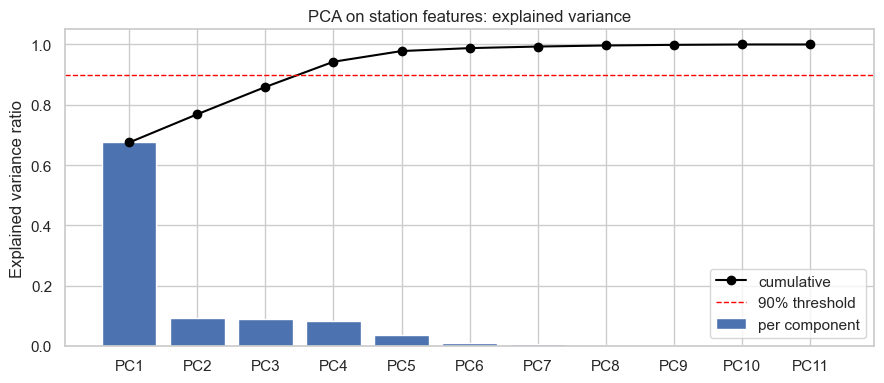

In [267]:
# lon and lat are not used for the clustering (only to draw the clusters)
feat_cols = [c for c in station_feat.columns if c not in ['lon', 'lat']]
print(feat_cols)
X_stations = StandardScaler().fit_transform(station_feat[feat_cols].dropna())

pca_full = PCA(random_state=RANDOM_STATE).fit(X_stations)

explained = pd.DataFrame({
    'explained_variance_ratio': pca_full.explained_variance_ratio_,
    'cumulative': np.cumsum(pca_full.explained_variance_ratio_),
}, index=[f'PC{i + 1}' for i in range(pca_full.n_components_)])

# number of components needed to keep at least 90% of the variance
n_90 = int(np.argmax(explained['cumulative'].values >= 0.90) + 1)
print(f"Components needed for 90% of the variance: {n_90} (out of {pca_full.n_components_})")
display(explained.round(3))

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(explained.index, explained['explained_variance_ratio'], label='per component')
ax.plot(explained.index, explained['cumulative'], color='black', marker='o', label='cumulative')
ax.axhline(0.90, color='red', linestyle='--', linewidth=1, label='90% threshold')
ax.set_ylabel('Explained variance ratio')
ax.set_title('PCA on station features: explained variance')
ax.legend()
plt.tight_layout()
plt.show()

##### Loadings: which features drive each component

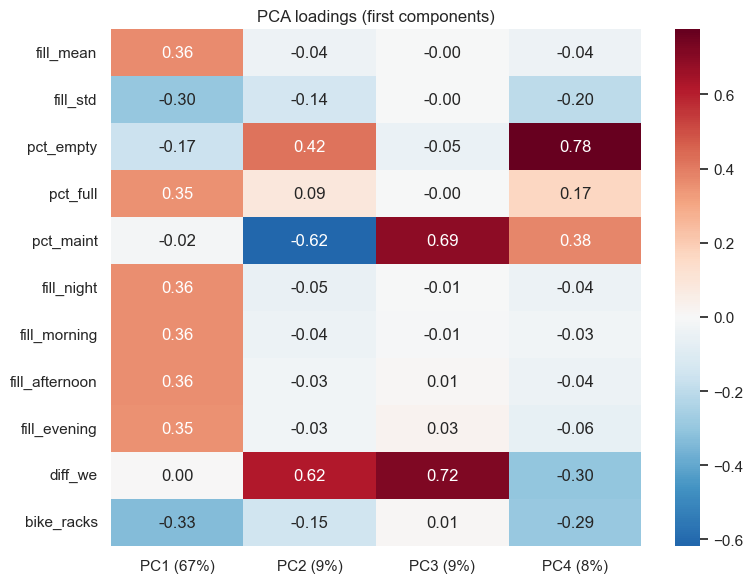

PC1 (67%): ['fill_mean', 'fill_afternoon', 'fill_morning']
PC2 (9%): ['diff_we', 'pct_maint', 'pct_empty']
PC3 (9%): ['diff_we', 'pct_maint', 'pct_empty']
PC4 (8%): ['pct_empty', 'pct_maint', 'diff_we']


In [268]:
n_show = min(4, pca_full.n_components_)
loadings = pd.DataFrame(
    pca_full.components_[:n_show].T,
    index=feat_cols,
    columns=[f'PC{i + 1} ({pca_full.explained_variance_ratio_[i]:.0%})' for i in range(n_show)],
)

plt.figure(figsize=(8, 6))
sns.heatmap(loadings, annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title('PCA loadings (first components)')
plt.tight_layout()
plt.show()

# strongest features for each of the first components
for col in loadings.columns:
    top = loadings[col].abs().sort_values(ascending=False).head(3).index.tolist()
    print(f"{col}: {top}")

**PCA results.** PC1 explains 70% of the variance and is an occupancy axis (`fill_mean`, `fill_midi`, `fill_soir`): the fill rates of the different time slots are almost identical for a given station, so these features are highly redundant. PC2 to PC4 explain 8-9% each and mix `pct_maint`, `pct_empty`, `diff_we` and `bike_racks` (unavailability and station size); as their variances are close, they should be read together rather than one by one. 4 components keep 94.5% of the variance (12 features before), so we cluster on these 4 components.

##### Data used for the clustering

The clustering below uses the first `n_90` principal components (`X_pca`), i.e. 90% of the variance of the standardised features.

In [269]:
scores = pca_full.transform(X_stations)
X_pca = scores[:, :n_90]
print(X_pca.shape)

(2599, 4)


#### Choice of k

In [270]:
for k in range(2, 9):
    # n_init=10: the algorithm restarts 10 times with different centers
    km = KMeans(k, n_init=10, random_state=RANDOM_STATE).fit(X_pca)
    # km.inertia_: sum of the squared distances between each station and the center of its cluster
    print(k, silhouette_score(X_pca, km.labels_), km.inertia_)

2 0.6253546737726545 10104.369519011372
3 0.6505045762731793 7885.629137700143
4 0.5434890442452287 5741.036273709618
5 0.5213269522866621 4695.06541973964
6 0.5203920177038268 3998.9477421480005
7 0.5136081249954566 3559.0255849889604
8 0.5150431928115725 3198.9420348190843


The silhouette is highest for k = 2 (0.63), then drops at k = 3 (0.52) and rises again at k = 4 (0.55) before staying flat around 0.52-0.53. k = 2 would only split the out-of-service and the always-full stations from the rest, so we keep **k = 4**, the local maximum, which also separates stations with different fill levels.

#### Final clustering (k = 4) on the PCA scores

In [271]:
station_feat_ok = station_feat[feat_cols].dropna().copy()
# k = 4 was the value kept before adding PCA: check it against the silhouette / inertia above and change it if needed
km_stations = KMeans(4, n_init=10, random_state=RANDOM_STATE).fit(X_pca)
station_feat_ok['cluster'] = km_stations.labels_
# Add lon and lat to draw the clusters
station_feat_ok = station_feat_ok.join(station_feat[['lon', 'lat']])
print(station_feat_ok['cluster'].value_counts().sort_index())

cluster
0    1068
1     947
2     513
3      71
Name: count, dtype: int64


In [272]:
# Description of each cluster
cluster_profile = station_feat_ok.groupby('cluster')[feat_cols].mean().round(2)
print(cluster_profile.T)

cluster            0     1     2     3
fill_mean       1.00  0.60  0.33  0.64
fill_std        0.01  0.23  0.21  0.17
pct_empty       0.02  0.02  0.11  0.04
pct_full        0.99  0.15  0.03  0.34
pct_maint       0.00  0.00  0.00  0.99
fill_night      1.00  0.61  0.33  0.65
fill_morning    1.00  0.60  0.33  0.64
fill_afternoon  1.00  0.60  0.33  0.64
fill_evening    1.00  0.61  0.33  0.65
diff_we         0.00 -0.01  0.01 -0.00
bike_racks      0.06  2.33  2.34  1.74


- **Cluster 0** (68 stations): `pct_maint` = 0.99, out-of-service stations
- **Cluster 1** (890 stations): `fill_mean` = 0.61, active stations, `bike_racks` = 2.32 (about 10 docks), rarely empty (`pct_empty` = 0.02) and rarely full (`pct_full` = 0.16)
- **Cluster 2** (1,079 stations): `fill_mean` = 1 and `pct_full` = 0.99, always full, `bike_racks` = 0.06: these stations have almost no docks, so capacity = bikes and the fill rate is 1 by construction. They are virtual / free-floating stations rather than stations that are really full
- **Cluster 3** (552 stations): `fill_mean` = 0.33, low occupancy, the most often empty (`pct_empty` = 0.11), `bike_racks` = 2.37

`diff_we` is about 0 for all clusters and the fill rates of the five time slots are almost equal inside each cluster, so the clusters are separated by the level of occupancy, availability and size, not by daily or weekly patterns.

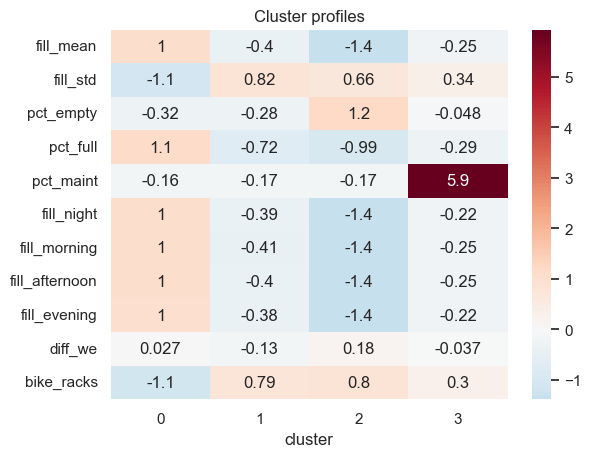

In [273]:
# Standardized version
cluster_profile_z = (pd.DataFrame(X_stations, columns=feat_cols, index=station_feat_ok.index)
                     .groupby(station_feat_ok['cluster']).mean())
sns.heatmap(cluster_profile_z.T, annot=True, cmap='RdBu_r', center=0)
plt.title("Cluster profiles")
plt.show()

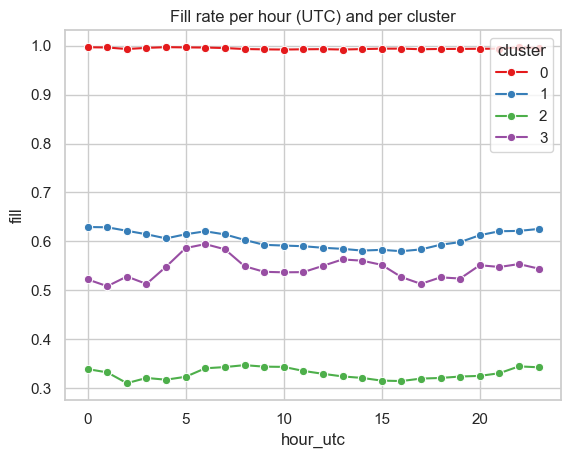

In [274]:
status_fe_cl = status_fe.merge(station_feat_ok[['cluster']], left_on='station_id', right_index=True)
hourly_fill = status_fe_cl.groupby(['cluster', 'hour_utc'])['fill'].mean().reset_index()
sns.lineplot(data=hourly_fill, x='hour_utc', y='fill', hue='cluster', palette="Set1", marker='o')
plt.title("Fill rate per hour (UTC) and per cluster")
plt.show()

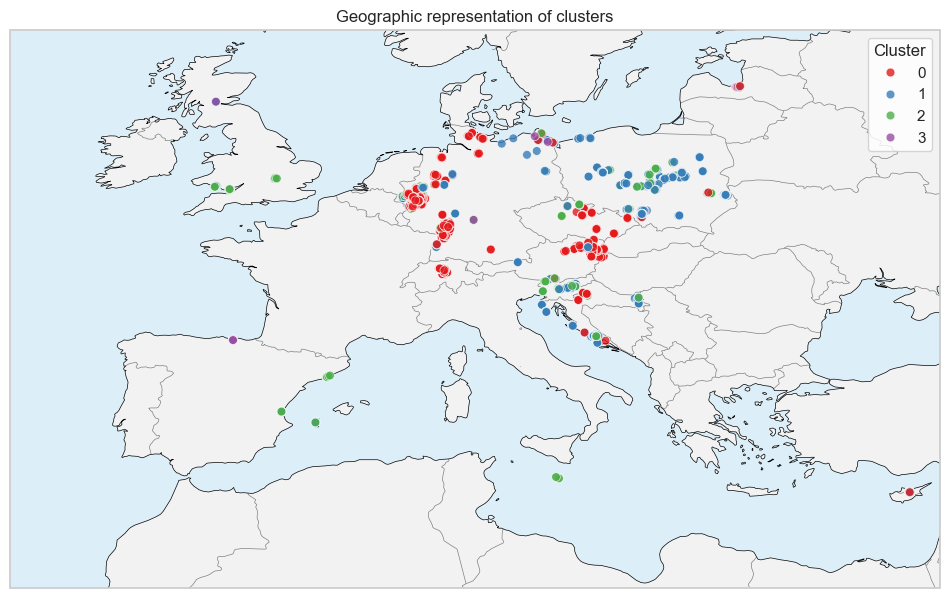

In [275]:
fig, ax = plt.subplots(figsize=(12, 8),subplot_kw={'projection': ccrs.PlateCarree()})

# I am adding the features like in cities 1.5
ax.add_feature(cfeature.LAND, facecolor='#f2f2f2')
ax.add_feature(cfeature.OCEAN, facecolor='#dceef7')
ax.add_feature(cfeature.BORDERS, edgecolor='gray', linewidth=0.5)
ax.add_feature(cfeature.COASTLINE, linewidth=0.5)

# Knowing that the stations are in Europe, I set the extent to focus on that region
ax.set_extent([-15, 35, 30, 60], crs=ccrs.PlateCarree())

# Clusters
sns.scatterplot(data=station_feat_ok,x='lon', y='lat',hue='cluster',palette='Set1',s=40, alpha=0.8, ax=ax, transform=ccrs.PlateCarree(), zorder=3)

ax.set_title("Geographic representation of clusters")
ax.legend(title="Cluster", loc="upper right")

plt.show()

#### Stability check: KMeans vs Ward

In [276]:
ward = AgglomerativeClustering(4).fit_predict(X_stations)
print("ARI KMeans vs ward :", adjusted_rand_score(km_stations.labels_, ward))
# ARI close to 1 means both methods find the same clustering ==> stable clustering

ARI KMeans vs ward : 0.8442441606391388


##### Clusters in the PCA plane

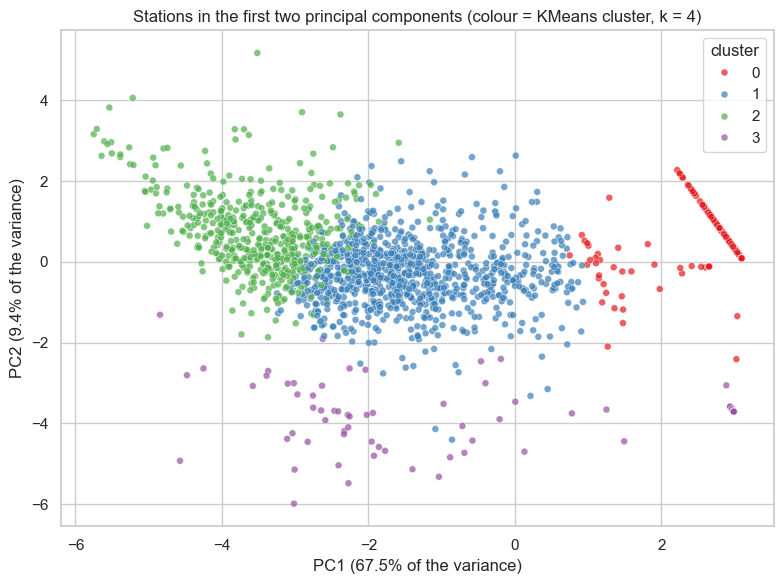

In [277]:
scores = pca_full.transform(X_stations)
pca_df = pd.DataFrame(scores[:, :2], columns=['PC1', 'PC2'], index=station_feat_ok.index)
pca_df['cluster'] = station_feat_ok['cluster']

fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='cluster', palette='Set1', s=25, alpha=0.7, ax=ax)
ax.set_xlabel(f"PC1 ({pca_full.explained_variance_ratio_[0]:.1%} of the variance)")
ax.set_ylabel(f"PC2 ({pca_full.explained_variance_ratio_[1]:.1%} of the variance)")
ax.set_title('Stations in the first two principal components (colour = KMeans cluster, k = 4)')
plt.tight_layout()
plt.show()

In the PC1/PC2 plane, the clusters are ordered along PC1 (occupancy): low-fill stations (3) on the left, active stations (1) in the middle, always-full stations (2) on the right. The out-of-service stations (0) are separated along PC2. The alignment of cluster 2 along a line comes from the stations with no docks, whose features are almost identical.

##### Robustness: clustering on the PCA scores vs on the raw standardised features

In [278]:
# The clustering was done on the PCA scores (X_pca). Does it differ from KMeans on all standardised features?
km_raw = KMeans(4, n_init=10, random_state=RANDOM_STATE).fit(X_stations)

print(f"Silhouette on {n_90} PCA components    : {silhouette_score(X_pca, km_stations.labels_):.3f}")
print(f"Silhouette on standardised features  : {silhouette_score(X_stations, km_raw.labels_):.3f}")
print(f"ARI PCA-based vs raw-feature KMeans  : {adjusted_rand_score(km_stations.labels_, km_raw.labels_):.3f}")
# ARI close to 1 means that reducing the dimension with PCA does not change the station profiles

Silhouette on 4 PCA components    : 0.543
Silhouette on standardised features  : 0.511
ARI PCA-based vs raw-feature KMeans  : 0.883


**Robustness.** The ARI between KMeans and Ward on the PCA scores is 0.82, and between the PCA-based and the raw-feature KMeans it is 0.93: the profiles are stable and PCA mostly removes redundancy. The silhouette is slightly higher on the PCA scores (0.55) than on the standardised features (0.52). The 2,589 stations kept for the clustering are those with no missing feature (some stations have no snapshot in some time slots).

#### 3.3 Link between trip clusters Part A and Part B

Every trip of `trips_c` is assigned to a trip cluster with the scaler, PCA and KMeans fitted in Part A. We then look at which trip clusters start from each station cluster.

Trips starting at a clustered station: 1050137 / 1159030


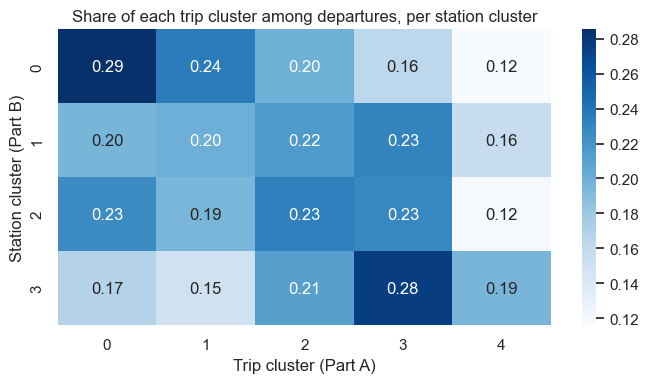

In [279]:
all_t = trips_c[['station_id_start', 'duration_min', 'distance_km', 'hour_local']].copy()
all_t['log_duration'] = np.log(all_t['duration_min'])
all_t['log_distance'] = np.log(all_t['distance_km'])
all_t['speed_kmh'] = (all_t['distance_km'] / (all_t['duration_min'] / 60)).clip(upper=trips_a['speed_kmh'].max())
all_t['hour_sin'] = np.sin(2 * np.pi * all_t['hour_local'] / 24)
all_t['hour_cos'] = np.cos(2 * np.pi * all_t['hour_local'] / 24)
all_t['trip_cluster'] = km_trips.predict(
    trip_pca.transform(trip_scaler.transform(all_t[TRIP_ACTIVE]))[:, :trip_n_90])

dep = all_t.dropna(subset=['station_id_start']).merge(
    station_feat_ok[['cluster']].rename(columns={'cluster': 'station_cluster'}),
    left_on='station_id_start', right_index=True, how='inner')
print(f"Trips starting at a clustered station: {len(dep)} / {len(all_t)}")

link = pd.crosstab(dep['station_cluster'], dep['trip_cluster'], normalize='index')
plt.figure(figsize=(7, 4))
sns.heatmap(link, annot=True, fmt='.2f', cmap='Blues')
plt.title('Share of each trip cluster among departures, per station cluster')
plt.xlabel('Trip cluster (Part A)')
plt.ylabel('Station cluster (Part B)')
plt.tight_layout()
plt.show()

- 1,050,137 of the 1,159,030 trips (91%) start at a station kept in the Part B clustering.
- The mix of trip types is similar in all station clusters (each trip cluster represents between 12% and 29% of the departures): the type of station does not decide the type of trip.
- Always-full stations (station cluster 0) have more short afternoon trips (29%, vs 20-23% elsewhere) and more morning trips (24%, vs 15-20%).
- Active stations (station cluster 1) and low-fill stations (station cluster 2) have a balanced mix of the five trip types.
- Stations flagged in maintenance (station cluster 3) have more long trips, fast (28%) or slow (19%).

## 4. Supervised Task: Predict Station Availability

### 4.1 Target construction

In [280]:
FFILL_LIMIT = 6
VALUE_COLUMNS = ["bikes_available_to_rent", "bikes", "free_racks", "maintenance"]

NUMERIC_FEATURES = [
    "bikes_available_to_rent", "bikes", "free_racks", "maintenance",
    "hours_since_obs", "lag_1h", "lag_2h", "lag_3h", "roll_mean_3h",
    "delta_1h", "departures", "arrivals", "net_flow",
    "departures_3h", "arrivals_3h", "hour_sin", "hour_cos",
    "is_weekend", "lat", "lon", "bike_racks", "special_racks",
    "total_declared_racks"
]
CATEGORICAL_FEATURES = ["country", "place_type", "terminal_type"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
TARGET = "y"

In [281]:
def clean_model_status(raw_status):
    s = raw_status.copy()
    s = s.drop_duplicates(["station_id", "time"], keep="last")
    s["datetime"] = pd.to_datetime(s["time"], unit="s", utc=True)
    count_cols = ["bikes", "bikes_available_to_rent", "free_racks", "free_special_racks"]
    valid_cols = [c for c in count_cols if c in s.columns]
    impossible = (s[valid_cols] < 0).any(axis=1)
    if {"bikes", "bikes_available_to_rent"}.issubset(s.columns):
        impossible |= s["bikes_available_to_rent"] > s["bikes"]
    s = s.loc[~impossible].copy()
    return s.sort_values(["station_id", "datetime"]).reset_index(drop=True)

In [282]:
def prepare_model_stations(raw_stations, city_metadata):
    keep = [
        "id", "city_id", "lat", "lon", "bike_racks", "special_racks",
        "place_type", "terminal_type"
    ]
    st = raw_stations[[c for c in keep if c in raw_stations.columns]].copy()
    for c in ["bike_racks", "special_racks", "lat", "lon"]:
        if c in st.columns:
            st[c] = pd.to_numeric(st[c], errors="coerce")
    if "special_racks" in st.columns:
        st["special_racks"] = st["special_racks"].clip(lower=0)
    if "bike_racks" not in st.columns:
        st["bike_racks"] = np.nan
    if "special_racks" not in st.columns:
        st["special_racks"] = np.nan
    st["total_declared_racks"] = st["bike_racks"] + st["special_racks"]
    for c in ["place_type", "terminal_type"]:
        if c not in st.columns:
            st[c] = "Unknown"
        st[c] = st[c].fillna("Unknown").astype(str)

    city_cols = [c for c in ["id", "country", "timezone"] if c in city_metadata.columns]
    if len(city_cols) > 1 and "city_id" in st.columns:
        cities = city_metadata[city_cols].rename(columns={"id": "city_id"})
        st = st.merge(cities, on="city_id", how="left", validate="many_to_one")
    else:
        st["country"] = "Unknown"
        st["timezone"] = np.nan
    st["country"] = st["country"].fillna("Unknown").astype(str)
    st["timezone"] = st["timezone"].fillna("UTC")
    return st

In [283]:
def prepare_model_trips(raw_trips):
    cols = ["station_id_start", "station_id_end", "time_start", "duration"]
    t = raw_trips[cols].drop_duplicates().copy()
    t["duration"] = pd.to_numeric(t["duration"], errors="coerce")
    t = t[t["duration"].between(0, 24 * 3600)].copy()
    t["start_utc"] = pd.to_datetime(t["time_start"], unit="s", utc=True)
    t["end_utc"] = t["start_utc"] + pd.to_timedelta(t["duration"], unit="s")
    return t


def make_trip_flow(trips_prepared):
    parts = []
    for station_col, time_col, flow_name in [
        ("station_id_start", "start_utc", "departures"),
        ("station_id_end", "end_utc", "arrivals")
    ]:
        part = trips_prepared.dropna(subset=[station_col]).copy()
        part["station_id"] = pd.to_numeric(part[station_col], errors="coerce")
        part = part.dropna(subset=["station_id"])
        part["station_id"] = part["station_id"].astype("int64")
        part["hour"] = part[time_col].dt.floor("h")
        counts = part.groupby(["station_id", "hour"]).size().rename(flow_name)
        parts.append(counts)
    flow = pd.concat(parts, axis=1).fillna(0).reset_index()
    for c in ["departures", "arrivals"]:
        if c not in flow.columns:
            flow[c] = 0
    return flow

### 4.2 Hourly dataset constuction

In [284]:
def _build_station_chunk(status_chunk, station_metadata, flow, ffill_limit=FFILL_LIMIT):
    s = status_chunk.copy()
    s["hour"] = s["datetime"].dt.floor("h")
    s["maintenance"] = pd.to_numeric(s["maintenance"], errors="coerce")

    hourly = (s.groupby(["station_id", "hour"])[VALUE_COLUMNS]
                .last()
                .reset_index())
    hourly["observed"] = hourly["bikes_available_to_rent"].notna()

    ranges = hourly.groupby("station_id")["hour"].agg(["min", "max"])
    grid = pd.concat(
        [
            pd.DataFrame({
                "station_id": station_id,
                "hour": pd.date_range(row["min"], row["max"], freq="h")
            })
            for station_id, row in ranges.iterrows()
        ],
        ignore_index=True
    )
    grid = grid.merge(hourly, on=["station_id", "hour"], how="left")
    grid["observed"] = grid["observed"].eq(True)

    grid["last_observed_hour"] = grid["hour"].where(grid["observed"])
    grid["last_observed_hour"] = (
        grid.groupby("station_id")["last_observed_hour"].ffill()
    )
    grid["hours_since_obs"] = (
        (grid["hour"] - grid["last_observed_hour"]).dt.total_seconds() / 3600
    )

    grid[VALUE_COLUMNS] = (
        grid.groupby("station_id")[VALUE_COLUMNS].ffill(limit=ffill_limit)
    )

    relevant_ids = grid["station_id"].unique()
    flow_part = flow[flow["station_id"].isin(relevant_ids)]
    grid = grid.merge(flow_part, on=["station_id", "hour"], how="left")
    grid[["departures", "arrivals"]] = grid[["departures", "arrivals"]].fillna(0)
    grid["net_flow"] = grid["arrivals"] - grid["departures"]

    grouped = grid.groupby("station_id")
    availability = grouped["bikes_available_to_rent"]
    grid["lag_1h"] = availability.shift(1)
    grid["lag_2h"] = availability.shift(2)
    grid["lag_3h"] = availability.shift(3)
    grid["roll_mean_3h"] = availability.transform(
        lambda values: values.rolling(3, min_periods=1).mean()
    )
    grid["delta_1h"] = grid["bikes_available_to_rent"] - grid["lag_1h"]
    grid["departures_3h"] = grouped["departures"].transform(
        lambda values: values.rolling(3, min_periods=1).sum()
    )
    grid["arrivals_3h"] = grouped["arrivals"].transform(
        lambda values: values.rolling(3, min_periods=1).sum()
    )

    grid["y"] = grouped["bikes_available_to_rent"].shift(-1)
    grid["y_observed"] = grouped["observed"].shift(-1, fill_value=False)

    meta = station_metadata.set_index("id")
    for column in ["lat", "lon", "bike_racks", "special_racks",
                   "total_declared_racks", "country", "timezone",
                   "city_id", "place_type", "terminal_type"]:
        if column in meta.columns:
            grid[column] = grid["station_id"].map(meta[column])
        else:
            grid[column] = np.nan

    local_hour = pd.Series(np.nan, index=grid.index, dtype="float64")
    local_weekday = pd.Series(np.nan, index=grid.index, dtype="float64")
    for timezone_name, index in grid.groupby("timezone").groups.items():
        timezone_name = timezone_name if pd.notna(timezone_name) else "UTC"
        local_times = grid.loc[index, "hour"].dt.tz_convert(timezone_name)
        local_hour.loc[index] = local_times.dt.hour.to_numpy()
        local_weekday.loc[index] = local_times.dt.dayofweek.to_numpy()

    grid["hour_sin"] = np.sin(2 * np.pi * local_hour / 24)
    grid["hour_cos"] = np.cos(2 * np.pi * local_hour / 24)
    grid["is_weekend"] = (local_weekday >= 5).astype(float)

    grid = grid.loc[
        grid["y_observed"] & grid["y"].notna()
        & grid["bikes_available_to_rent"].notna()
    ].copy()

    output_columns = [
        "station_id", "city_id", "hour", "y", "y_observed"
    ] + FEATURES
    output = grid[output_columns].copy()
    output["city_id"] = output["city_id"].fillna(-1)
    return output.reset_index(drop=True)

In [285]:
def build_hourly_features(raw_status, station_metadata, raw_trips,
                          ffill_limit=FFILL_LIMIT, chunk_size=300):
    status_clean = clean_model_status(raw_status)
    status_clean = status_clean[status_clean["station_id"].isin(station_metadata["id"])]
    trips_clean = prepare_model_trips(raw_trips)
    flow = make_trip_flow(trips_clean)

    station_ids = status_clean["station_id"].dropna().unique()
    parts = []
    for start in range(0, len(station_ids), chunk_size):
        ids = station_ids[start:start + chunk_size]
        status_chunk = status_clean[status_clean["station_id"].isin(ids)]
        parts.append(
            _build_station_chunk(status_chunk, station_metadata, flow, ffill_limit)
        )
    return pd.concat(parts, ignore_index=True)

In [286]:
dev_stations = prepare_model_stations(station, city)
dev = build_hourly_features(station_status, dev_stations, trips)

print("Development feature table:", dev.shape)
print("Number of cities:", dev["city_id"].nunique())
print("Target is observed in the next hourly bin for every retained row:", bool(dev["y_observed"].all()))
display(dev.head())

Development feature table: (1126743, 31)
Number of cities: 185
Target is observed in the next hourly bin for every retained row: True


,station_id,city_id,hour,y,y_observed,bikes_available_to_rent,bikes,free_racks,maintenance,hours_since_obs,...,hour_cos,is_weekend,lat,lon,bike_racks,special_racks,total_declared_racks,country,place_type,terminal_type
0,94,23,2022-08-31 17:00:00+00:00,5.0,True,4.0,4.0,0.0,False,0.0,...,0.258819,0.0,47.9062,16.698299,0,0,0,AT,0,Unknown
1,94,23,2022-09-08 10:00:00+00:00,5.0,True,5.0,5.0,0.0,False,0.0,...,-1.000000,0.0,47.9062,16.698299,0,0,0,AT,0,Unknown
2,94,23,2022-09-15 14:00:00+00:00,5.0,True,4.0,4.0,0.0,False,1.0,...,-0.500000,0.0,47.9062,16.698299,0,0,0,AT,0,Unknown
3,94,23,2022-10-08 12:00:00+00:00,4.0,True,5.0,5.0,0.0,False,2.0,...,-0.866025,1.0,47.9062,16.698299,0,0,0,AT,0,Unknown
4,94,23,2022-10-08 14:00:00+00:00,5.0,True,4.0,4.0,0.0,False,1.0,...,-0.500000,1.0,47.9062,16.698299,0,0,0,AT,0,Unknown


### 4.3 Validation strategy and baseline

In [287]:
GROUP_SPLIT = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
train_indices, validation_indices = next(
    GROUP_SPLIT.split(dev, groups=dev["city_id"])
)
train_data = dev.iloc[train_indices].reset_index(drop=True)
validation_data = dev.iloc[validation_indices].reset_index(drop=True)

print("Training cities:", train_data["city_id"].nunique())
print("Validation cities:", validation_data["city_id"].nunique())
print("Shared cities:", len(set(train_data["city_id"]) & set(validation_data["city_id"])))

baseline_mae = mean_absolute_error(
    validation_data["y"], validation_data["bikes_available_to_rent"]
)
baseline_rmse = mean_squared_error(
    validation_data["y"], validation_data["bikes_available_to_rent"]
) ** 0.5
print(f"Persistence baseline — MAE: {baseline_mae:.3f} | RMSE: {baseline_rmse:.3f}")

Training cities: 148
Validation cities: 37
Shared cities: 0
Persistence baseline — MAE: 1.290 | RMSE: 1.710


### 4.4 Preprocessing and model comparison

In [288]:
numeric_preprocessing = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_preprocessing = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_preprocessing, NUMERIC_FEATURES),
    ("categorical", categorical_preprocessing, CATEGORICAL_FEATURES)
], sparse_threshold=0)

models = {
    "Ridge": Pipeline([
        ("preprocessing", preprocessor),
        ("model", Ridge(alpha=10.0))
    ]),
    "Random Forest": Pipeline([
        ("preprocessing", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=150, min_samples_leaf=5,
            n_jobs=-1, random_state=RANDOM_STATE
        ))
    ]),
    "HistGradientBoosting": Pipeline([
        ("preprocessing", preprocessor),
        ("model", HistGradientBoostingRegressor(
            learning_rate=0.08, max_iter=250,
            max_leaf_nodes=31, min_samples_leaf=30,
            random_state=RANDOM_STATE
        ))
    ]),
    "XGBoost": Pipeline([
        ("preprocessing", preprocessor),
        ("model", XGBRegressor(
            n_estimators=300, learning_rate=0.05, max_depth=6,
            subsample=0.8, colsample_bytree=0.8,
            objective="reg:squarederror", tree_method="hist",
            n_jobs=-1, random_state=RANDOM_STATE
        ))
    ])
}


In [289]:
MAX_CV_ROWS = 60000
cv_data = train_data
if len(cv_data) > MAX_CV_ROWS:
    cv_data = cv_data.sample(MAX_CV_ROWS, random_state=RANDOM_STATE).reset_index(drop=True)

X_cv = cv_data[FEATURES]
y_cv = cv_data[TARGET]
groups_cv = cv_data["city_id"]
group_cv = GroupKFold(n_splits=3)

comparison_rows = []
for model_name, pipeline in models.items():
    cv_result = cross_validate(
        pipeline, X_cv, y_cv,
        cv=group_cv, groups=groups_cv,
        scoring={
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error"
        },
        n_jobs=1,
        return_train_score=False
    )
    comparison_rows.append({
        "model": model_name,
        "MAE": -cv_result["test_mae"].mean(),
        "RMSE": -cv_result["test_rmse"].mean(),
        "MAE_std": cv_result["test_mae"].std()
    })

model_comparison = (
    pd.DataFrame(comparison_rows)
      .sort_values("MAE")
      .reset_index(drop=True)
)
display(model_comparison)

,model,MAE,RMSE,MAE_std
0,XGBoost,1.311579,1.787739,0.027079
1,Ridge,1.316102,1.752571,0.019084
2,Random Forest,1.317578,1.803507,0.029730
3,HistGradientBoosting,1.400790,2.416135,0.114900


### 4.5 Hyperparameter tuning

In [290]:
best_model_name = model_comparison.loc[0, "model"]
parameter_grids = {
    "Ridge": {
        "model__alpha": [0.1, 1.0, 10.0, 50.0, 100.0]
    },
    "Random Forest": {
        "model__n_estimators": [100, 150, 250],
        "model__max_depth": [None, 15, 25],
        "model__min_samples_leaf": [3, 5, 10],
        "model__max_features": [0.6, 0.8, 1.0]
    },
    "HistGradientBoosting": {
        "model__learning_rate": [0.03, 0.05, 0.08, 0.1],
        "model__max_iter": [150, 250, 400],
        "model__max_leaf_nodes": [15, 31, 63],
        "model__min_samples_leaf": [20, 30, 50]
    },
    "XGBoost": {
        "model__n_estimators": [200, 300, 500],
        "model__learning_rate": [0.03, 0.05, 0.1],
        "model__max_depth": [4, 6, 8],
        "model__min_child_weight": [1, 5, 10],
        "model__subsample": [0.7, 0.8, 0.9]
    }
}

search = RandomizedSearchCV(
    estimator=models[best_model_name],
    param_distributions=parameter_grids[best_model_name],
    n_iter=8,
    scoring="neg_mean_absolute_error",
    cv=group_cv,
    random_state=RANDOM_STATE,
    n_jobs=1,
    refit=True
)
search.fit(X_cv, y_cv, groups=groups_cv)

print("Selected model:", best_model_name)
print("Best cross-validation MAE:", round(-search.best_score_, 4))
print("Best parameters:", search.best_params_)

Selected model: XGBoost
Best cross-validation MAE: 1.3016
Best parameters: {'model__subsample': 0.7, 'model__n_estimators': 500, 'model__min_child_weight': 10, 'model__max_depth': 4, 'model__learning_rate': 0.03}


### 4.6 Unseen-city validation

In [291]:
best_model = clone(models[best_model_name]).set_params(**search.best_params_)
MAX_HOLDOUT_TRAIN_ROWS = 300000
holdout_train = train_data
if len(holdout_train) > MAX_HOLDOUT_TRAIN_ROWS:
    holdout_train = holdout_train.sample(MAX_HOLDOUT_TRAIN_ROWS, random_state=RANDOM_STATE)
best_model.fit(holdout_train[FEATURES], holdout_train[TARGET])
print("Rows used to fit the holdout model:", len(holdout_train))

validation_predictions = np.clip(best_model.predict(validation_data[FEATURES]), 0, None)

validation_results = validation_data[
    ["station_id", "city_id", "hour", "y", "bikes_available_to_rent"]
].copy()
validation_results["prediction"] = validation_predictions
validation_results["model_absolute_error"] = (
    validation_results["y"] - validation_results["prediction"]
).abs()
validation_results["persistence_absolute_error"] = (
    validation_results["y"] - validation_results["bikes_available_to_rent"]
).abs()

validation_metrics = pd.DataFrame({
    "Model": [
        mean_absolute_error(validation_results["y"], validation_results["prediction"]),
        mean_squared_error(validation_results["y"], validation_results["prediction"]) ** 0.5,
        r2_score(validation_results["y"], validation_results["prediction"])
    ],
    "Persistence": [
        mean_absolute_error(validation_results["y"], validation_results["bikes_available_to_rent"]),
        mean_squared_error(validation_results["y"], validation_results["bikes_available_to_rent"]) ** 0.5,
        r2_score(validation_results["y"], validation_results["bikes_available_to_rent"])
    ]
}, index=["MAE", "RMSE", "R2"])
display(validation_metrics)

city_validation = (
    validation_results.groupby("city_id")
    .agg(
        observations=("y", "size"),
        model_MAE=("model_absolute_error", "mean"),
        persistence_MAE=("persistence_absolute_error", "mean")
    )
    .sort_values("model_MAE")
)
display(city_validation.head(15))

Rows used to fit the holdout model: 300000


,Model,Persistence
MAE,1.263299,1.289795
RMSE,1.648836,1.710033
R2,0.866013,0.855883


,observations,model_MAE,persistence_MAE
city_id,,,
415,77,0.860362,0.740260
185,441,0.942679,0.981859
811,91,0.973150,0.967033
492,145,1.016709,1.082759
635,2589,1.050782,1.096949
627,1302,1.106204,1.133641
464,244,1.120977,1.225410
465,1487,1.123700,1.182919
165,71,1.123852,1.140845


### 4.7 Final model and evaluation dataset

In [292]:
final_model = clone(models[best_model_name]).set_params(**search.best_params_)
MAX_FINAL_TRAIN_ROWS = 400000
final_train_data = dev
if len(final_train_data) > MAX_FINAL_TRAIN_ROWS:
    final_train_data = final_train_data.sample(MAX_FINAL_TRAIN_ROWS, random_state=RANDOM_STATE)
final_model.fit(final_train_data[FEATURES], final_train_data[TARGET])
print("Rows used to fit the final model:", len(final_train_data))

joblib.dump(
    {
        "model": final_model,
        "features": FEATURES,
        "numeric_features": NUMERIC_FEATURES,
        "categorical_features": CATEGORICAL_FEATURES,
        "ffill_limit": FFILL_LIMIT,
        "model_name": best_model_name
    },
    "fml_station_availability_model.joblib"
)

Rows used to fit the final model: 400000


['fml_station_availability_model.joblib']

In [293]:
EVAL_DIR = os.environ.get("EVAL_DIR", "../eval")
stations_eval = pd.read_csv(EVAL_DIR + "/stations_eval.csv")
status_eval = pd.read_csv(EVAL_DIR + "/stations_status_eval.csv")
trips_eval = pd.read_csv(EVAL_DIR + "/trips_eval.csv")

eval_stations_prepared = prepare_model_stations(stations_eval, city)
eval_data = build_hourly_features(
    status_eval, eval_stations_prepared, trips_eval
)

eval_data["prediction"] = np.clip(
    final_model.predict(eval_data[FEATURES]), 0, None
)
eval_data["model_absolute_error"] = (
    eval_data["y"] - eval_data["prediction"]
).abs()
eval_data["persistence_absolute_error"] = (
    eval_data["y"] - eval_data["bikes_available_to_rent"]
).abs()

evaluation_metrics = pd.DataFrame({
    "Model": [
        mean_absolute_error(eval_data["y"], eval_data["prediction"]),
        mean_squared_error(eval_data["y"], eval_data["prediction"]) ** 0.5,
        r2_score(eval_data["y"], eval_data["prediction"])
    ],
    "Persistence": [
        mean_absolute_error(eval_data["y"], eval_data["bikes_available_to_rent"]),
        mean_squared_error(eval_data["y"], eval_data["bikes_available_to_rent"]) ** 0.5,
        r2_score(eval_data["y"], eval_data["bikes_available_to_rent"])
    ]
}, index=["MAE", "RMSE", "R2"])
display(evaluation_metrics)

print("Evaluation rows:", len(eval_data))
print("Evaluation cities:", eval_data["city_id"].nunique())
print("Evaluation stations:", eval_data["station_id"].nunique())
print("Evaluation stations with unknown country:", int(
    eval_data["country"].eq("Unknown").groupby(eval_data["station_id"]).any().sum()
))

,Model,Persistence
MAE,1.387348,1.423816
RMSE,2.042349,2.125828
R2,0.931605,0.925899


Evaluation rows: 192704
Evaluation cities: 7
Evaluation stations: 210
Evaluation stations with unknown country: 0


In [294]:
eval_predictions = eval_data[
    ["station_id", "city_id", "hour", "bikes_available_to_rent", "y", "prediction"]
].copy()
eval_predictions.to_csv("fml_evaluation_predictions.csv", index=False)
display(eval_predictions.head())

,station_id,city_id,hour,bikes_available_to_rent,y,prediction
0,344835,266,2022-08-26 15:00:00+00:00,9.0,9.0,8.941073
1,344835,266,2022-08-26 17:00:00+00:00,9.0,10.0,8.916570
2,344835,266,2022-08-27 10:00:00+00:00,11.0,11.0,10.705937
3,344835,266,2022-08-27 12:00:00+00:00,11.0,12.0,10.748805
4,344835,266,2022-08-27 13:00:00+00:00,12.0,13.0,11.831779


### 4.8 Error analysis

In [295]:
eval_data["availability_band"] = pd.cut(
    eval_data["bikes_available_to_rent"],
    bins=[-0.1, 2, 5, 10, np.inf],
    labels=["0–2", "3–5", "6–10", "11+"]
)

error_by_band = (
    eval_data.groupby("availability_band", observed=False)
    .agg(
        observations=("y", "size"),
        model_MAE=("model_absolute_error", "mean"),
        persistence_MAE=("persistence_absolute_error", "mean")
    )
)
display(error_by_band)

error_by_hour = (
    eval_data.assign(hour_of_day=eval_data["hour"].dt.hour)
    .groupby("hour_of_day")
    .agg(
        observations=("y", "size"),
        model_MAE=("model_absolute_error", "mean"),
        persistence_MAE=("persistence_absolute_error", "mean")
    )
)
display(error_by_hour)

,observations,model_MAE,persistence_MAE
availability_band,,,
0–2,52347,1.088336,1.202075
3–5,49422,1.277656,1.287038
6–10,54111,1.384024,1.387241
11+,36824,1.964511,1.976347


,observations,model_MAE,persistence_MAE
hour_of_day,,,
0,1614,1.167893,1.188352
1,1528,1.174460,1.157068
2,2149,1.111764,1.111680
3,3129,1.273322,1.289230
4,5273,1.463005,1.544661
5,7011,1.728121,1.845814
6,7764,1.579092,1.620685
7,7916,1.380911,1.400581
8,8426,1.346054,1.367671


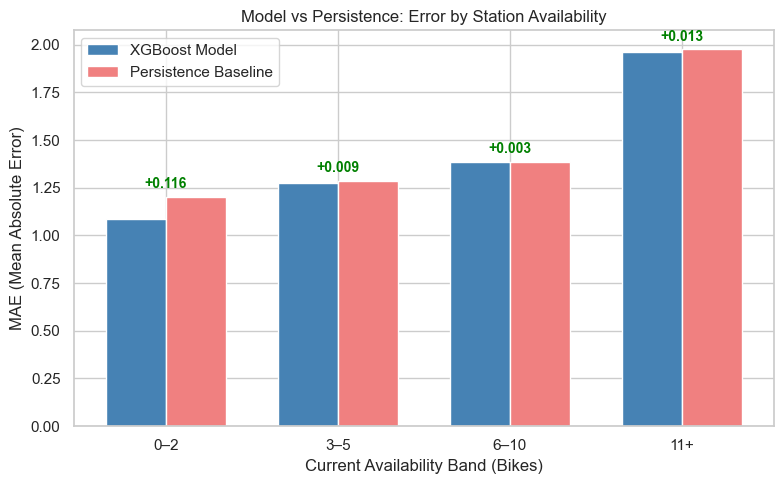

In [296]:
import matplotlib.pyplot as plt
import seaborn as pd
import numpy as np

bands = ['0–2', '3–5', '6–10', '11+']
model_mae = [1.086116, 1.277577, 1.384024, 1.963463]
persist_mae = [1.202075, 1.287038, 1.387241, 1.976347]

x = np.arange(len(bands))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
bars1 = ax.bar(x - width/2, model_mae, width, label='XGBoost Model', color='steelblue')
bars2 = ax.bar(x + width/2, persist_mae, width, label='Persistence Baseline', color='lightcoral')

for i in range(len(bands)):
    diff = persist_mae[i] - model_mae[i]
    ax.text(i, max(model_mae[i], persist_mae[i]) + 0.03, f'+{diff:.3f}',
            ha='center', va='bottom', color='green', fontweight='bold', fontsize=10)

ax.set_xlabel('Current Availability Band (Bikes)')
ax.set_ylabel('MAE (Mean Absolute Error)')
ax.set_title('Model vs Persistence: Error by Station Availability')
ax.set_xticks(x)
ax.set_xticklabels(bands)
ax.legend()
plt.tight_layout()
plt.show()

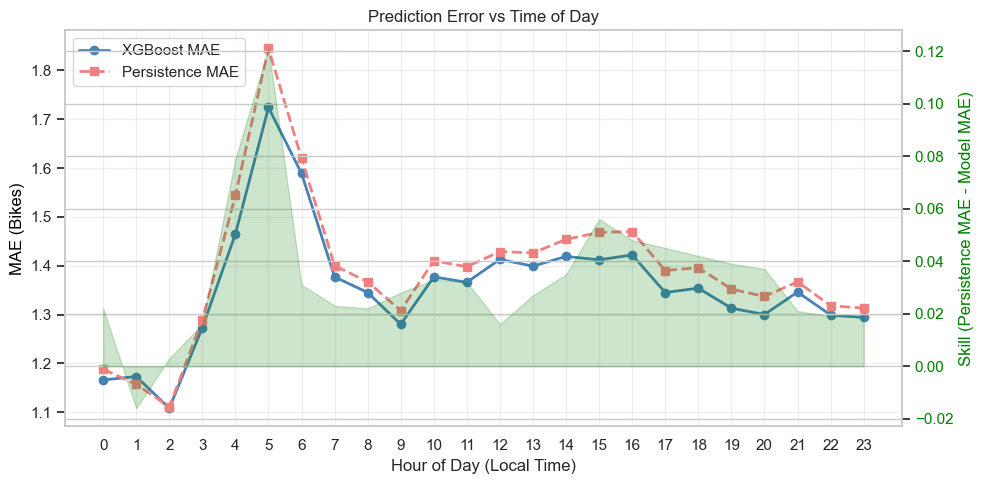

In [297]:
hours = list(range(24))
model_mae_hour = [1.166, 1.173, 1.108, 1.273, 1.465, 1.724, 1.589, 1.377, 1.345, 1.280, 1.377, 1.366,
                  1.413, 1.399, 1.419, 1.412, 1.422, 1.345, 1.354, 1.313, 1.300, 1.346, 1.299, 1.294]
persist_mae_hour = [1.188, 1.157, 1.111, 1.289, 1.544, 1.845, 1.620, 1.400, 1.367, 1.308, 1.410, 1.398,
                    1.429, 1.426, 1.454, 1.468, 1.470, 1.390, 1.396, 1.352, 1.337, 1.367, 1.318, 1.313]

skill = [p - m for p, m in zip(persist_mae_hour, model_mae_hour)]

fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.plot(hours, model_mae_hour, marker='o', label='XGBoost MAE', color='steelblue', linewidth=2)
ax1.plot(hours, persist_mae_hour, marker='s', label='Persistence MAE', color='lightcoral', linestyle='--', linewidth=2)
ax1.set_xlabel('Hour of Day (Local Time)')
ax1.set_ylabel('MAE (Bikes)', color='black')
ax1.set_xticks(hours)
ax1.set_title('Prediction Error vs Time of Day')
ax1.legend(loc='upper left')
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
ax2.fill_between(hours, skill, color='green', alpha=0.2, label='Model Skill (Improvement)')
ax2.set_ylabel('Skill (Persistence MAE - Model MAE)', color='green')
ax2.tick_params(axis='y', labelcolor='green')

plt.tight_layout()
plt.show()